# Murphys Polytechnic Institute: Student Dropout Prediction and Risk-Factor Analysis

This notebook predicts whether a student at Murphys Polytechnic Institute will **drop out, remain enrolled, or graduate**, and explains which academic, financial and demographic factors are linked to dropout. It follows the CRISP-DM framework from business understanding to deployment.

**Key results.** About one in three of the 4,424 students in the data (32.1%) dropped out. Tuition-payment status and the share of first-year course units passed are the strongest dropout signals. After two modelling iterations, the final Random Forest (class-weighted, regularized and tuned with Optuna) flags a student as a dropout when the predicted dropout probability reaches 0.37. On 443 students it had never seen, it catches **76.1% of dropouts** (target: 75%), and **83.7%** of flagged students actually drop out. That beats a simple business rule (66.2% and 83.2%). Overall macro F1 (0.680) stays below its 0.70 target because the unfinished "Enrolled" status is hard to predict (Section 7.8.6). The model and a dashboard dataset power a single Streamlit application in `app/` (started with `streamlit run app/main.py`) that combines an analytics dashboard with the early-warning prediction pages (Section 8.2).

**Roadmap**

| # | Section | CRISP-DM phase | Purpose |
|---|---|---|---|
| 1 | Project Overview | Business Understanding | Context, motivation and references |
| 2 | Business Understanding | Business Understanding | Problems, goals, stakeholders, success criteria, approach |
| 3 | Setup | — | Libraries, version checks and configuration |
| 4 | Data Understanding | Data Understanding | Data source, quality checks and exploratory data analysis (EDA) |
| 5 | Data Preparation | Data Preparation | Feature engineering, cleaning, test design and leakage-safe preprocessing |
| 6 | Modelling | Modeling | Baselines, Random Forest tuning with Optuna and model selection (iteration 1) |
| 7 | Evaluation | Evaluation | Iteration-1 evaluation, then iteration 2 (threshold tuning, class weights) and final assessment |
| 8 | Deployment | Deployment | Exported artifacts, Streamlit app, serving and monitoring |
| 9 | Conclusion & Recommendations | Evaluation (summary) | Answers to the business problems and next actions |

**Deliberate deviations from the standard CRISP-DM order** (each is flagged where it happens):

1. Data-type conversion and column renaming (CRISP-DM *Format* tasks) are done in Section 4.2 so that EDA can treat coded columns as categories.
2. Feature engineering in Section 5.1 includes exploratory charts and insights on the new features (Insights 9–16).
3. Descriptive statistical tests (Section 5.5) run on the full dataset to describe associations; the label-based feature selection is repeated on the training split only (Section 5.8).
4. The log-transform columns (Section 5.4) are chosen from full-data skewness. The rule uses no labels and the transform is stateless, so it cannot leak test-set information.
5. The dashboard CSV is exported in Section 5.2, before model-specific transforms, so the Streamlit dashboard shows values in their original units.
6. CRISP-DM loops back from Evaluation to Modeling: iteration 2 (Section 7.8) re-models after the iteration-1 assessment, selects on cross-validation, and evaluates the final model once more on the test split.

## 1. Project Overview

**Roughly one in three students in this dataset never finishes their degree, and most of the warning signs are visible within the first year.**

Student dropout is a costly problem for higher-education institutions. Each student who leaves represents lost tuition revenue, under-used teaching capacity and, for the student, time and money spent without a qualification. Across OECD countries, only 39% of full-time bachelor's entrants graduate within the theoretical duration of their programme, the completion rate rises to 68% three years later, and 12% of entrants leave tertiary education before the start of their second year (OECD, 2022). In Portugal, where the dataset used here originates, half of the students were still enrolled at the end of the theoretical duration, and the share who had left without a degree grew by a further 8 percentage points over the following three years (OECD, 2022).

Dropout research has long linked persistence to a student's academic and social integration in the institution (Tinto, 1975). In practice, institutions usually notice disengagement only when grades or payments have already failed. Predictive models trained on administrative records can surface these signals earlier, so that tutors and support services can intervene while a student can still be retained (Martins et al., 2021; Realinho et al., 2022).

The polytechnic faces the same challenge. This project uses the public *Predict Students' Dropout and Academic Success* dataset (Realinho et al., 2021), collected at the Polytechnic Institute of Portalegre (Portugal) for students enrolled between 2008/2009 and 2018/2019, as a proxy for the polytechnic's student records. A Random Forest (Breiman, 2001), an ensemble of decision trees that handles mixed numeric and categorical inputs and non-linear effects well, is used to predict each student's final status.

### 1.1 References

**Official and industry reports**

* OECD. (2022). *Education at a glance 2022: OECD indicators*. OECD Publishing. https://doi.org/10.1787/3197152b-en

**Scientific papers**

* Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. In *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining* (pp. 2623–2631). ACM. https://doi.org/10.1145/3292500.3330701
* Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324
* He, H., & Garcia, E. A. (2009). Learning from imbalanced data. *IEEE Transactions on Knowledge and Data Engineering, 21*(9), 1263–1284. https://doi.org/10.1109/TKDE.2008.239
* Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), 1–21. https://doi.org/10.1145/2382577.2382579
* Martins, M. V., Tolledo, D., Machado, J., Baptista, L. M. T., & Realinho, V. (2021). Early prediction of student's performance in higher education: A case study. In *Trends and applications in information systems and technologies* (Advances in Intelligent Systems and Computing, pp. 166–175). Springer. https://doi.org/10.1007/978-3-030-72657-7_16
* Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting student dropout and academic success. *Data, 7*(11), 146. https://doi.org/10.3390/data7110146
* Tinto, V. (1975). Dropout from higher education: A theoretical synthesis of recent research. *Review of Educational Research, 45*(1), 89–125. https://doi.org/10.3102/00346543045001089

**Data and software**

* Dicoding Academy. (n.d.). *Students performance dataset* [Data set]. GitHub. https://github.com/dicodingacademy/dicoding_dataset/tree/main/students_performance
* Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html
* Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). *Predict students' dropout and academic success* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89

## 2. Business Understanding

### 2.1 Problem Statements

1. **The polytechnic cannot identify at-risk students early enough to intervene.** About one in three students in the data dropped out (Section 4.4.2), and dropout is typically recognized only after a student has stopped attending or paying.
   *What is at stake:* lost tuition revenue, lower completion rates, and students leaving without a qualification.
2. **The factors behind dropout are not quantified.** Advisors and support services lack evidence on which academic, financial and demographic signals matter most.
   *What is at stake:* support budgets spent on the wrong students or the wrong type of help.
3. **There is no operational tool for monitoring student status.** Insights live in ad-hoc analyses rather than in a tool that staff can use each semester.
   *What is at stake:* the analysis cannot be repeated or acted on consistently.

### 2.2 Goals

1. Build a Random Forest model that predicts each student's status (Dropout, Enrolled, Graduate) and catches dropouts better than simple rules (criteria **D1, D2, D3**).
2. Identify and rank the factors associated with dropout in terms that staff can act on (criteria **B2, D4**).
3. Deliver one Streamlit application with two parts: an analytics dashboard built on the engineered dataset and a prediction prototype built on the exported pipeline (criteria **B1, B3**).

### 2.3 Situation Assessment

**Stakeholders** *(proposal based on common practice in higher education, since the institution is fictional)*

| Stakeholder | Decision supported | Outputs used |
|---|---|---|
| Academic Affairs leadership (Vice-Rector) | Retention targets, intervention budget, policy on use of sensitive attributes | Streamlit dashboard page, Section 9 summary |
| Academic advisors / tutors | Which students to contact each semester and how | Risk predictions from the Streamlit prediction page |
| Student Financial Services | Payment plans, emergency grants, scholarship outreach | Financial risk factors (Insight 5), app predictions |
| Admissions office & programme directors | Onboarding for high-risk entry routes and courses | Rate tables by application mode and course (Insight 6) |
| Data & IT team | Model maintenance, retraining and monitoring | Notebook, model artifacts, metadata |

**Resources:** one tabular dataset (4,424 students × 37 columns), Python with pandas, scikit-learn, matplotlib and seaborn, and Streamlit for both the analytics dashboard and the prediction prototype.

**Requirements, assumptions and constraints**

* *Prediction point:* the model uses first- and second-semester results, so predictions are made **at the end of the first academic year**, not at enrollment.
* *Label:* status is recorded at the end of the normal course duration (three years; four for Nursing) (Realinho et al., 2022). "Enrolled" therefore means "not yet finished", not a final outcome.
* *Proxy data:* the records come from a Portuguese polytechnic (2008/2009–2018/2019) and stand in for the polytechnic's data. The model must be re-validated on the polytechnic's own records before use.
* *Dropout reason:* the project brief distinguishes voluntary withdrawal from expulsion, but the dataset does not record the reason, so the two cannot be told apart (Section 9.6).
* *Fairness:* gender, marital status and nationality are sensitive attributes. They are analysed descriptively, but their use in individual decisions needs a policy decision by Academic Affairs (Section 9.5).

**Risks and contingencies**

| Risk | Impact | Contingency |
|---|---|---|
| Data leakage (information from the future or from the test set) | Over-optimistic metrics, poor real-world performance | Split before any fitted or label-based step; fit preprocessing inside the pipeline (Kaufman et al., 2012) |
| Class imbalance (fewer Enrolled students) | Model ignores the minority class | Stratified split; undersample the training split only; macro-averaged metrics (He & Garcia, 2009) |
| Financial variables recorded close to the outcome | Leakage if arrears follow the decision to leave | Confirm the recording date with the data owner (Section 9.6) |
| Proxy data differs from the polytechnic's population | Model does not transfer | Re-train and re-validate on the polytechnic's data before use |
| Biased decisions against sensitive groups | Unfair treatment, reputational risk | Review per-group error rates; human review of every flag |

### 2.4 Success Criteria

Criteria are fixed **before modelling**. Numeric targets are proposals based on the benchmarks below; their fit with advisor capacity is reviewed in Section 9.5.

| ID | Type | Criterion | Target |
|---|---|---|---|
| B1 | Business | Advisors receive a ranked list of at-risk students each semester | Pipeline exported and usable by the Streamlit app |
| B2 | Business | Dropout drivers are explained in terms staff recognize (raw input features) | Top factors reported with direction and size |
| B3 | Business | Streamlit dashboard dataset is available in original units | CSV exported and loadable by the app |
| D1 | Data mining | Dropout **recall** on the untouched test split | ≥ 0.75 and higher than the business-rule benchmark |
| D2 | Data mining | **Macro F1** on the test split | ≥ 0.70 and higher than the majority-class benchmark |
| D3 | Data mining | Generalization: gap between mean CV score and test score | ≤ 5 percentage points |
| D4 | Data mining | Permutation importance on raw features is consistent with EDA findings | Top-5 factors match Insights 2 and 5 |

**Benchmarks to beat** (computed on the same test split in Section 7.2):

* *Majority class:* predict "Graduate" for every student.
* *Business rule:* flag a student as a dropout if they passed **no second-semester unit** or have **tuition fees in arrears** (from Insights 2 and 5).

**Metric definitions**

* *Recall (Dropout):* share of actual dropouts that the model flags. Missing an at-risk student is the costliest error, so this is the primary metric.
* *Precision (Dropout):* share of flagged students who actually drop out; low precision wastes advisor time.
* *F1 score:* harmonic mean of precision and recall. *Macro F1* averages F1 over the three classes with equal weight, so the smaller Enrolled class counts as much as the others.
* *Accuracy:* share of all predictions that are correct; reported for completeness but misleading under class imbalance.

### 2.5 Solution Approach

| Approach | Methods | Goal |
|---|---|---|
| Descriptive | EDA with dropout rates per group (Section 4.4); likelihood-ratio and chi-square tests (Section 5.5) | Goal 2 |
| Predictive | Leakage-safe preprocessing pipeline + Random Forest tuned with Optuna (TPE sampler, median pruning) and stratified cross-validation; trials logged to a JSON file (Sections 5–6) | Goal 1 |
| Explanatory | Impurity-based and permutation feature importance (Section 7.4) | Goal 2 |
| Deployment | One Streamlit app: dashboard page on the exported CSV, prediction page on the exported pipeline, target encoder and metadata (Sections 5.2, 8) | Goal 3 |

## 3. Setup

### 3.1 Libraries and Version Checks

All imports are collected in one cell: standard library first, then third-party packages grouped by purpose. The cell stops with a clear message if an installed package is older than the minimum version the code relies on.

In [ ]:
%pip install optuna==5.0

In [ ]:
# --- Standard library ---
import json
import math
import re
import sys
from datetime import UTC, datetime
from importlib.metadata import version
from pathlib import Path

# --- Third-party ---
import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from IPython.display import display
from pandas.api.types import is_numeric_dtype
from scipy.stats import chi2, chi2_contingency
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    get_scorer,
    log_loss,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    LabelEncoder,
    MinMaxScaler,
    OrdinalEncoder,
    StandardScaler,
)

# Stop early with a clear message instead of failing later on a missing API.
MIN_VERSIONS = {
    "numpy": "1.26",
    "pandas": "2.1",
    "scikit-learn": "1.4",
    "seaborn": "0.13",
    "matplotlib": "3.8",
    "optuna": "4.0",
}
if sys.version_info < (3, 11):
    raise RuntimeError("Python >= 3.11 is required (datetime.UTC, typing syntax).")


def _major_minor(version_string: str) -> tuple[int, int]:
    """Return the (major, minor) part of a version string such as '2.2.3'."""
    major, minor = re.match(r"(\d+)\.(\d+)", version_string).groups()
    return int(major), int(minor)


for package, minimum in MIN_VERSIONS.items():
    installed = version(package)
    if _major_minor(installed) < _major_minor(minimum):
        raise ImportError(
            f"{package}>={minimum} is required, but {installed} is installed. "
            f"Run: pip install -U '{package}>={minimum}'"
        )
print({package: version(package) for package in MIN_VERSIONS})

{'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'seaborn': '0.13.2', 'matplotlib': '3.10.0', 'optuna': '5.0.0'}


### 3.2 Configuration

Every constant used in the notebook (seeds, paths, thresholds, column groups and the hyperparameter search space) is defined once here, so a change in one place applies everywhere.

In [ ]:
# --- Reproducibility ---
RANDOM_STATE = 126  # seed for the split, models and tuning
SAMPLING_RANDOM_STATE = 42  # seed for undersampling

# --- Data source ---
DATA_URL = (
    "https://raw.githubusercontent.com/dicodingacademy/dicoding_dataset/"
    "refs/heads/main/students_performance/data.csv"
)
CSV_SEPARATOR = ";"  # the raw file is semicolon-delimited
TARGET = "Status"
POSITIVE_CLASS = "Dropout"  # the class the institute wants to catch early
STATUS_ORDER = ["Dropout", "Enrolled", "Graduate"]
STATUS_PALETTE = {"Dropout": "#d62728", "Enrolled": "#ff7f0e", "Graduate": "#2ca02c"}

# --- Output paths (resolved from the project root) ---
# The notebook lives in notebooks/; elsewhere (e.g. Colab) the current folder is the root.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
MODEL_DIR = ARTIFACTS_DIR / "trained_models"  # files loaded by the Streamlit app
TUNING_DIR = ARTIFACTS_DIR / "tuning"  # Optuna trial logs (experiment records)
MODEL_PATH = MODEL_DIR / "random_forest_pipeline.joblib"
TARGET_ENCODER_PATH = MODEL_DIR / "encoder_target.joblib"
MODEL_METADATA_PATH = MODEL_DIR / "model_metadata.joblib"
TUNING_RESULTS_PATH = TUNING_DIR / "optuna_tuning_results.json"  # flat JSON trial log
# Data source for the Streamlit dashboard page.
DASHBOARD_CSV_PATH = PROJECT_ROOT / "data" / "processed" / "student.csv"

# --- Data understanding ---
# Integer codes that represent categories, not quantities (raw column names).
CATEGORICAL_CODED_COLS = [
    "Marital_status",
    "Application_order",
    "Application_mode",
    "Course",
    "Daytime_evening_attendance",
    "Previous_qualification",
    "Nacionality",
    "Mothers_qualification",
    "Fathers_qualification",
    "Mothers_occupation",
    "Fathers_occupation",
    "Displaced",
    "Educational_special_needs",
    "Debtor",
    "Tuition_fees_up_to_date",
    "Gender",
    "Scholarship_holder",
    "International",
]
COLUMN_RENAMES = {"Nacionality": "Nationality"}  # fix the Portuguese spelling
MIN_CATEGORY_COUNT = 50  # hide tiny groups in rate tables (unstable percentages)

# --- Feature engineering ---
SEMESTER_PREFIXES = {
    "Sem1": "Curricular_units_1st_sem",
    "Sem2": "Curricular_units_2nd_sem",
}
# Previous_qualification_grade is on a 0-200 scale; curricular grades are 0-20.
PREV_QUAL_GRADE_SCALE = 10

# --- Data preparation ---
LOW_CARDINALITY_MAX = 5  # numeric columns with <= 5 unique values act as categories
CORRELATION_THRESHOLD = 0.6  # |r| above this counts as a strong linear relation
MAX_SKEW_THRESHOLD = 0.66  # right skew above this triggers log1p
ALPHA = 0.05  # significance level for statistical tests
STAT_TEST_NUMERIC_FEATURES = [
    "Age_at_enrollment",
    "Overall_approval_rate",
    "Overall_average_grade",
    "Overall_approved_to_credited_ratio",
    "Grade_vs_prev_qual",
    "Change_units_without_evaluations",
]
# Domain-based exclusions decided by the author before modelling.
DROP_COLS = [
    "Application_mode",  # strongly associated (Section 4.4.6); excluded by author
    "Mothers_occupation",  # family background: sensitive, many sparse codes
    "Mothers_qualification",
    "Fathers_qualification",
    "Fathers_occupation",
    "GDP",  # macro indicators: only 10 distinct values, cohort-level proxies
    "Unemployment_rate",
    "Inflation_rate",
]
TEST_SIZE = 0.1  # share of students held out as the untouched test set
UNDERSAMPLE_TRAIN = True  # balance classes in the training split only

# --- Modelling ---
CV_FOLDS = 5
SEARCH_SCORING = "f1_macro"  # treats all three classes equally (criterion D2)

# --- Hyperparameter tuning (Optuna) ---
RUN_TUNING = False  # False: skip the search and reload best params from the JSON file
N_TRIALS = 50  # number of Optuna trials (iteration 1)
OPTUNA_STUDY_NAME = "rf_dropout_status_tuning"
PRUNER_STARTUP_TRIALS = 10  # trials that always run all folds before pruning starts
PRUNER_WARMUP_FOLDS = 1  # folds a trial must finish before it can be pruned
# ("int", low, high) with both ends inclusive, or ("categorical", [choices]).
RF_SEARCH_SPACE = {
    "n_estimators": ("int", 100, 999),
    "max_depth": ("int", 10, 99),
    "max_features": ("categorical", ["sqrt", "log2", None]),
    "min_samples_split": ("int", 2, 19),
    "min_samples_leaf": ("int", 1, 9),
    "bootstrap": ("categorical", [True, False]),
    "criterion": ("categorical", ["gini", "entropy", "log_loss"]),
}
PERMUTATION_REPEATS = 10
TOP_N_FEATURES = 15

# --- Success-criteria targets (Section 2.4) ---
DROPOUT_RECALL_TARGET = 0.75  # D1
MACRO_F1_TARGET = 0.70  # D2
MAX_CV_TEST_GAP = 0.05  # D3 (5 percentage points)

# --- Iteration 2 (Section 7.8) ---
RUN_TUNING_V2 = False  # False: reload best params from TUNING_RESULTS_V2_PATH
N_TRIALS_V2 = 50
OPTUNA_STUDY_NAME_V2 = "rf_dropout_status_tuning_v2"
TUNING_RESULTS_V2_PATH = TUNING_DIR / "optuna_tuning_results_v2.json"
# Features with no added value in the LR test, permutation importance or EDA
# (Insights 12 and 15).
FEATURES_TO_DROP_V2 = [
    "Change_units_without_evaluations",
    "Sem1_approved_to_credited_ratio",
    "Sem2_approved_to_credited_ratio",
    "Overall_approved_to_credited_ratio",
]
# Regularized space (larger leaves, shallower trees) + class weights, which
# replace undersampling so that all training students are used.
RF_SEARCH_SPACE_V2 = {
    "n_estimators": ("int", 200, 600),
    "max_depth": ("int", 5, 30),
    "max_features": ("categorical", ["sqrt", "log2", 0.5]),
    "min_samples_split": ("int", 2, 40),
    "min_samples_leaf": ("int", 3, 20),
    "criterion": ("categorical", ["gini", "entropy", "log_loss"]),
    "class_weight": ("categorical", ["balanced", "balanced_subsample", None]),
}
# Candidate probability cut-offs for flagging a student as a dropout.
THRESHOLD_GRID = np.round(np.arange(0.20, 0.61, 0.01), 2)

## 4. Data Understanding

### 4.1 Data Acquisition

| Dataset | Granularity | Rows | Columns | Content |
|---|---|---|---|---|
| Students performance (Dicoding mirror of Realinho et al., 2021; CC BY 4.0) | One row per student | 4,424 | 37 | Enrollment data (application mode, course, prior qualification), demographics, family background, financial status, first- and second-semester academic results, three macroeconomic indicators, and the target `Status` |

The file is read directly from the Dicoding GitHub mirror. It is semicolon-delimited, hence `sep=";"`.

In [ ]:
# No try/except here: if the download fails, every later cell would break
# anyway, so the original error message is the most useful output.
student_data = pd.read_csv(DATA_URL, sep=CSV_SEPARATOR)
print(f"Loaded {student_data.shape[0]:,} rows x {student_data.shape[1]} columns.")

Loaded 4,424 rows x 37 columns.


### 4.2 Data Description

The first check is the data type of each column, to confirm that pandas interprets every variable correctly.

In [ ]:
display(student_data.dtypes)

,0
Marital_status,int64
Application_mode,int64
Application_order,int64
Course,int64
Daytime_evening_attendance,int64
Previous_qualification,int64
Previous_qualification_grade,float64
Nacionality,int64
Mothers_qualification,int64
Fathers_qualification,int64


Many columns are stored as integers even though they are **codes for categories**, for example `Course` (9500 = Nursing), `Marital_status` (1 = single, 2 = married) or `Gender` (1 = male, 0 = female) (Realinho et al., 2022). Averaging such codes is meaningless, so they are converted to the `object` type. *(Deviation 1: a CRISP-DM Format task executed early to support EDA.)*

In [ ]:
# Codes such as Course = 9500 are labels, not quantities. Storing them as
# `object` stops pandas from averaging them and marks them as categories.
missing_cols = sorted(set(CATEGORICAL_CODED_COLS) - set(student_data.columns))
if missing_cols:
    raise KeyError(f"Expected categorical columns not found: {missing_cols}")

student_data[CATEGORICAL_CODED_COLS] = student_data[CATEGORICAL_CODED_COLS].astype(
    "object"
)

The column `Nacionality` uses the Portuguese spelling; it is renamed to `Nationality` so that all column names are in English.

In [ ]:
student_data = student_data.rename(columns=COLUMN_RENAMES)
print(f"Renamed columns: {COLUMN_RENAMES}")

Renamed columns: {'Nacionality': 'Nationality'}


Re-checking the data types after the conversion:

In [ ]:
display(student_data.dtypes)

,0
Marital_status,object
Application_mode,object
Application_order,object
Course,object
Daytime_evening_attendance,object
Previous_qualification,object
Previous_qualification_grade,float64
Nationality,object
Mothers_qualification,object
Fathers_qualification,object


### 4.3 Data Quality Verification

The next checks cover the dataset size, missing values and fully duplicated rows.

In [ ]:
n_rows, n_cols = student_data.shape
print(f"The DataFrame has {n_cols} columns and {n_rows:,} rows.")
print(f"Missing values: {student_data.isna().sum().sum()}")
print(f"Fully duplicated rows: {student_data.duplicated().sum()}\n")
display(student_data)

The DataFrame has 37 columns and 4,424 rows.
Missing values: 0
Fully duplicated rows: 0



,Marital_status,Application_mode,Application_order,Course,Daytime_evening_attendance,Previous_qualification,Previous_qualification_grade,Nationality,Mothers_qualification,Fathers_qualification,...,Curricular_units_2nd_sem_credited,Curricular_units_2nd_sem_enrolled,Curricular_units_2nd_sem_evaluations,Curricular_units_2nd_sem_approved,Curricular_units_2nd_sem_grade,Curricular_units_2nd_sem_without_evaluations,Unemployment_rate,Inflation_rate,GDP,Status
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1,1,6,9773,1,1,125.0,1,1,1,...,0,6,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1,2,9773,1,1,120.0,105,1,1,...,0,6,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1,1,9500,1,1,154.0,1,37,37,...,0,8,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1,1,9147,1,1,180.0,1,37,37,...,0,5,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate


The data contain **37 columns and 4,424 rows, with no missing values and no fully duplicated rows**, so no imputation or de-duplication is needed.

Summary statistics for the numeric variables:

In [ ]:
student_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Previous_qualification_grade,4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Admission_grade,4424.0,126.978119,14.482001,95.00,117.90,126.100000,134.800000,190.000000
Age_at_enrollment,4424.0,23.265145,7.587816,17.00,19.00,20.000000,25.000000,70.000000
Curricular_units_1st_sem_credited,4424.0,0.709991,2.360507,0.00,0.00,0.000000,0.000000,20.000000
Curricular_units_1st_sem_enrolled,4424.0,6.270570,2.480178,0.00,5.00,6.000000,7.000000,26.000000
Curricular_units_1st_sem_evaluations,4424.0,8.299051,4.179106,0.00,6.00,8.000000,10.000000,45.000000
Curricular_units_1st_sem_approved,4424.0,4.706600,3.094238,0.00,3.00,5.000000,6.000000,26.000000
Curricular_units_1st_sem_grade,4424.0,10.640822,4.843663,0.00,11.00,12.285714,13.400000,18.875000
Curricular_units_1st_sem_without_evaluations,4424.0,0.137658,0.690880,0.00,0.00,0.000000,0.000000,12.000000
Curricular_units_2nd_sem_credited,4424.0,0.541817,1.918546,0.00,0.00,0.000000,0.000000,19.000000


Two patterns stand out. Grades use **two different scales**: `Previous_qualification_grade` and `Admission_grade` range from 95 to 190 (a 0–200 scale), while semester grades range from 0 to about 19 (a 0–20 scale). Count variables such as `Curricular_units_1st_sem_credited` and `..._without_evaluations` have a median of 0 and long right tails, so most students have none and a few have many. Both patterns matter later (Insights 2 and 14).

Frequency summary for the categorical variables:

In [ ]:
# ["object", "string"] also catches the default text dtype of pandas >= 3.0.
categorical_cols = student_data.select_dtypes(include=["object", "string"]).columns
category_frequencies = pd.concat(
    [
        student_data[col]
        .value_counts()
        .rename_axis("Unique Value")
        .reset_index(name="Frequency")
        .assign(Variable=col)
        for col in categorical_cols
    ],
    ignore_index=True,
)
display(student_data[categorical_cols].describe())
display(category_frequencies)

,Marital_status,Application_mode,Application_order,Course,Daytime_evening_attendance,Previous_qualification,Nationality,Mothers_qualification,Fathers_qualification,Mothers_occupation,Fathers_occupation,Displaced,Educational_special_needs,Debtor,Tuition_fees_up_to_date,Gender,Scholarship_holder,International,Status
count,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424,4424
unique,6,18,8,17,2,17,21,29,34,32,46,2,2,2,2,2,2,2,3
top,1,1,1,9500,1,1,1,1,37,9,9,1,0,0,1,0,0,0,Graduate
freq,3919,1708,3026,766,3941,3717,4314,1069,1209,1577,1010,2426,4373,3921,3896,2868,3325,4314,2209


,Unique Value,Frequency,Variable
0,1,3919,Marital_status
1,2,379,Marital_status
2,4,91,Marital_status
3,5,25,Marital_status
4,6,6,Marital_status
...,...,...,...
242,0,4314,International
243,1,110,International
244,Graduate,2209,Status
245,Dropout,1421,Status


Several categorical variables are dominated by one code: 3,919 of 4,424 students are single (`Marital_status` = 1) and 4,314 are not international students. Others, such as the parents' qualification and occupation, have dozens of codes with very few students each. Sparse codes make group comparisons unstable, which is why later rate tables hide groups with fewer than 50 students.

### 4.4 Exploratory Data Analysis (EDA)

EDA answers the following questions, each linked to a goal from Section 2.2:

| # | Question | Goal |
|---|---|---|
| Q1 | How large is the dropout problem and how balanced are the classes? | 1 |
| Q2 | Which academic indicators separate dropouts from other students? | 1, 2 |
| Q3 | Are demographic and family-background factors related to dropout? | 2 |
| Q4 | Does age at enrollment matter? | 2 |
| Q5 | How are financial factors related to dropout? | 2 |
| Q6 | Do application route and course matter? | 2 |
| Q7 | Do macroeconomic conditions matter? | 2 |
| Q8 | Do displacement and special educational needs matter? | 2 |

#### 4.4.1 Helper Functions

Reusable plotting and summary functions keep each EDA cell short and every chart consistent (same status order and colors everywhere). `dropout_rate_table` converts raw counts into dropout rates, because counts mainly reflect how large a group is.

In [ ]:
def _subplot_grid(
    n_plots: int, n_cols: int, row_height: float, width: float
) -> tuple[plt.Figure, list[plt.Axes]]:
    """Create a grid of subplots and return the figure plus a flat list of axes.

    Unused axes (when ``n_plots`` does not fill the last row) are removed so
    the figure has no empty panels.
    """
    n_cols = min(n_cols, n_plots)
    n_rows = math.ceil(n_plots / n_cols)
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(width, max(row_height, n_rows * row_height)),
        squeeze=False,
    )
    flat_axes = list(axes.ravel())
    for ax in flat_axes[n_plots:]:
        fig.delaxes(ax)
    return fig, flat_axes[:n_plots]


def plot_status_distribution(
    df: pd.DataFrame, ax: plt.Axes, target: str = TARGET
) -> plt.Axes:
    """Draw a bar chart of student counts per status, highlighting dropouts.

    Counts are re-indexed to ``STATUS_ORDER`` before plotting, so each bar is
    always paired with its correct label.

    Args:
        df: Data containing the target column.
        ax: Matplotlib axes to draw on.
        target: Name of the status column.

    Returns:
        The axes with the chart.
    """
    counts = df[target].value_counts().reindex(STATUS_ORDER)
    shares = counts / counts.sum()
    colors = ["#d62728" if s == POSITIVE_CLASS else "gray" for s in counts.index]
    bars = ax.bar(counts.index, counts.to_numpy(), color=colors)
    ax.bar_label(
        bars, labels=[f"{n:,}\n({p:.1%})" for n, p in zip(counts, shares, strict=True)]
    )
    ax.set_title("Distribution of Student Status")
    ax.set_xlabel("Status")
    ax.set_ylabel("Number of students")
    ax.margins(y=0.15)
    return ax


def plot_boxplots_by_target(
    df: pd.DataFrame,
    columns: list[str],
    target: str = TARGET,
    n_cols: int = 2,
    row_height: float = 4.0,
) -> None:
    """Draw one box plot per numeric column, split by student status.

    A box plot shows the median (middle line), the interquartile range (box:
    the middle 50% of students) and points beyond 1.5 x IQR as dots.

    Args:
        df: Data containing ``columns`` and ``target``.
        columns: Numeric columns to plot.
        target: Categorical column used on the x-axis.
        n_cols: Number of panels per row.
        row_height: Height of each row of panels, in inches.
    """
    fig, axes = _subplot_grid(len(columns), n_cols, row_height, width=12)
    for ax, col in zip(axes, columns, strict=True):
        sns.boxplot(
            data=df,
            x=target,
            y=col,
            hue=target,
            order=STATUS_ORDER,
            hue_order=STATUS_ORDER,
            palette=STATUS_PALETTE,
            legend=False,
            ax=ax,
        )
        ax.set_title(f"{col} by {target}")
        ax.set_xlabel(target)
        ax.set_ylabel(col)
    fig.tight_layout()
    plt.show()


def plot_stacked_bars_by_target(
    df: pd.DataFrame,
    columns: list[str],
    target: str = TARGET,
    n_cols: int = 2,
    row_height: float = 5.0,
) -> None:
    """Draw one stacked bar chart of student counts per category and status.

    Stacked counts show where most students are, but large groups dominate
    visually; read them together with ``dropout_rate_table`` to compare risk.

    Args:
        df: Data containing ``columns`` and ``target``.
        columns: Categorical columns to plot on the x-axis.
        target: Column used to stack the bars.
        n_cols: Number of panels per row.
        row_height: Height of each row of panels, in inches.
    """
    fig, axes = _subplot_grid(len(columns), n_cols, row_height, width=14)
    for ax, col in zip(axes, columns, strict=True):
        counts = pd.crosstab(df[col], df[target]).reindex(columns=STATUS_ORDER)
        counts.plot(
            kind="bar",
            stacked=True,
            ax=ax,
            color=[STATUS_PALETTE[s] for s in STATUS_ORDER],
        )
        ax.set_title(f"Distribution of {col} by {target}")
        ax.set_xlabel(col)
        ax.set_ylabel("Count")
        ax.legend(title=target)
        ax.tick_params(axis="x", labelrotation=45)
    fig.tight_layout()
    plt.show()


def dropout_rate_table(
    df: pd.DataFrame,
    columns: list[str],
    target: str = TARGET,
    positive: str = POSITIVE_CLASS,
    min_count: int = MIN_CATEGORY_COUNT,
) -> pd.DataFrame:
    """Compute the dropout rate and lift for every category of each column.

    Raw counts mostly reflect group size; the rate (dropouts / students in the
    group) shows risk. Lift compares that rate with the overall dropout rate
    (lift 2.0 = twice as likely to drop out as the average student).

    Args:
        df: Data containing ``columns`` and ``target``.
        columns: Categorical columns to summarize.
        target: Status column.
        positive: Status value counted as the event of interest.
        min_count: Groups smaller than this are omitted as unstable.

    Returns:
        Long table with one row per (variable, category), sorted by lift.
    """
    is_positive = df[target].eq(positive)
    overall_rate = is_positive.mean()
    tables = []
    for col in columns:
        grouped = is_positive.groupby(df[col], observed=True).agg(["size", "mean"])
        tables.append(
            grouped.rename(columns={"size": "Students", "mean": "Dropout_rate"})
            .rename_axis("Category")
            .reset_index()
            .assign(Variable=col)
        )
    rates = pd.concat(tables, ignore_index=True)
    rates["Lift"] = rates["Dropout_rate"] / overall_rate
    rates = rates[rates["Students"] >= min_count]
    return rates[
        ["Variable", "Category", "Students", "Dropout_rate", "Lift"]
    ].sort_values(["Variable", "Lift"], ascending=[True, False], ignore_index=True)

#### 4.4.2 Target Distribution (Q1)

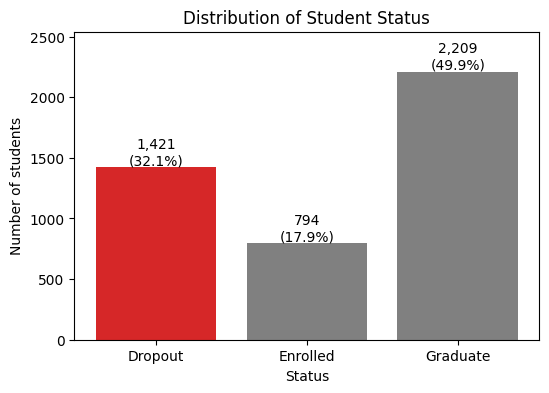

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
plot_status_distribution(student_data, ax=ax)
plt.show()

**Insight 1: About one in three students dropped out; classes are moderately imbalanced.**

* **Finding.** Of 4,424 students, 2,209 graduated (49.9%), 1,421 dropped out (32.1%) and 794 were still enrolled (17.9%).
* **Fact check.** The dropout share is plausible for this population: across the OECD, only 68% of bachelor's entrants complete within the theoretical duration plus three years (OECD, 2022). The figures are not directly comparable, because the label here is measured at the end of the normal course duration at a single institution.
* **Caveats.** "Enrolled" is not a final outcome; some of these students will still drop out or graduate later.
* **Modeling implication.** The imbalance calls for a stratified split, balancing of the training split only, and macro-averaged metrics (Sections 2.4 and 5.7–5.9).

#### 4.4.3 Academic Performance and Engagement (Q2)

Box plots compare the distribution of each academic metric across the three status groups.

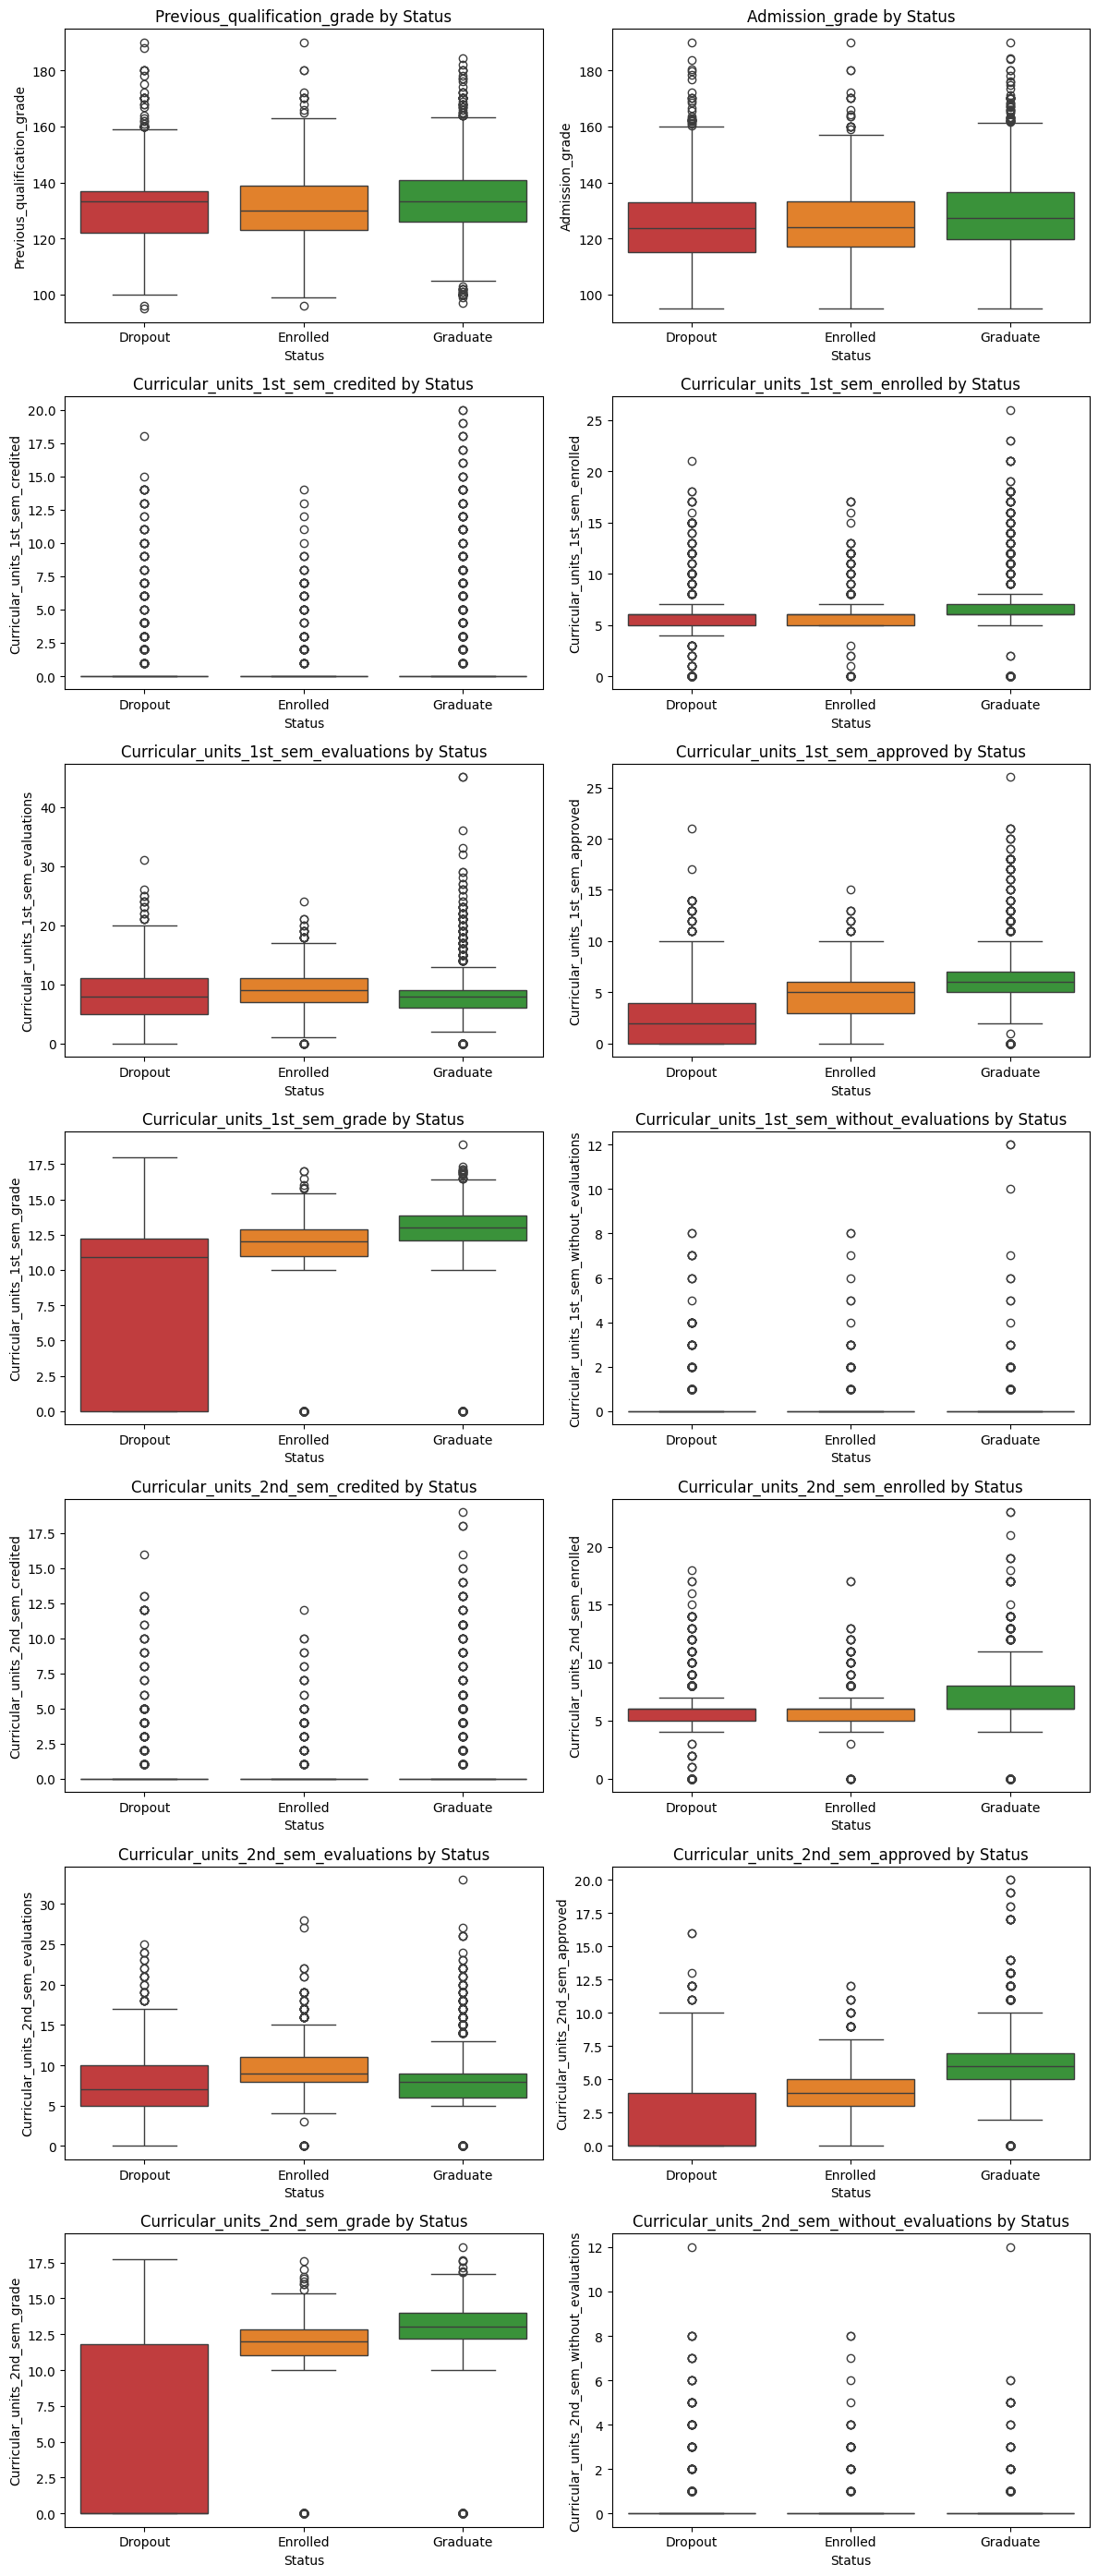

In [ ]:
performance_engagement_cols = [
    "Previous_qualification_grade",
    "Admission_grade",
    "Curricular_units_1st_sem_credited",
    "Curricular_units_1st_sem_enrolled",
    "Curricular_units_1st_sem_evaluations",
    "Curricular_units_1st_sem_approved",
    "Curricular_units_1st_sem_grade",
    "Curricular_units_1st_sem_without_evaluations",
    "Curricular_units_2nd_sem_credited",
    "Curricular_units_2nd_sem_enrolled",
    "Curricular_units_2nd_sem_evaluations",
    "Curricular_units_2nd_sem_approved",
    "Curricular_units_2nd_sem_grade",
    "Curricular_units_2nd_sem_without_evaluations",
]
plot_boxplots_by_target(student_data, performance_engagement_cols)

**Insight 2: First-year academic progress, in both semesters, is the clearest dropout signal; prior grades are not.**

* **Finding.** Dropouts pass far fewer units. The median number of approved units is 2 for Dropouts vs. 6 for Graduates (5 for Enrolled) in semester 1, and 0 vs. 6 (4 for Enrolled) in semester 2. About 40% of dropouts passed no unit in semester 1 and 51% passed none in semester 2. The semester-2 grade median is 0 for Dropouts vs. 13 for Graduates. Admission and previous-qualification grades overlap heavily (admission-grade medians 123.6 vs. 127.4). *(Exact quartiles computed from the same dataset.)*
* **Caveats.** A grade of 0 often means a student stopped attending, so low second-semester results may be a *symptom* of a dropout decision already taken rather than its cause. Credited units and units without evaluation are 0 for most students, so their boxes collapse to a line; the dots are valid values rather than errors, and Random Forest is robust to them, so no outlier removal is needed.
* **Follow-up check.** Compare model performance using semester-1 features only, to measure how early a useful prediction is possible.
* **Modeling/business implication.** Approval rates and grade averages are engineered from these counts (Section 5.1). An early-warning review at the end of semester 1 is feasible.

#### 4.4.4 Demographics and Family Background (Q3)

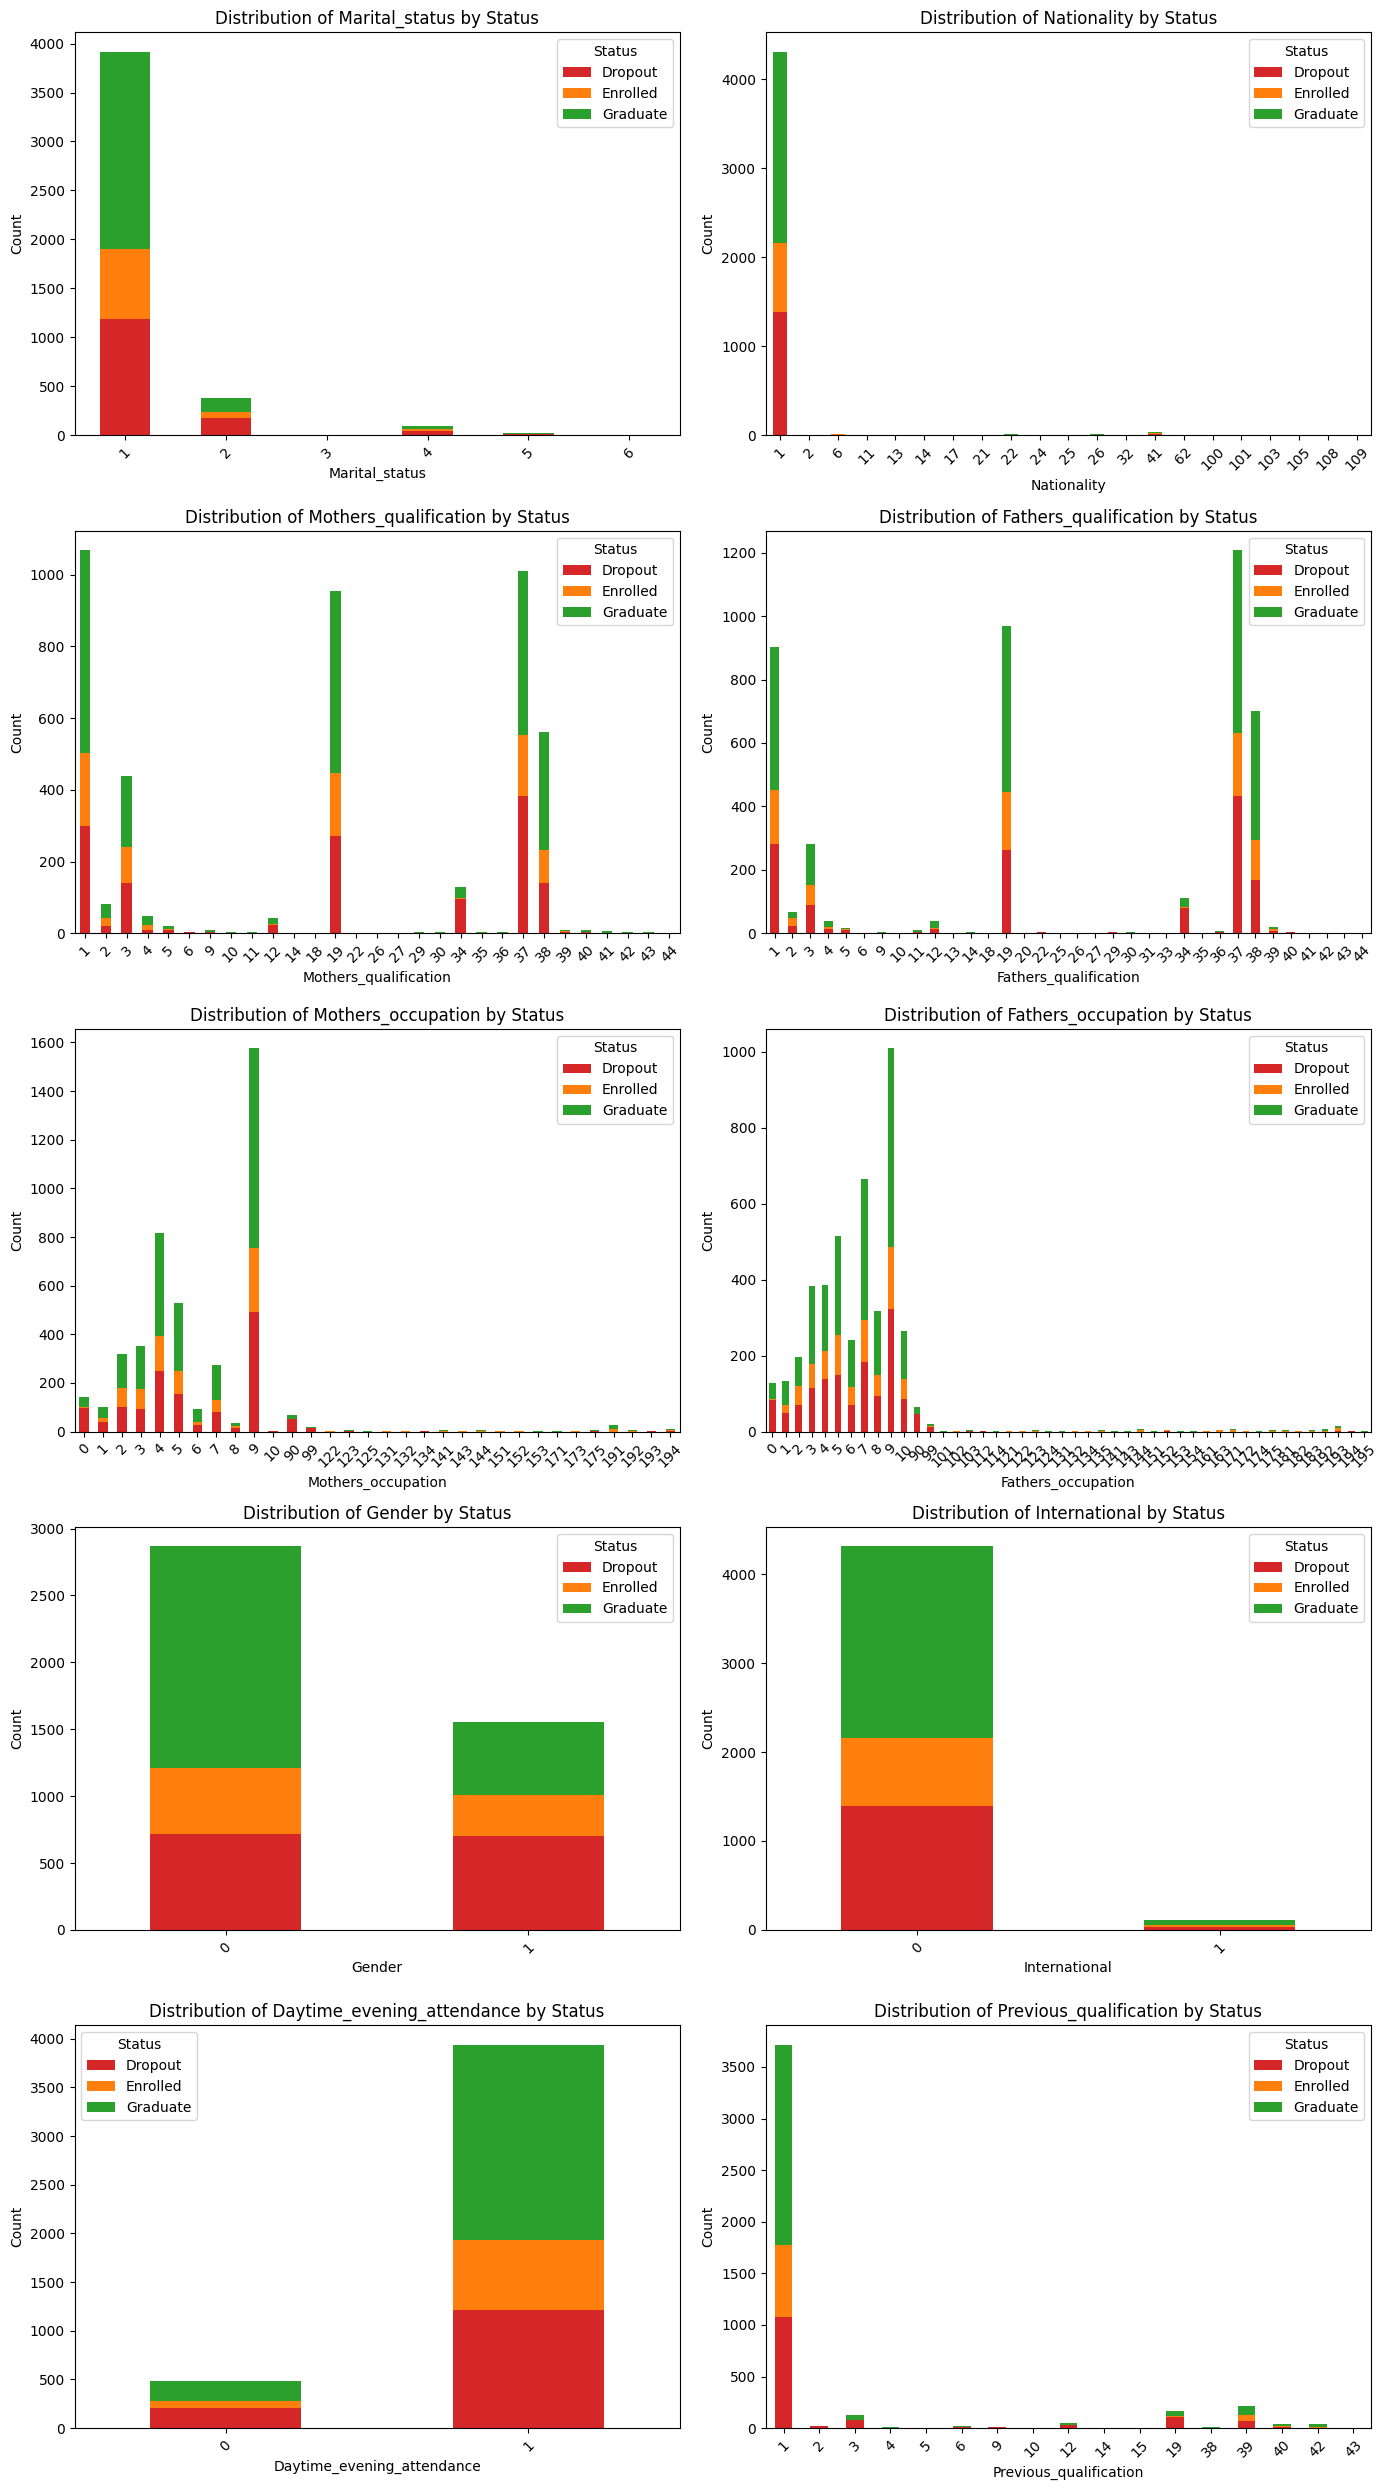

In [ ]:
demographic_cat_cols = [
    "Marital_status",
    "Nationality",
    "Mothers_qualification",
    "Fathers_qualification",
    "Mothers_occupation",
    "Fathers_occupation",
    "Gender",
    "International",
    "Daytime_evening_attendance",
    "Previous_qualification",
]
plot_stacked_bars_by_target(student_data, demographic_cat_cols)

**Insight 3: Large groups dominate the counts, but dropout *rates* are higher for male, married and evening students.**

* **Finding.** The stacked bars are dominated by the largest groups (single, Portuguese, daytime, non-international students), so most dropouts naturally fall in those groups. The rate table in Section 4.4.10 gives a different picture: the dropout rate is 45.1% for male students vs. 25.1% for female students, 47.2% for married vs. 30.2% for single students, and 42.9% for evening vs. 30.8% for daytime attendance. International students (29.1%, n = 110) do not differ from domestic students (32.2%).
* **Caveats.** These groups overlap: gender is linked to course choice (for example, Nursing has a low dropout rate of 15.4%), and evening attendance is linked to older, working students (Insight 4). The rates are associations, not causes. Parents' qualification and occupation have many sparse codes, so their charts are hard to read.
* **Modeling/business implication.** Gender and marital status carry signal (chi-square, Section 5.5.2) but are sensitive attributes; their use in individual decisions needs a policy decision (Section 2.3).

#### 4.4.5 Age at Enrollment (Q4)

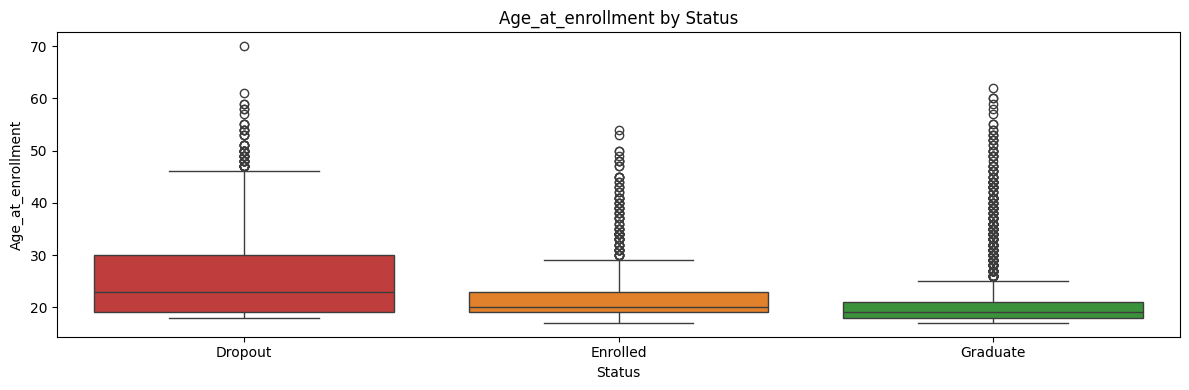

In [ ]:
plot_boxplots_by_target(student_data, ["Age_at_enrollment"], n_cols=1)

**Insight 4: Dropouts enroll older, but half of them are 23 or younger.**

* **Finding.** The median age at enrollment is 23 for Dropouts (interquartile range 19–30), 20 for Enrolled students (19–23) and 19 for Graduates (18–21). Only the upper quarter of dropouts is above 30. The many dots among Graduates are older graduates who are rare *within that group*, not data errors.
* **Caveats.** Age overlaps with the "Over 23 years old" application route (55.4% dropout rate, Insight 6) and with evening attendance. A plausible explanation is competing work and family commitments, but this is a hypothesis the data cannot test.
* **Modeling/business implication.** Age is one of the three strongest predictors in the final model (Section 7.4); mature-student support (flexible scheduling, onboarding) is a candidate intervention for Admissions.

#### 4.4.6 Financial Status (Q5)

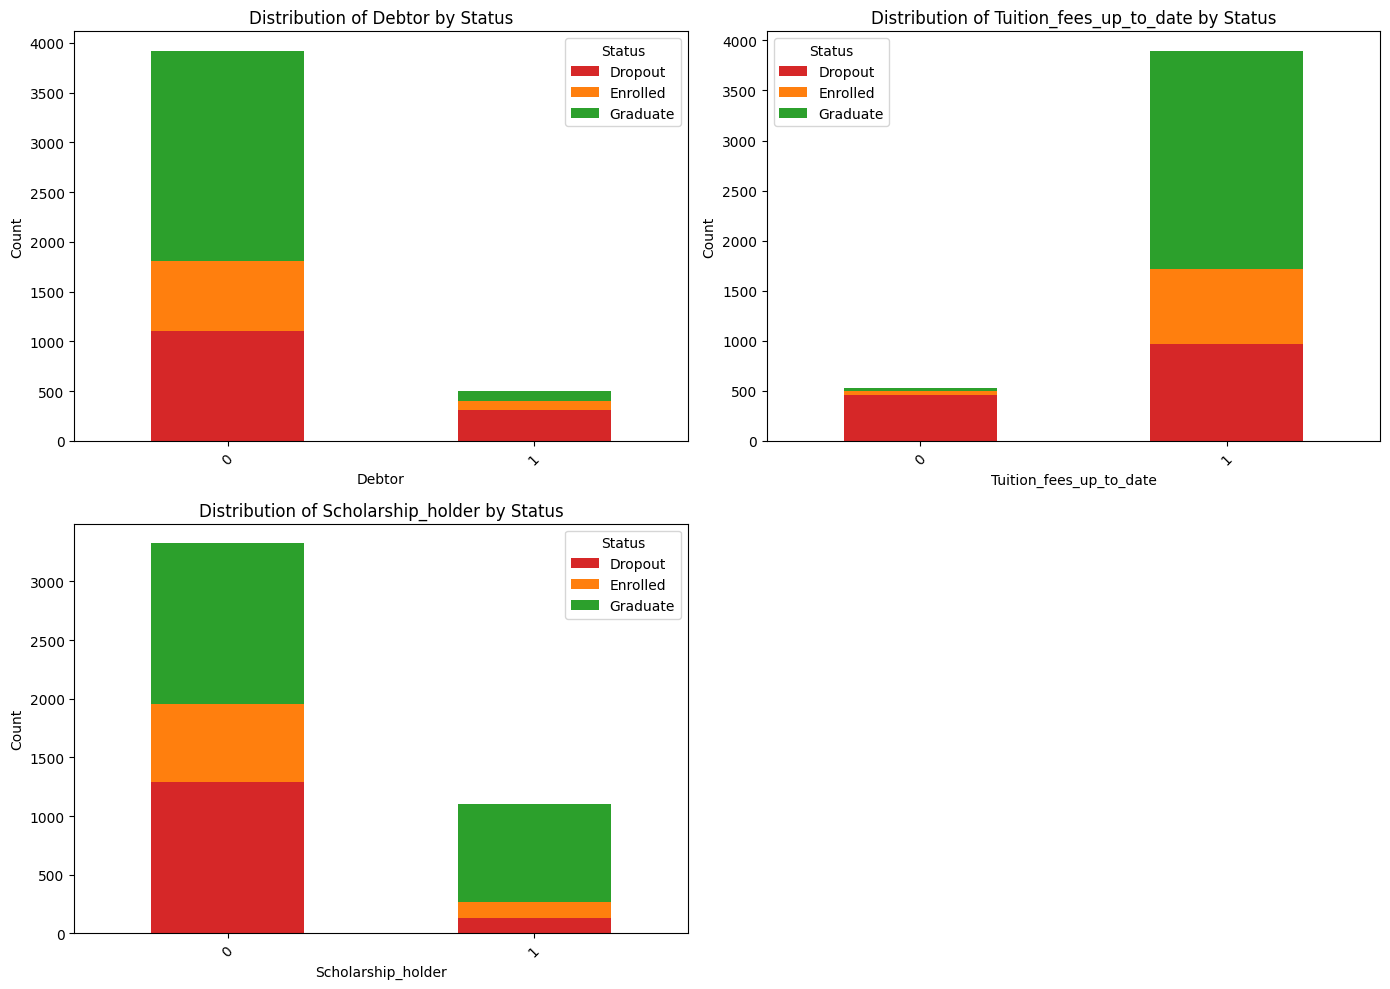

In [ ]:
financial_features = ["Debtor", "Tuition_fees_up_to_date", "Scholarship_holder"]
plot_stacked_bars_by_target(student_data, financial_features)

**Insight 5: Financial status is a strong risk marker once counts are converted into rates.**

* **Finding.** Students with tuition fees **not** up to date drop out at 86.6% (n = 528) vs. 24.7% for those who are up to date, a lift of 2.69. Debtors drop out at 62.0% (n = 503) vs. 28.3%. Scholarship holders drop out at only 12.2% (n = 1,099) vs. 38.7% for non-holders (Section 4.4.10). In the stacked chart, the small "arrears" and "debtor" bars are mostly red (Dropout), which the raw counts alone hide.
* **Caveats.** The dataset does not document *when* the financial status was recorded. If fees stop being paid after a student has decided to leave, `Tuition_fees_up_to_date` partly describes the outcome rather than predicting it (target leakage; Kaufman et al., 2012). The scholarship effect may also reflect selection: scholarships are often awarded to stronger students.
* **Follow-up check.** Confirm with the registrar the date on which financial variables are captured relative to the end of the first year. This matters because tuition status is the single most important feature in the final model (Section 7.4).
* **Modeling/business implication.** Financial status is the most actionable lever for Student Financial Services (payment plans, emergency grants), provided the timing check confirms it is known before dropout.

#### 4.4.7 Application Route and Course (Q6)

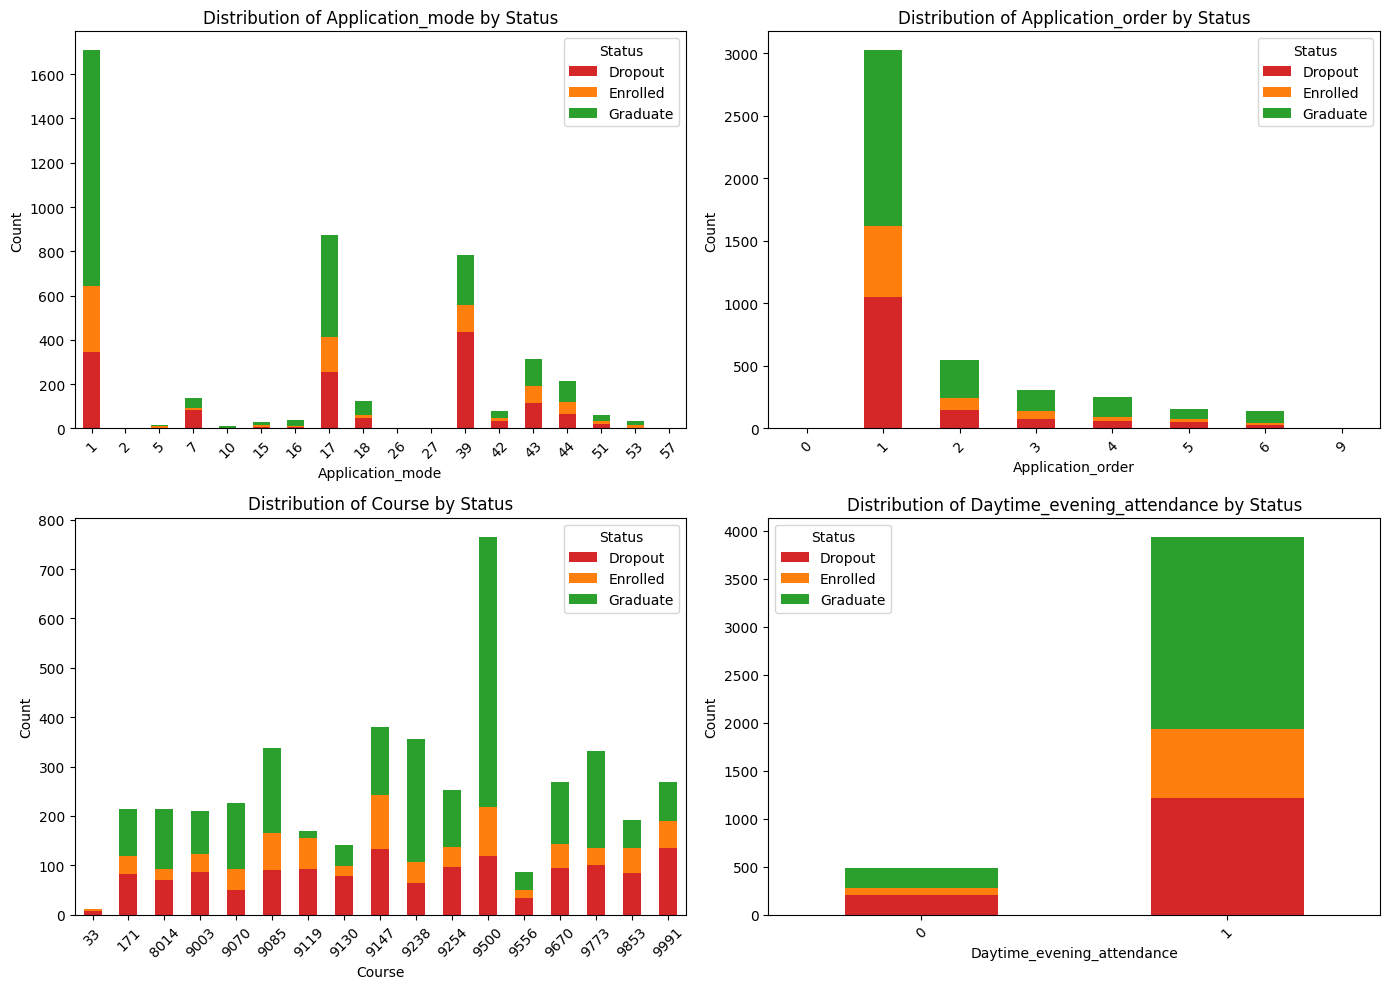

In [ ]:
application_enrollment_features = [
    "Application_mode",
    "Application_order",
    "Course",
    "Daytime_evening_attendance",
]
plot_stacked_bars_by_target(student_data, application_enrollment_features)

**Insight 6: Dropout risk varies widely by entry route and course.**

* **Finding.** By application mode, dropout rates are 61.2% for holders of other higher-education courses (mode 7, n = 139) and 55.4% for the "Over 23 years old" route (mode 39, n = 785), vs. 20.2% for the first-phase general contingent (mode 1). By course, the highest rates are in Equinculture (55.3%), Informatics Engineering (54.1%) and Management, evening attendance (50.7%); the lowest are in Nursing (15.4%) and Social Service (18.3%). Larger categories have more dropouts simply because they have more students; the rates show where risk is concentrated.
* **Caveats.** Application order shows a counter-intuitive pattern (first-choice applicants: 34.8% vs. 22–27% for later choices); this may reflect the mix of entry routes among first-choice applicants and should not be read as causal.
* **Modeling/business implication.** Course is kept as a feature. `Application_mode` is strongly associated with dropout but is excluded by the author (Section 5.6); this choice should be revisited, as noted in `DROP_COLS`.

#### 4.4.8 Macroeconomic Conditions (Q7)

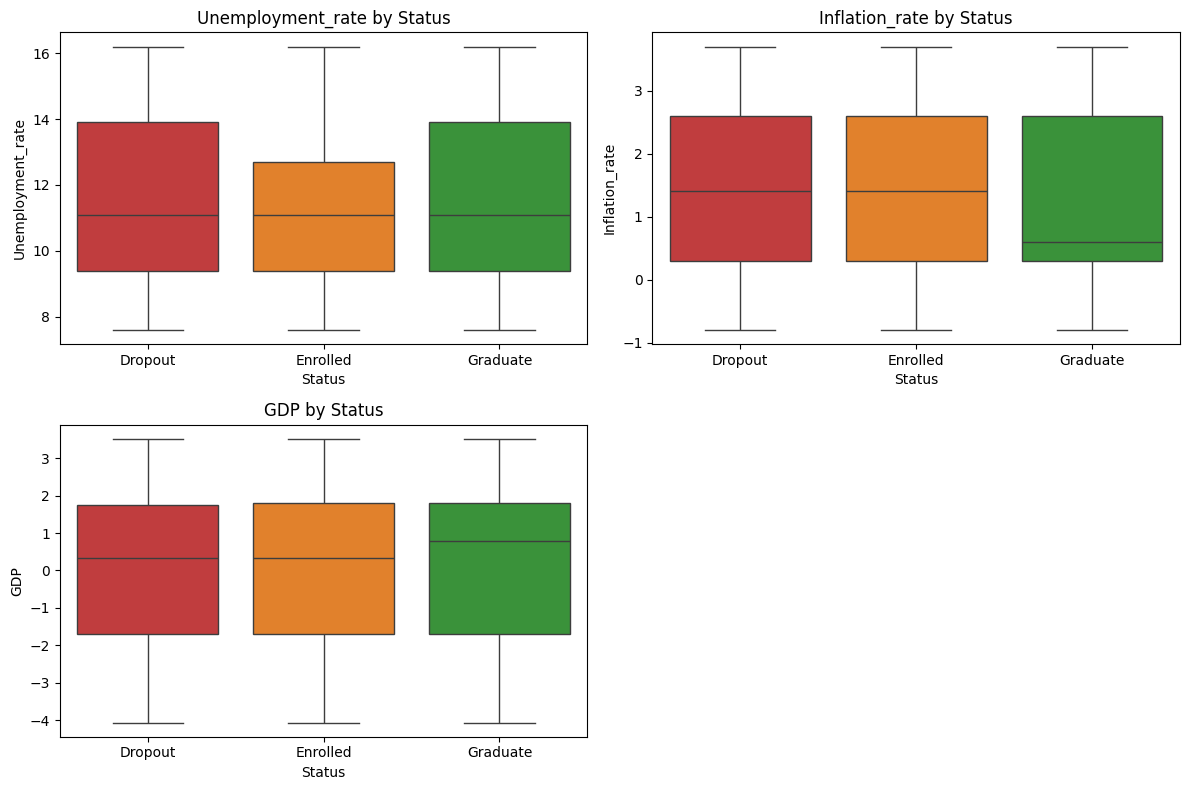

Distinct (unemployment, inflation, GDP) combinations: 10


In [ ]:
external_features = ["Unemployment_rate", "Inflation_rate", "GDP"]
plot_boxplots_by_target(student_data, external_features)
# Each macro indicator is one value per enrollment cohort, not per student.
print(
    "Distinct (unemployment, inflation, GDP) combinations:",
    student_data[external_features].drop_duplicates().shape[0],
)

**Insight 7: The macroeconomic indicators describe enrollment cohorts, not individual students.**

* **Finding.** Unemployment has the same median (11.1%) for all three groups. Inflation (median 1.4% for Dropouts and Enrolled vs. 0.6% for Graduates) and GDP growth (0.32 vs. 0.79) differ in their medians. The three indicators take only **10 distinct combinations** across 4,424 students.
* **Fact check.** The source paper states that these indicators were collected from PORDATA (Realinho et al., 2022), so each combination corresponds to an enrollment cohort, not to a student's own circumstances.
* **Caveats.** With about ten distinct values, the box plots mainly show which cohorts each group belongs to; differences in spread are not meaningful. Differences in medians may reflect cohort composition (for example, more recent cohorts still being enrolled) rather than an economic effect.
* **Modeling implication.** These variables are not actionable for an individual student and act as cohort proxies, which supports dropping them (Section 5.6).

#### 4.4.9 Displacement and Special Educational Needs (Q8)

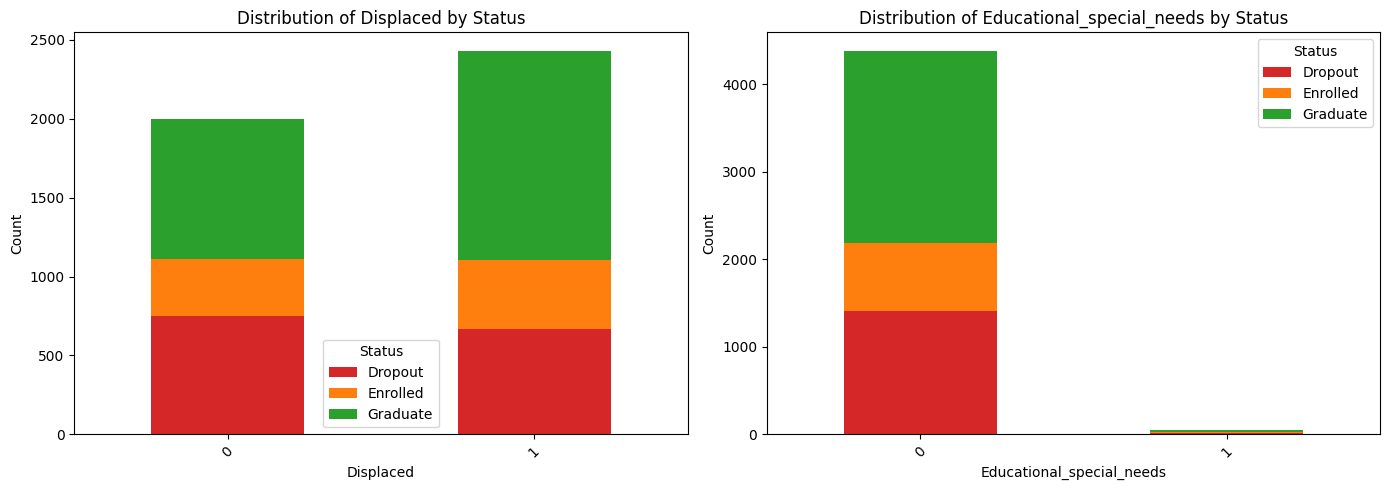

In [ ]:
special_needs_features = ["Displaced", "Educational_special_needs"]
plot_stacked_bars_by_target(student_data, special_needs_features)

**Insight 8: Displaced students drop out *less*; special educational needs show no difference.**

* **Finding.** The dropout rate is 27.6% for displaced students (living away from home to study) vs. 37.6% for non-displaced students. Students with special educational needs drop out at 33.3% (n = 51) vs. 32.1%.
* **Caveats.** The displacement effect is counter-intuitive and may be confounded with age and entry route: mature "Over 23" entrants are likely to live locally. The special-needs group is too small for a reliable comparison; the chi-square test finds no significant association (p = 0.73, Section 5.5.2).
* **Modeling implication.** `Educational_special_needs` is a candidate for removal by the training-split chi-square test (Section 5.8).

#### 4.4.10 Dropout Rate by Category

Stacked counts mostly show where students are. This table converts them into **dropout rates** and **lift** (rate relative to the overall dropout rate of 32.1%), which is how Insights 3, 5, 6 and 8 should be read. Groups with fewer than 50 students are hidden as unstable.

In [ ]:
rate_features = [
    "Tuition_fees_up_to_date",
    "Debtor",
    "Scholarship_holder",
    "Gender",
    "Marital_status",
    "Daytime_evening_attendance",
    "Displaced",
    "Educational_special_needs",
    "International",
    "Application_mode",
    "Application_order",
    "Course",
]
overall_dropout_rate = student_data[TARGET].eq(POSITIVE_CLASS).mean()
print(f"Overall dropout rate: {overall_dropout_rate:.1%}")
dropout_rates = dropout_rate_table(student_data, rate_features)
display(
    dropout_rates.style.format({"Dropout_rate": "{:.1%}", "Lift": "{:.2f}"})
    .background_gradient(subset=["Lift"], cmap="Reds")
    .hide(axis="index")
)

Overall dropout rate: 32.1%


Variable,Category,Students,Dropout_rate,Lift
Application_mode,7,139,61.2%,1.90
Application_mode,39,785,55.4%,1.73
Application_mode,42,77,44.2%,1.37
Application_mode,43,312,36.9%,1.15
Application_mode,18,124,36.3%,1.13
Application_mode,51,59,33.9%,1.06
Application_mode,44,213,29.6%,0.92
Application_mode,17,872,29.4%,0.91
Application_mode,1,1708,20.2%,0.63
Application_order,1,3026,34.8%,1.08


The table confirms that the highest-risk groups are small but sharply defined: tuition arrears (lift 2.69), debtors (1.93) and holders of other higher-education courses (1.90) are roughly twice as likely to drop out as the average student, while scholarship holders (0.38) and Nursing students (0.48) are less than half as likely. These rates are the basis of the dashboard page described in Section 8.2.

#### 4.4.11 EDA Summary

| Question | Answer |
|---|---|
| Q1 | 32.1% of students dropped out; Enrolled is the smallest class (17.9%) (Insight 1) |
| Q2 | Approved units and grades in **both** first-year semesters separate dropouts most clearly; prior grades barely do (Insight 2) |
| Q3 | Higher dropout rates for male, married and evening students; no difference by international status (Insight 3) |
| Q4 | Dropouts enroll older (median 23 vs. 19) (Insight 4) |
| Q5 | Tuition arrears (86.6%), debt (62.0%) and lack of a scholarship (38.7%) mark high risk, subject to a timing check (Insight 5) |
| Q6 | Large differences by entry route and course (Insight 6) |
| Q7 | Macro indicators are cohort-level proxies with about ten distinct values (Insight 7) |
| Q8 | Displaced students drop out less; special needs show no difference (Insight 8) |

#### 4.4.12 From EDA to Data Preparation

| EDA finding | Preparation decision | Section |
|---|---|---|
| Insight 2: approved and enrolled units differ strongly | Engineer approval rates, grade averages and related ratios | 5.1 |
| Insights 2 and 14: grades on 0–200 and 0–20 scales | Rescale the previous-qualification grade before comparing | 5.1.6 |
| Insight 2: count features are zero-inflated and right-skewed | log1p transform for right-skewed, non-negative features | 5.4 |
| Insight 7: macro indicators are cohort proxies; family background is sensitive and sparse | Exclude via `DROP_COLS` | 5.6 |
| Insight 1: moderate class imbalance | Stratified split; undersample the training split only | 5.7, 5.9 |
| Insights 3 and 8: some categories show no association | Chi-square selection on the training split | 5.8 |
| Insight 6: many sparse category codes | `OrdinalEncoder` that tolerates unseen codes | 5.10 |
| Insight 16: strongly correlated academic metrics | Keep the original features (Random Forest tolerates correlation); use permutation importance for interpretation; drop features with no added value in iteration 2 | 7.4, 7.8 |
| Insight 5: financial status may be recorded late | Keep; flag the timing check as a limitation | 9.6 |

## 5. Data Preparation

This section turns the raw records into a model-ready dataset. The steps map to the CRISP-DM data-preparation tasks as follows:

| CRISP-DM task | What is done | Section |
|---|---|---|
| Construct | Engineered academic-progress features | 5.1 |
| Clean | Zero-variance check | 5.3 |
| Format | log1p transform of right-skewed features; encoding and scaling | 5.4, 5.10 |
| Select | Domain exclusions; chi-square selection on the training split | 5.6, 5.8 |
| Integrate | Not needed (single source table) | — |
| Generate test design | Stratified train/test split; stratified cross-validation folds | 5.7, 5.11 |

To prevent **data leakage** (information from the test set or from the future reaching the model; Kaufman et al., 2012), the steps are ordered in four phases:

* **Phase A, before the split:** stateless, row-by-row operations that use no labels (5.1–5.6).
* **Phase B, split / test design:** the stratified hold-out split (5.7).
* **Phase C, fitted on the training split only:** label-based selection, balancing, encoding and scaling (5.8–5.10).
* **Phase D, model-ready data and validation folds** (5.11).

The order matters: an earlier version of this notebook balanced the classes *before* splitting and sampled with replacement, so copies of the same student appeared in both training and test data and inflated the test score (Section 7.2).

### 5.1 Construct: Feature Engineering (Phase A)

Insight 2 showed that the *number* of units approved depends on how many units a student enrolled in. Ratios make students with different course loads comparable. Every feature below is computed row by row from that student's own record, so it can be created before the split without leakage. *(Deviation 2: each feature is followed by an exploratory chart and insight.)*

#### 5.1.1 Semester Approval Rates

*Approval rate* = approved units ÷ enrolled units in a semester (1.0 = passed everything they enrolled in).

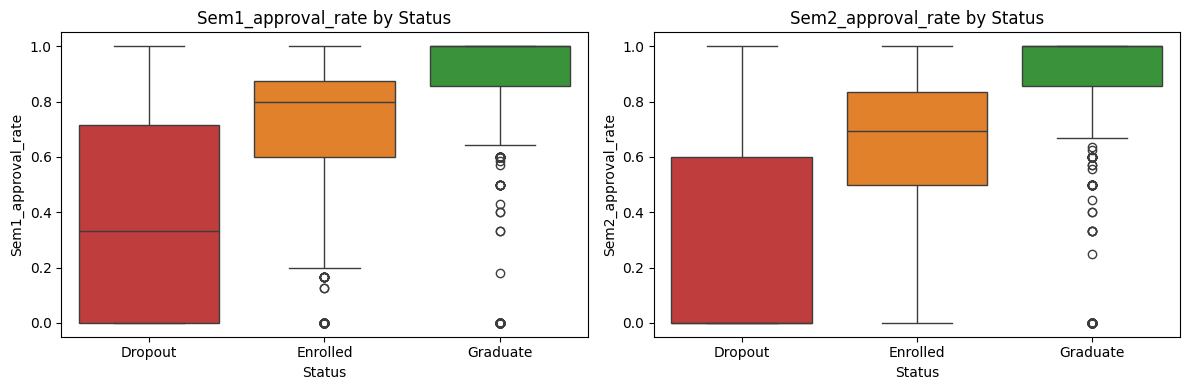

In [ ]:
def safe_ratio(numerator: pd.Series, denominator: pd.Series) -> pd.Series:
    """Divide two Series element-wise, returning 0 where the denominator is 0.

    A student enrolled in zero units has no defined approval rate. Filling
    with 0 keeps the row, but it also merges "enrolled in nothing" with
    "passed nothing" (see the caveat in Insight 9).

    Args:
        numerator: Values on top of the fraction, e.g. approved units.
        denominator: Values below the fraction, e.g. enrolled units.

    Returns:
        The element-wise ratio with 0 instead of NaN or infinity.

    Example:
        >>> safe_ratio(pd.Series([3, 1]), pd.Series([6, 0])).tolist()
        [0.5, 0.0]
    """
    return (numerator / denominator.replace(0, np.nan)).fillna(0)


engineered_student_data = student_data.copy()

# Approval rate = approved units / enrolled units, per semester.
for short, prefix in SEMESTER_PREFIXES.items():
    engineered_student_data[f"{short}_approval_rate"] = safe_ratio(
        engineered_student_data[f"{prefix}_approved"],
        engineered_student_data[f"{prefix}_enrolled"],
    )

plot_boxplots_by_target(
    engineered_student_data, ["Sem1_approval_rate", "Sem2_approval_rate"]
)

**Insight 9: Approval rates separate the three groups clearly, especially in semester 2.**

* **Finding.** Median semester-1 approval rate: 0.33 for Dropouts, 0.80 for Enrolled, 1.00 for Graduates. In semester 2: 0.00, 0.69 and 1.00. Three quarters of Dropouts are at or below 0.71 (semester 1) and 0.60 (semester 2), while three quarters of Enrolled students are at or above 0.60 and 0.50. *(Exact quartiles computed from the same dataset.)*
* **Caveats.** A rate of 0 is assigned both to students who passed nothing and to the 180 students who enrolled in **no** units (42.8% of whom dropped out). These are different situations merged into one value.
* **Follow-up check.** Add a flag `No_units_enrolled` and compare.
* **Modeling implication.** The overall and semester-2 approval rates are the two most important inputs by impurity, and the overall rate is the second most important raw feature by permutation (Section 7.4).

#### 5.1.2 Overall Approval Rate

The mean of the two semester approval rates.

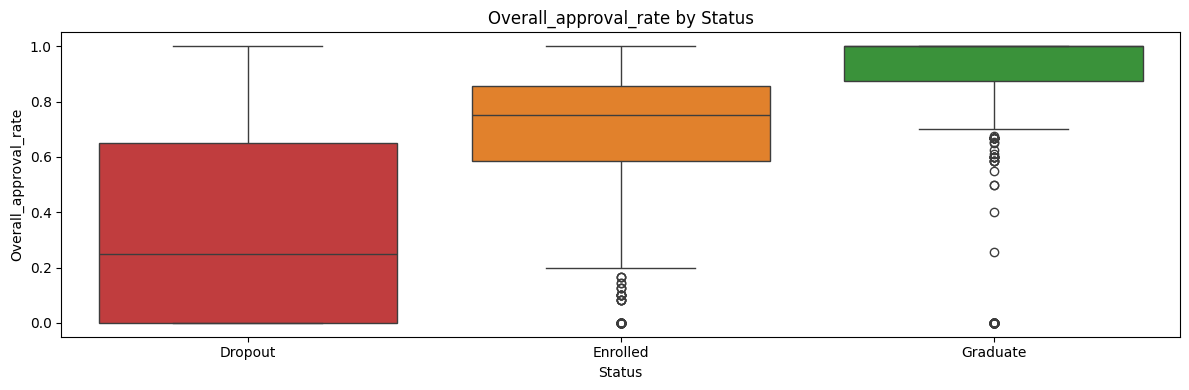

In [ ]:
# Simple average of the two semester rates.
engineered_student_data["Overall_approval_rate"] = engineered_student_data[
    ["Sem1_approval_rate", "Sem2_approval_rate"]
].mean(axis=1)

plot_boxplots_by_target(engineered_student_data, ["Overall_approval_rate"], n_cols=1)

**Insight 10: The overall approval rate tells the same story and is largely redundant with its parts.**

* **Finding.** Medians are 0.25 for Dropouts, 0.75 for Enrolled and 1.00 for Graduates.
* **Caveats.** It correlates at r = 0.97 with each semester rate (Section 5.1.8), so it adds little new information on top of them.
* **Modeling implication.** Kept. Because the model can use any of the three correlated rates, their importance is shared; permutation importance (Section 7.4) concentrates it on the overall rate.

#### 5.1.3 Share of Units Without Evaluation

The share of enrolled units that ended without any assessment, per semester. The cell also shows the share of students with any such unit, because box plots collapse when most values are zero.

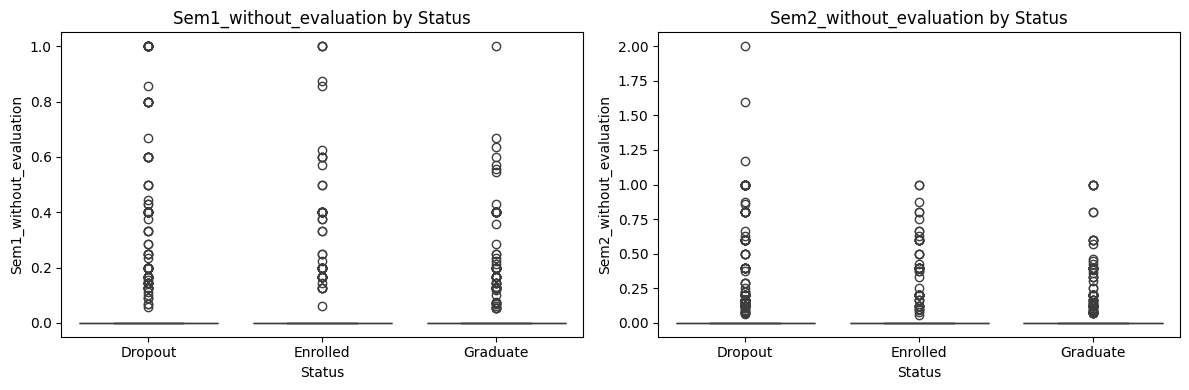

,Sem1_without_evaluation,Sem2_without_evaluation
Status,,
Dropout,8.7%,8.7%
Enrolled,8.8%,8.6%
Graduate,4.5%,4.1%


In [ ]:
# Share of enrolled units that ended without any evaluation, per semester.
for short, prefix in SEMESTER_PREFIXES.items():
    engineered_student_data[f"{short}_without_evaluation"] = safe_ratio(
        engineered_student_data[f"{prefix}_without_evaluations"],
        engineered_student_data[f"{prefix}_enrolled"],
    )

without_evaluation_cols = ["Sem1_without_evaluation", "Sem2_without_evaluation"]
plot_boxplots_by_target(engineered_student_data, without_evaluation_cols)
# Box plots collapse when most values are 0, so also compare the share > 0.
display(
    engineered_student_data[without_evaluation_cols]
    .gt(0)
    .groupby(engineered_student_data[TARGET])
    .mean()
    .reindex(STATUS_ORDER)
    .style.format("{:.1%}")
)

**Insight 11: Units without evaluation are rare, but about twice as common among students who do not graduate.**

* **Finding.** Every box is a flat line at 0, because most students have no unit without evaluation. The share table shows the real difference: 8.7% of Dropouts and 8.8% of Enrolled students had at least one unevaluated unit in semester 1, vs. 4.5% of Graduates (semester 2: 8.7%, 8.6% and 4.1%).
* **Caveats.** The feature does not separate Dropouts from Enrolled students, and it applies to few students.
* **Modeling implication.** Low-information feature on its own; its permutation importance is small but positive (Section 7.4).

#### 5.1.4 Change in Units Without Evaluation

Semester-2 share minus semester-1 share (positive = more unevaluated units in semester 2).

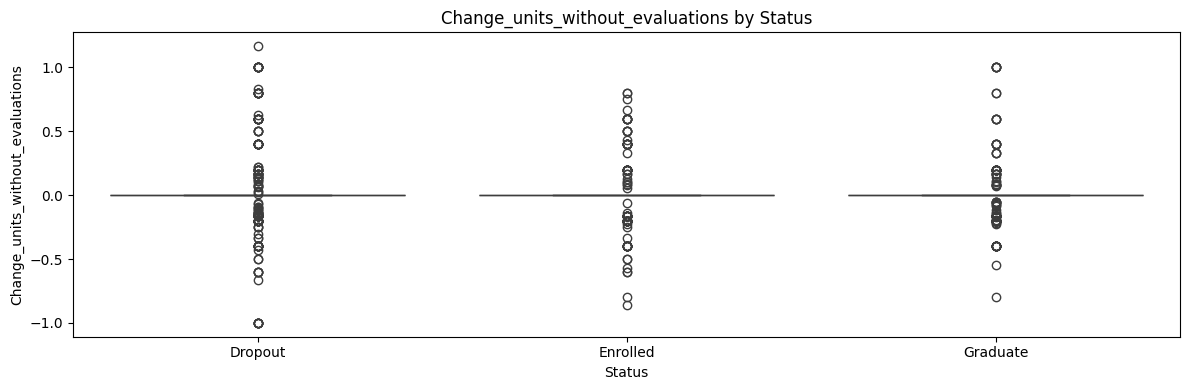

In [ ]:
# Positive values = a larger share of unevaluated units in semester 2.
engineered_student_data["Change_units_without_evaluations"] = (
    engineered_student_data["Sem2_without_evaluation"]
    - engineered_student_data["Sem1_without_evaluation"]
)

plot_boxplots_by_target(
    engineered_student_data, ["Change_units_without_evaluations"], n_cols=1
)

**Insight 12: The change feature inherits the sparsity of Insight 11.**

* **Finding.** Most values are 0, so the chart shows flat boxes with scattered dots. The values range from −1 to about 1.17, so this feature contains negative numbers.
* **Modeling implication.** Because of the negative values, it is excluded from the log transform in Section 5.4. It adds nothing in the likelihood-ratio test (p = 0.76, Section 5.5.1) or in permutation importance (Section 7.4), and is a candidate for removal.

#### 5.1.5 Overall Average Grade

Grade average across both semesters, weighted by the number of approved units in each semester. Students with no approved unit receive 0.

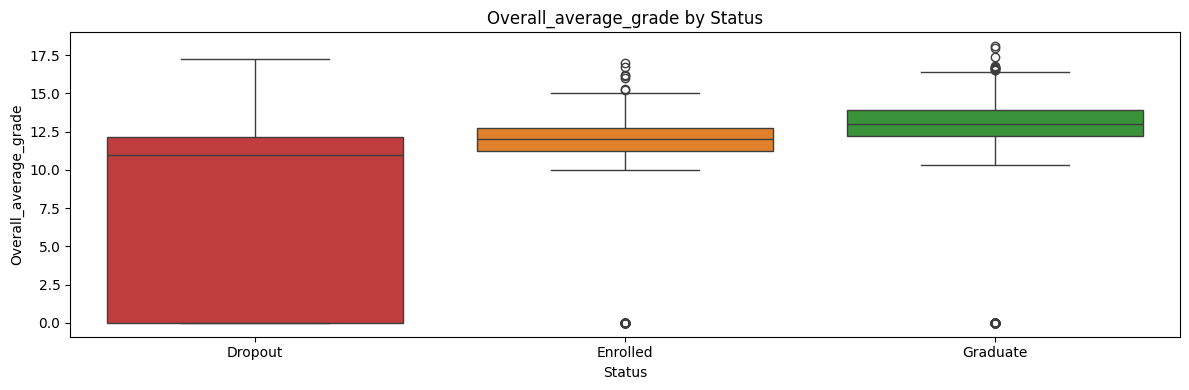

In [ ]:
# Grade average weighted by the number of approved units in each semester.
weighted_grade_sum = sum(
    engineered_student_data[f"{prefix}_grade"]
    * engineered_student_data[f"{prefix}_approved"]
    for prefix in SEMESTER_PREFIXES.values()
)
total_approved = sum(
    engineered_student_data[f"{prefix}_approved"]
    for prefix in SEMESTER_PREFIXES.values()
)
engineered_student_data["Overall_average_grade"] = safe_ratio(
    weighted_grade_sum, total_approved
)

plot_boxplots_by_target(engineered_student_data, ["Overall_average_grade"], n_cols=1)

**Insight 13: Dropouts have a lower and much more spread-out average grade.**

* **Finding.** Median overall grade: 11.0 for Dropouts (interquartile range 0–12.1), 12.0 for Enrolled (11.2–12.8) and 13.0 for Graduates (12.2–13.9).
* **Caveats.** The many zeros among Dropouts come from the "no approved unit" rule, not from actual grades of 0.
* **Modeling implication.** Useful predictor; strongly correlated with semester grades (Insight 16).

#### 5.1.6 Current Grade vs. Previous Qualification

The difference between the overall average grade and the previous-qualification grade. The previous-qualification grade (0–200 scale) is divided by 10 to match the curricular scale (0–20) before subtracting, so 0 means "performing at the same level as in prior schooling".

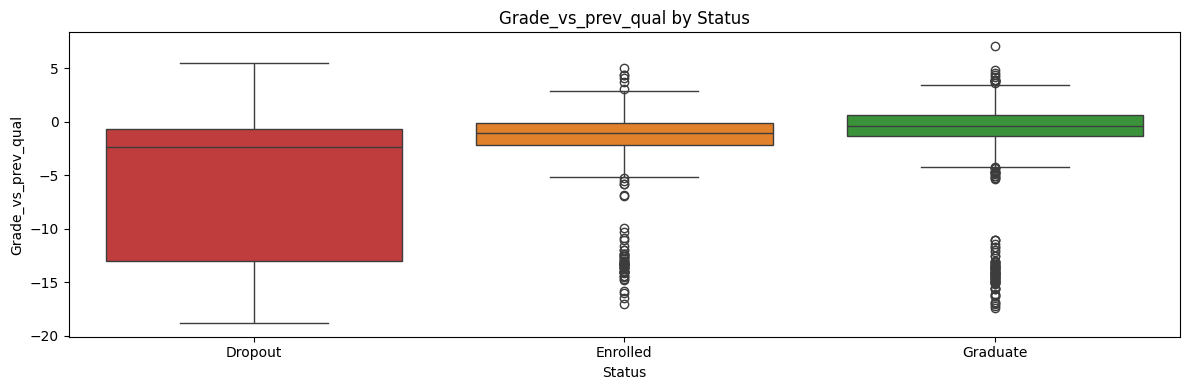

In [ ]:
# Bring the previous-qualification grade (0-200) onto the curricular scale
# (0-20) before subtracting; without this the feature is just -previous grade.
engineered_student_data["Grade_vs_prev_qual"] = (
    engineered_student_data["Overall_average_grade"]
    - engineered_student_data["Previous_qualification_grade"] / PREV_QUAL_GRADE_SCALE
)

plot_boxplots_by_target(engineered_student_data, ["Grade_vs_prev_qual"], n_cols=1)

**Insight 14: Graduates perform close to their prior level; dropouts fall far below it.**

* **Finding.** The median difference is about −0.4 points for Graduates (interquartile range roughly −1.4 to +0.6), about −1 for Enrolled students and about −2.3 for Dropouts, whose interquartile range stretches down to about −13. Values between −12 and −19 belong to students with no approved unit, whose average grade is set to 0.
* **Caveats.** Because of that zero rule, the feature is driven mostly by the current grade: it correlates at r = 0.96 with `Overall_average_grade` (Section 5.1.8). It adds a little information in the likelihood-ratio test (Section 5.5.1), but is largely redundant.
* **Modeling implication.** Kept; a version computed only for students with at least one approved unit would separate the "no progress" and "under-performing" cases.

#### 5.1.7 Approved-to-Credited Ratio

Approved units relative to units credited from previous studies, per semester and overall.

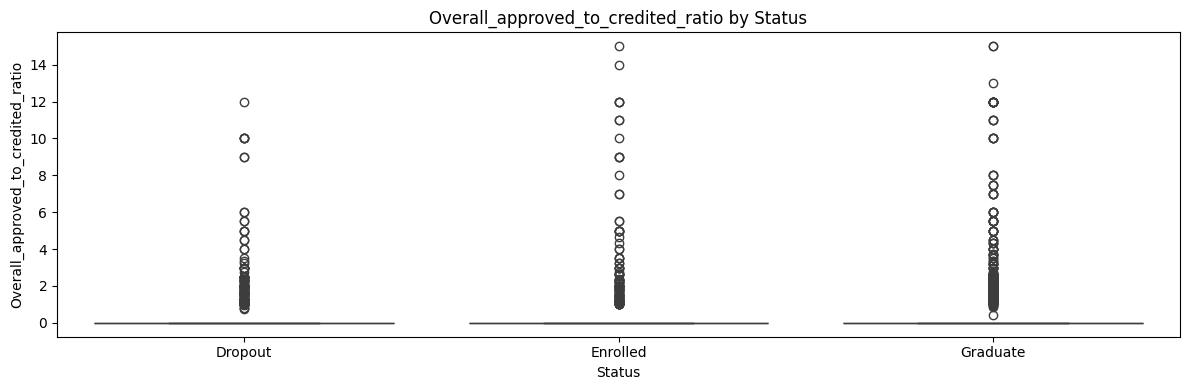

Share of students with any credited units: 13.6%


In [ ]:
# Approved units relative to units credited from previous studies.
for short, prefix in SEMESTER_PREFIXES.items():
    engineered_student_data[f"{short}_approved_to_credited_ratio"] = safe_ratio(
        engineered_student_data[f"{prefix}_approved"],
        engineered_student_data[f"{prefix}_credited"],
    )

total_credited = sum(
    engineered_student_data[f"{prefix}_credited"]
    for prefix in SEMESTER_PREFIXES.values()
)
engineered_student_data["Overall_approved_to_credited_ratio"] = safe_ratio(
    total_approved, total_credited
)

plot_boxplots_by_target(
    engineered_student_data, ["Overall_approved_to_credited_ratio"], n_cols=1
)
print(
    "Share of students with any credited units:",
    f"{total_credited.gt(0).mean():.1%}",
)

**Insight 15: The approved-to-credited ratio applies to few students.**

* **Finding.** Only 13.6% of students have any credited units (from prior studies); for everyone else the ratio is 0, so the boxes collapse to a line.
* **Modeling implication.** Low-information feature: it is not significant in the likelihood-ratio test (p = 0.19, Section 5.5.1) and its permutation importance is close to zero (Section 7.4). It is a candidate for removal in the next iteration.

#### 5.1.8 Correlation Among Numeric Features

A correlation matrix shows how strongly each pair of numeric features moves together (Pearson's r: +1 = perfectly together, −1 = perfectly opposite, 0 = no linear relation). Pairs with |r| ≥ 0.6 are listed.

Feature pairs with |r| >= 0.6 (58):
Sem2_approval_rate                            Overall_approval_rate                   0.9692
Curricular_units_1st_sem_grade                Overall_average_grade                   0.9662
Sem1_approval_rate                            Overall_approval_rate                   0.9661
Overall_average_grade                         Grade_vs_prev_qual                      0.9620
Curricular_units_2nd_sem_without_evaluations  Sem2_without_evaluation                 0.9517
Curricular_units_1st_sem_credited             Curricular_units_2nd_sem_credited       0.9448
Curricular_units_1st_sem_enrolled             Curricular_units_2nd_sem_enrolled       0.9426
Curricular_units_1st_sem_grade                Grade_vs_prev_qual                      0.9285
Curricular_units_1st_sem_approved             Curricular_units_2nd_sem_approved       0.9040
Curricular_units_1st_sem_without_evaluations  Sem1_without_evaluation                 0.8898
Curricular_units_2nd_sem_grade    

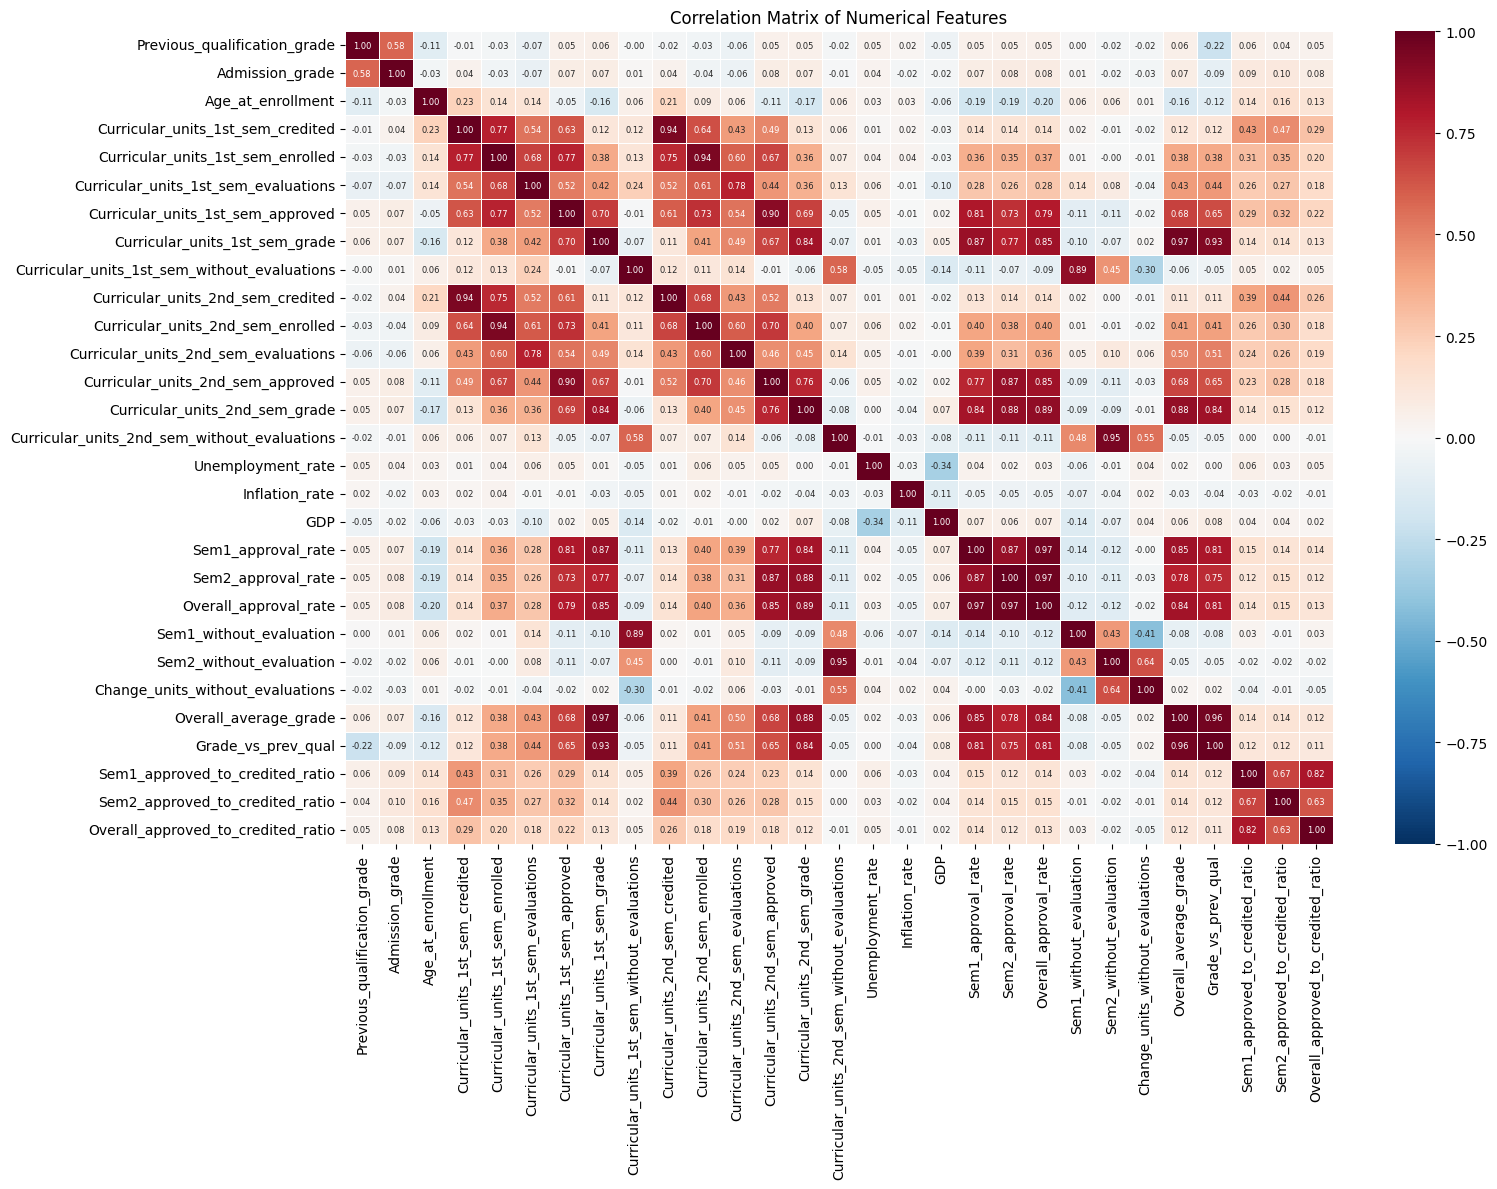

In [ ]:
# Pearson correlation only makes sense for genuinely numeric features, so
# coded categories and low-cardinality numerics are excluded.
categorical_like_cols = [
    col
    for col in engineered_student_data.columns
    if not is_numeric_dtype(engineered_student_data[col])
    or engineered_student_data[col].nunique() <= LOW_CARDINALITY_MAX
]
corr_mat = engineered_student_data.drop(columns=categorical_like_cols).corr()

# Keep each pair once (upper triangle, diagonal excluded) and |r| >= threshold.
row_idx, col_idx = np.triu_indices_from(corr_mat, k=1)
all_pairs = pd.Series(
    corr_mat.to_numpy()[row_idx, col_idx],
    index=pd.MultiIndex.from_arrays(
        [corr_mat.index[row_idx], corr_mat.columns[col_idx]]
    ),
)
strong_pairs = all_pairs[all_pairs.abs() >= CORRELATION_THRESHOLD].sort_values(
    key=np.abs, ascending=False
)
print(f"Feature pairs with |r| >= {CORRELATION_THRESHOLD} ({len(strong_pairs)}):")
print(strong_pairs.round(4).to_string())

plt.figure(figsize=(16, 12))
sns.heatmap(
    corr_mat,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    annot_kws={"size": 6},
    linewidths=0.5,
)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

**Insight 16: Many academic features are near-duplicates of each other (multicollinearity).**

* **Finding.** 58 feature pairs have |r| ≥ 0.6. The strongest are engineered features and their sources, for example `Overall_approval_rate` with `Sem2_approval_rate` (0.97), `Curricular_units_1st_sem_grade` with `Overall_average_grade` (0.97) and `Overall_average_grade` with `Grade_vs_prev_qual` (0.96), and the same metric across semesters, for example enrolled units (0.94) and approved units (0.90).
* **Interpretation.** *Multicollinearity* means that predictors are strongly correlated **with each other**, so several columns carry the same information. Here it is mostly by construction: engineered ratios repeat the counts they are built from.
* **Modeling implication.** Random Forest predictions are not harmed by correlated inputs, but importance gets split among them, which makes interpretation harder. The original features are kept so that importance can be read in recognizable terms; permutation importance on raw features (Section 7.4) handles the shared credit, and features with no added value are dropped in iteration 2 (Section 7.8).

#### 5.1.9 Dataset Check After Feature Engineering

In [ ]:
display(engineered_student_data)
engineered_student_data.describe().T

,Marital_status,Application_mode,Application_order,Course,Daytime_evening_attendance,Previous_qualification,Previous_qualification_grade,Nationality,Mothers_qualification,Fathers_qualification,...,Sem2_approval_rate,Overall_approval_rate,Sem1_without_evaluation,Sem2_without_evaluation,Change_units_without_evaluations,Overall_average_grade,Grade_vs_prev_qual,Sem1_approved_to_credited_ratio,Sem2_approved_to_credited_ratio,Overall_approved_to_credited_ratio
0,1,17,5,171,1,1,122.0,1,19,12,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,-12.200000,0.0,0.0,0.0
1,1,15,1,9254,1,1,160.0,1,1,3,...,1.000000,1.000000,0.0,0.0,0.0,13.833333,-2.166667,0.0,0.0,0.0
2,1,1,5,9070,1,1,122.0,1,37,37,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,-12.200000,0.0,0.0,0.0
3,1,17,2,9773,1,1,122.0,1,38,37,...,0.833333,0.916667,0.0,0.0,0.0,12.961039,0.761039,0.0,0.0,0.0
4,2,39,1,8014,0,1,100.0,1,37,38,...,1.000000,0.916667,0.0,0.0,0.0,12.696970,2.696970,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1,1,6,9773,1,1,125.0,1,1,1,...,0.833333,0.833333,0.0,0.0,0.0,13.133333,0.633333,0.0,0.0,0.0
4420,1,1,2,9773,1,1,120.0,105,1,1,...,0.333333,0.666667,0.0,0.0,0.0,11.750000,-0.250000,0.0,0.0,0.0
4421,1,1,1,9500,1,1,154.0,1,37,37,...,0.125000,0.562500,0.0,0.0,0.0,14.735938,-0.664062,0.0,0.0,0.0
4422,1,1,1,9147,1,1,180.0,1,37,37,...,1.000000,1.000000,0.0,0.0,0.0,12.900000,-5.100000,0.0,0.0,0.0


,count,mean,std,min,25%,50%,75%,max
Previous_qualification_grade,4424.0,132.613314,13.188332,95.00,125.000000,133.100000,140.000000,190.000000
Admission_grade,4424.0,126.978119,14.482001,95.00,117.900000,126.100000,134.800000,190.000000
Age_at_enrollment,4424.0,23.265145,7.587816,17.00,19.000000,20.000000,25.000000,70.000000
Curricular_units_1st_sem_credited,4424.0,0.709991,2.360507,0.00,0.000000,0.000000,0.000000,20.000000
Curricular_units_1st_sem_enrolled,4424.0,6.270570,2.480178,0.00,5.000000,6.000000,7.000000,26.000000
Curricular_units_1st_sem_evaluations,4424.0,8.299051,4.179106,0.00,6.000000,8.000000,10.000000,45.000000
Curricular_units_1st_sem_approved,4424.0,4.706600,3.094238,0.00,3.000000,5.000000,6.000000,26.000000
Curricular_units_1st_sem_grade,4424.0,10.640822,4.843663,0.00,11.000000,12.285714,13.400000,18.875000
Curricular_units_1st_sem_without_evaluations,4424.0,0.137658,0.690880,0.00,0.000000,0.000000,0.000000,12.000000
Curricular_units_2nd_sem_credited,4424.0,0.541817,1.918546,0.00,0.000000,0.000000,0.000000,19.000000


### 5.2 Export for the Dashboard (Phase A)

The engineered dataset is saved as `data/processed/student.csv` for the dashboard page of the Streamlit application. It is exported here, before model-specific transforms, so the dashboard shows values in their original units (raw counts, grades and coded categories rather than log-transformed or scaled values). *(Deviation 5.)*

In [ ]:
# Export before any model-specific transform, so the Streamlit dashboard shows
# values in their original units.
DASHBOARD_CSV_PATH.parent.mkdir(parents=True, exist_ok=True)
engineered_student_data.to_csv(DASHBOARD_CSV_PATH, index=False)
print(f"Saved {DASHBOARD_CSV_PATH} ({len(engineered_student_data):,} rows).")

Saved student.csv (4,424 rows).


### 5.3 Clean: Zero-Variance Check (Phase A)

A feature with the same value for every student carries no information. The cell removes such features (if any) and marks categorical-like features with the pandas `category` type for later steps.

In [ ]:
# A column with a single value carries no information for any model.
zero_variance_cols = [
    col
    for col in engineered_student_data.columns
    if engineered_student_data[col].nunique(dropna=False) <= 1
]
engineered_student_data = engineered_student_data.drop(columns=zero_variance_cols)

# Mark categorical-like features with the pandas `category` dtype so later
# steps can select them by type. The target stays as plain text.
category_cols = [
    col
    for col in categorical_like_cols
    if col != TARGET and col in engineered_student_data.columns
]
engineered_student_data[category_cols] = engineered_student_data[category_cols].astype(
    "category"
)

print("Zero-variance features:", zero_variance_cols)
print(
    f"The DataFrame has {engineered_student_data.shape[1]} columns and "
    f"{engineered_student_data.shape[0]:,} rows."
)

Zero-variance features: []
The DataFrame has 48 columns and 4,424 rows.


No feature has zero variance; the dataset has 48 columns and 4,424 rows at this point.

### 5.4 Format: Log Transform of Skewed Features (Phase A)

*Skewness* measures how lopsided a distribution is: positive values mean a long right tail (a few very large values). A log transform, `log1p(x) = log(1 + x)`, compresses a long right tail.

The transform is applied only to features that are **right-skewed and non-negative**. Left-skewed features (grades, approval rates) would become *more* skewed, and features with negative values would produce undefined results. *(Deviation 4: columns are chosen from full-data skewness; the rule uses no labels.)*

In [ ]:
student_df = engineered_student_data.copy()
skewness = student_df.skew(numeric_only=True)
is_non_negative = student_df[skewness.index].ge(0).all()

# log1p only helps right-skewed (positive skew), non-negative features:
# - left-skewed features (grades, approval rates) would become MORE skewed;
# - values <= -1 (e.g. Change_units_without_evaluations) give -inf/NaN.
log_cols = skewness[(skewness > MAX_SKEW_THRESHOLD) & is_non_negative].index.tolist()

skew_report = (
    pd.DataFrame({"Skew": skewness, "Non_negative": is_non_negative})
    .loc[lambda d: d["Skew"].abs() > MAX_SKEW_THRESHOLD]
    .assign(Log_transformed=lambda d: d.index.isin(log_cols))
    .sort_values("Skew", ascending=False)
)
display(skew_report.style.set_caption(f"Features with |skew| > {MAX_SKEW_THRESHOLD}"))

student_df[log_cols] = np.log1p(student_df[log_cols])
print(f"log1p applied to {len(log_cols)} features.")

,Skew,Non_negative,Log_transformed
Curricular_units_1st_sem_without_evaluations,8.207403,True,True
Curricular_units_2nd_sem_without_evaluations,7.267701,True,True
Sem2_without_evaluation,6.728533,True,True
Sem1_without_evaluation,6.398062,True,True
Overall_approved_to_credited_ratio,5.920974,True,True
Curricular_units_2nd_sem_credited,4.634820,True,True
Sem2_approved_to_credited_ratio,4.312799,True,True
Sem1_approved_to_credited_ratio,4.207210,True,True
Curricular_units_1st_sem_credited,4.169049,True,True
Age_at_enrollment,2.054988,True,True


log1p applied to 14 features.


Of the 22 features with |skew| > 0.66, **14 were log-transformed**, led by units without evaluation (skew 8.2 and 7.3) and credited units (4.6 and 4.2). The other eight were left unchanged: seven are left-skewed (approval rates, grades, `Overall_average_grade` and `Grade_vs_prev_qual`), and `Change_units_without_evaluations` contains negative values. Tree-based models such as Random Forest are unaffected by monotonic transforms; the transform matters mainly for the logistic-regression test in Section 5.5.1.

### 5.5 Statistical Association Tests (Phase A, descriptive)

These tests describe associations in the full dataset. They are **not** used for feature selection here (that is repeated on the training split in Section 5.8). *(Deviation 3.)*

#### 5.5.1 Likelihood-Ratio Test for Numeric Features

A multinomial logistic regression (a model that estimates the probability of each status from the features) is compared with a "null" model that ignores the features.

* **H0 (null hypothesis):** `Age_at_enrollment`, `Overall_approval_rate`, `Overall_average_grade`, `Overall_approved_to_credited_ratio`, `Grade_vs_prev_qual` and `Change_units_without_evaluations` jointly add no information about student status (all coefficients are zero).
* **H1 (alternative hypothesis):** at least one of these features is associated with student status.

The *likelihood-ratio (LR) test* measures how much better the full model explains the observed statuses; a p-value below 0.05 rejects H0. Each feature is also tested by dropping it from the model and measuring how much worse the fit becomes. The regression is unregularized (`C=np.inf`), as the test requires.

In [ ]:
def multinomial_log_likelihood(features: pd.DataFrame, target: pd.Series) -> float:
    """Fit an unpenalized multinomial logistic regression; return its log-likelihood.

    Features are standardized first: this does not change the likelihood but
    helps the solver converge and makes coefficients comparable (per 1 SD).
    ``C=np.inf`` disables regularization (the replacement for the deprecated
    ``penalty=None`` in scikit-learn >= 1.8), which the likelihood-ratio test
    requires.
    """
    model = Pipeline(
        [
            ("scale", StandardScaler()),
            ("logit", LogisticRegression(C=np.inf, max_iter=5000)),
        ]
    ).fit(features, target)
    probabilities = model.predict_proba(features)
    return -log_loss(target, probabilities, normalize=False, labels=model.classes_)


X_stat = student_df[STAT_TEST_NUMERIC_FEATURES]
y_stat = student_df[TARGET]
n_classes = y_stat.nunique()

# Null model: predicts the overall class shares for every student.
class_shares = y_stat.value_counts(normalize=True).sort_index()
ll_null = -log_loss(
    y_stat,
    np.tile(class_shares.to_numpy(), (len(y_stat), 1)),
    normalize=False,
    labels=class_shares.index,
)
ll_full = multinomial_log_likelihood(X_stat, y_stat)

# Global test: do the features jointly improve on the null model?
lr_stat = 2 * (ll_full - ll_null)
dof = len(STAT_TEST_NUMERIC_FEATURES) * (n_classes - 1)
p_global = chi2.sf(lr_stat, dof)
print(f"Likelihood-ratio statistic = {lr_stat:.1f}, df = {dof}, p = {p_global:.3g}")
print(f"McFadden pseudo-R2 = {1 - ll_full / ll_null:.3f}\n")

# Per-feature test: drop one feature at a time and compare likelihoods.
per_feature = []
for feature in STAT_TEST_NUMERIC_FEATURES:
    ll_reduced = multinomial_log_likelihood(X_stat.drop(columns=feature), y_stat)
    stat = 2 * (ll_full - ll_reduced)
    per_feature.append(
        {
            "Feature": feature,
            "LR_statistic": stat,
            "P_value": chi2.sf(stat, n_classes - 1),
        }
    )
display(pd.DataFrame(per_feature).sort_values("LR_statistic", ascending=False).round(4))

Likelihood-ratio statistic = 2917.6, df = 12, p = 0
McFadden pseudo-R2 = 0.323



,Feature,LR_statistic,P_value
1,Overall_approval_rate,1533.0338,0.0000
0,Age_at_enrollment,113.2133,0.0000
4,Grade_vs_prev_qual,44.5144,0.0000
2,Overall_average_grade,21.4194,0.0000
3,Overall_approved_to_credited_ratio,3.3459,0.1877
5,Change_units_without_evaluations,0.5414,0.7629


**Interpretation.** H0 is **rejected**: the LR statistic is 2,917.6 with 12 degrees of freedom, and the p-value is below floating-point precision (printed as 0). McFadden's pseudo-R² of 0.323 indicates that the six features explain a substantial part of the variation in student status.

The per-feature tests show where that information comes from. `Overall_approval_rate` dominates (LR = 1,533.0), followed by `Age_at_enrollment` (113.2), `Grade_vs_prev_qual` (44.5) and `Overall_average_grade` (21.4), all with p < 0.001. Given these, `Overall_approved_to_credited_ratio` (p = 0.19) and `Change_units_without_evaluations` (p = 0.76) add no significant information. With 4,424 students even small effects can be significant, so the LR statistics (effect size) matter more than the p-values: first-year approval rate and age carry most of the signal, matching Insights 2, 4 and 9.

#### 5.5.2 Chi-Square Tests for Categorical Features

The *chi-square test of independence* checks whether the distribution of statuses differs across the categories of a feature. H0: the feature and status are independent. The table also reports *Cramér's V* (effect size from 0 to 1) and the share of expected cell counts below 5, because the test is unreliable when many cells are sparse.

In [ ]:
def chi_square_tests(
    df: pd.DataFrame, features: list[str], target: str = TARGET
) -> pd.DataFrame:
    """Run a chi-square test of independence between each feature and the target.

    With thousands of rows almost any difference is "significant", so the
    table also reports Cramer's V (effect size: 0 = none, 0.1 small,
    0.3 medium, 0.5 large) and the share of expected cell counts below 5
    (above ~20% the chi-square approximation becomes unreliable).

    Args:
        df: Data containing ``features`` and ``target``.
        features: Categorical columns to test.
        target: Status column.

    Returns:
        One row per feature, sorted by p-value.
    """
    rows = []
    for feature in features:
        observed = pd.crosstab(df[target], df[feature])
        observed = observed.loc[:, observed.sum() > 0]  # drop unobserved codes
        stat, p_value, dof, expected = chi2_contingency(observed)
        n_obs = observed.to_numpy().sum()
        rows.append(
            {
                "Variable": feature,
                "Chi_statistic": stat,
                "DoF": dof,
                "P_value": p_value,
                "Cramers_V": np.sqrt(stat / (n_obs * (min(observed.shape) - 1))),
                "Share_expected_lt_5": (expected < 5).mean(),
            }
        )
    return pd.DataFrame(rows).sort_values("P_value", ignore_index=True)


categorical_features = student_df.select_dtypes(include="category").columns.tolist()
chi_square_full = chi_square_tests(student_df, categorical_features)
display(chi_square_full.round(4))

not_associated = chi_square_full.loc[
    chi_square_full["P_value"] >= ALPHA, "Variable"
].tolist()
print(
    f"No significant association at alpha = {ALPHA} (H0 not rejected): {not_associated}"
)

,Variable,Chi_statistic,DoF,P_value,Cramers_V,Share_expected_lt_5
0,Tuition_fees_up_to_date,823.5527,2,0.0000,0.4315,0.0000
1,Course,558.2845,32,0.0000,0.2512,0.0392
2,Scholarship_holder,409.9431,2,0.0000,0.3044,0.0000
3,Application_mode,466.5137,34,0.0000,0.2296,0.2963
4,Debtor,259.3332,2,0.0000,0.2421,0.0000
5,Gender,233.2664,2,0.0000,0.2296,0.0000
6,Mothers_occupation,291.9217,62,0.0000,0.1816,0.6042
7,Previous_qualification,219.6807,32,0.0000,0.1576,0.4902
8,Mothers_qualification,217.9521,56,0.0000,0.1569,0.6667
9,Fathers_qualification,225.0008,66,0.0000,0.1595,0.6961


No significant association at alpha = 0.05 (H0 not rejected): ['Nationality', 'International', 'Educational_special_needs']


**Interpretation.** 15 of 18 categorical features have p < 0.05. The strongest associations by Cramér's V are `Tuition_fees_up_to_date` (V = 0.43, χ² = 823.6), `Scholarship_holder` (0.30), `Course` (0.25), `Debtor` (0.24), `Gender` (0.23) and `Application_mode` (0.23). For `Nationality` (p = 0.24), `International` (p = 0.53) and `Educational_special_needs` (p = 0.73), H0 is **not rejected**: there is no evidence of an association, which is not the same as proving independence.

* **Caveats.** For the parents' qualification and occupation, 60–72% of expected cell counts are below 5, and for `Nationality` 86%, so their p-values are unreliable. `Application_mode` (30%) and `Previous_qualification` (49%) are also affected. Marital status and attendance are significant but weak (V ≈ 0.08).
* **Consistency.** The financial and gender results agree with the dropout rates in Insights 3 and 5.

### 5.6 Select: Domain Exclusions (Phase A)

Columns in `DROP_COLS` are excluded before modelling: the three macroeconomic indicators (cohort proxies, Insight 7), the four parental qualification and occupation codes (sensitive and sparse), and `Application_mode`. `Application_mode` is excluded by the author even though it is strongly associated with dropout (Insight 6); testing it as a feature is a candidate for the next iteration.

In [ ]:
model_df = student_df.drop(columns=DROP_COLS)
print(f"Dropped {len(DROP_COLS)} domain-excluded columns; {model_df.shape[1]} remain.")

Dropped 8 domain-excluded columns; 40 remain.


### 5.7 Generate Test Design: Stratified Split (Phase B)

The class distribution before splitting:

In [ ]:
class_counts = model_df[TARGET].value_counts().reindex(STATUS_ORDER)
display(
    pd.DataFrame({"Students": class_counts, "Share": class_counts / class_counts.sum()})
)

,Students,Share
Status,,
Dropout,1421,0.321203
Enrolled,794,0.179476
Graduate,2209,0.499322


The data are split into a training set (90%) and a test set (10%) that stays untouched until Section 7. *Stratification* keeps the class shares identical in both parts. The split happens **before** any balancing, so the test set keeps the real class mix and contains no copies of training students.

In [ ]:
# Split FIRST, before any label-aware or fitted step, so the test set is a
# faithful sample of future students: real class mix and no duplicated rows.
train_df, test_df = train_test_split(
    model_df,
    test_size=TEST_SIZE,
    stratify=model_df[TARGET],  # keep the same class shares in both parts
    random_state=RANDOM_STATE,
)
print(f"Train: {train_df.shape} | Test: {test_df.shape}")
display(
    pd.DataFrame(
        {
            "Train share": train_df[TARGET].value_counts(normalize=True),
            "Test share": test_df[TARGET].value_counts(normalize=True),
        }
    ).reindex(STATUS_ORDER)
)

Train: (3981, 40) | Test: (443, 40)


,Train share,Test share
Status,,
Dropout,0.321276,0.320542
Enrolled,0.179352,0.180587
Graduate,0.499372,0.498871


The training set has 3,981 students and the test set 443 (142 Dropouts, 80 Enrolled, 221 Graduates). Class shares match the full data within 0.2 percentage points.

### 5.8 Select: Chi-Square Selection on the Training Split (Phase C)

Selecting features with the target uses label information, so it is decided on the training split only and then applied to both splits. Categorical features with p ≥ 0.05 are removed.

In [ ]:
# Feature selection uses labels, so it is decided on the training split only.
train_categorical = train_df.select_dtypes(include="category").columns.tolist()
chi_square_train = chi_square_tests(train_df, train_categorical)
weak_features = chi_square_train.loc[
    chi_square_train["P_value"] >= ALPHA, "Variable"
].tolist()

train_df = train_df.drop(columns=weak_features)
test_df = test_df.drop(columns=weak_features)
display(chi_square_train.round(4))
print(f"Removed (p >= {ALPHA} on the training split): {weak_features}")

,Variable,Chi_statistic,DoF,P_value,Cramers_V,Share_expected_lt_5
0,Tuition_fees_up_to_date,722.7395,2,0.0000,0.4261,0.0000
1,Course,496.9930,32,0.0000,0.2498,0.0588
2,Scholarship_holder,373.9857,2,0.0000,0.3065,0.0000
3,Debtor,221.6906,2,0.0000,0.2360,0.0000
4,Gender,200.3415,2,0.0000,0.2243,0.0000
5,Previous_qualification,210.0202,32,0.0000,0.1624,0.5294
6,Displaced,53.9737,2,0.0000,0.1164,0.0000
7,Marital_status,59.5949,10,0.0000,0.0865,0.3889
8,Application_order,65.6545,14,0.0000,0.0908,0.2500
9,Daytime_evening_attendance,28.0509,2,0.0000,0.0839,0.0000


Removed (p >= 0.05 on the training split): ['International', 'Nationality', 'Educational_special_needs']


The training split removes the same three features as the full-data test: `International` (p = 0.39), `Nationality` (p = 0.44) and `Educational_special_needs` (p = 0.68). Ten categorical features remain.

### 5.9 Balance: Undersampling the Training Split (Phase C)

*Undersampling* randomly removes students from the larger classes, without replacement, until every class has as many students as the smallest one, so the model does not simply favour the majority class (He & Garcia, 2009). It is applied **only to the training split**; the test split keeps the real class mix. Setting `UNDERSAMPLE_TRAIN = False` in Section 3.2 keeps all training students; `class_weight="balanced"` is a common alternative (Section 7.6).

In [ ]:
def undersample(df: pd.DataFrame, target: str, random_state: int) -> pd.DataFrame:
    """Downsample every class to the size of the smallest one, without replacement.

    Sampling without replacement keeps every selected student unique;
    sampling with replacement would duplicate students and, if done before the
    split, could place copies of the same student in both training and test.

    Args:
        df: Training data only; never apply this to the test set.
        target: Class column.
        random_state: Seed for reproducible sampling.

    Returns:
        A shuffled DataFrame with an equal number of rows per class.
    """
    minority_size = df[target].value_counts().min()
    balanced = df.groupby(target, group_keys=False).sample(
        n=minority_size, random_state=random_state
    )
    return balanced.sample(frac=1, random_state=random_state)


print("Training class counts before balancing:")
display(train_df[TARGET].value_counts().reindex(STATUS_ORDER))

# Keep the full (imbalanced) training split for iteration 2 (Section 7.8).
train_full_df = train_df.copy()

if UNDERSAMPLE_TRAIN:
    train_df = undersample(train_df, TARGET, SAMPLING_RANDOM_STATE)
    print("Training class counts after undersampling:")
    display(train_df[TARGET].value_counts().reindex(STATUS_ORDER))

X_train, y_train = train_df.drop(columns=TARGET), train_df[TARGET]
X_train_full, y_train_full = train_full_df.drop(columns=TARGET), train_full_df[TARGET]
X_test, y_test = test_df.drop(columns=TARGET), test_df[TARGET]

Training class counts before balancing:


,count
Status,
Dropout,1279
Enrolled,714
Graduate,1988


Training class counts after undersampling:


,count
Status,
Dropout,714
Enrolled,714
Graduate,714


Each class now has 714 training students (2,142 in total). The cost is visible: 565 Dropouts and 1,274 Graduates, 1,839 students in all, are not used for training. Section 7.6 suggests class weights as an alternative that keeps them.

### 5.10 Encoding and Scaling (Phase C)

Machine-learning models need numbers. Categorical codes are mapped to integers with `OrdinalEncoder`, which also handles codes not seen during training (mapped to −1), and numeric features are rescaled to the 0–1 range with `MinMaxScaler`. All steps are wrapped in one `ColumnTransformer`, so they are fitted on training data only, refitted inside each cross-validation fold, and saved together with the model for the Streamlit app.

In [ ]:
categorical_features = X_train.select_dtypes(include="category").columns.tolist()
# "number" covers every int/float width ("int" alone misses int64 on Windows).
numeric_features = X_train.select_dtypes(include="number").columns.tolist()


def build_preprocessor(feature_columns: list[str] | None = None) -> ColumnTransformer:
    """Build the feature-preprocessing step that is fitted on training data only.

    - Categorical codes -> ``OrdinalEncoder``. It replaces ``LabelEncoder``,
      which is meant for targets and raises an error on a category that was
      not seen during fitting; here an unseen code becomes -1.
    - Numeric features -> ``MinMaxScaler`` (rescale to 0-1).

    Wrapping these steps in one object lets cross-validation refit them inside
    each fold and lets the app reuse exactly the same transformation.

    Args:
        feature_columns: Optional subset of input columns (e.g. after dropping
            low-value features). ``None`` uses every column of ``X_train``.
    """
    keep = None if feature_columns is None else set(feature_columns)

    def _subset(cols: list[str]) -> list[str]:
        return [col for col in cols if keep is None or col in keep]

    transformers = [
        (
            "cat",
            OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
            _subset(categorical_features),
        ),
        ("num", MinMaxScaler(), _subset(numeric_features)),
    ]
    return ColumnTransformer(transformers, remainder="drop").set_output(
        transform="pandas"
    )


preprocessor = build_preprocessor()
print(f"{len(categorical_features)} categorical | {len(numeric_features)} numeric")
preprocessor

10 categorical | 26 scaled only | 0 compressed by PCA


ColumnTransformer(transformers=[('cat',
                                 OrdinalEncoder(handle_unknown='use_encoded_value',
                                                unknown_value=-1),
                                 ['Marital_status', 'Application_order',
                                  'Course', 'Daytime_evening_attendance',
                                  'Previous_qualification', 'Displaced',
                                  'Debtor', 'Tuition_fees_up_to_date', 'Gender',
                                  'Scholarship_holder']),
                                ('num', MinMaxScaler(),
                                 ['Previous_qualification_grade',
                                  'Admissio...
                                  'Curricular_units_2nd_sem_without_evaluations',
                                  'Sem1_approval_rate', 'Sem2_approval_rate',
                                  'Overall_approval_rate',
                                  'Sem1_without_evaluation',
                                  'Sem2_without_evaluation',
                                  'Change_units_without_evaluations',
                                  'Overall_average_grade', 'Grade_vs_prev_qual',
                                  'Sem1_approved_to_credited_ratio',
                                  'Sem2_approved_to_credited_ratio',
                                  'Overall_approved_to_credited_ratio'])])

The preprocessor handles 10 categorical and 26 numeric features. The target labels are encoded as integers in alphabetical order (Dropout = 0, Enrolled = 1, Graduate = 2). The encoder is saved in Section 8.1 so the app can translate predictions back into labels.

In [ ]:
# The model predicts integer codes; the encoder maps them back to labels
# (it is saved with the model in Section 8.1 for the Streamlit app).
target_encoder = LabelEncoder().fit(y_train)
y_train_encoded = target_encoder.transform(y_train)
y_test_encoded = target_encoder.transform(y_test)
class_codes = dict(
    zip(target_encoder.classes_, range(len(target_encoder.classes_)), strict=True)
)
dropout_code = class_codes[POSITIVE_CLASS]
print("Target encoding:", class_codes)

Target encoding: {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}


The fitted preprocessor shows the final model inputs. The test split is only transformed, never fitted.

In [ ]:
# Fitted here only for inspection; the modelling pipeline refits a clone.
train_preview = preprocessor.fit_transform(X_train)
n_raw, n_inputs = X_train.shape[1], train_preview.shape[1]
print(f"Training matrix: {n_raw} raw features -> {n_inputs} model inputs")
display(train_preview.head())

Training matrix: 36 raw features -> 36 model inputs


,cat__Marital_status,cat__Application_order,cat__Course,cat__Daytime_evening_attendance,cat__Previous_qualification,cat__Displaced,cat__Debtor,cat__Tuition_fees_up_to_date,cat__Gender,cat__Scholarship_holder,...,num__Sem2_approval_rate,num__Overall_approval_rate,num__Sem1_without_evaluation,num__Sem2_without_evaluation,num__Change_units_without_evaluations,num__Overall_average_grade,num__Grade_vs_prev_qual,num__Sem1_approved_to_credited_ratio,num__Sem2_approved_to_credited_ratio,num__Overall_approved_to_credited_ratio
4356,0.0,0.0,5.0,1.0,9.0,0.0,0.0,1.0,0.0,0.0,...,0.000000,0.25,0.0,0.0,0.5,0.729157,0.737088,0.0,0.0,0.0
1491,0.0,0.0,14.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,...,1.000000,1.00,0.0,0.0,0.5,0.647606,0.676926,0.0,0.0,0.0
4005,1.0,0.0,5.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,...,0.000000,0.00,0.0,0.0,0.5,0.000000,0.127401,0.0,0.0,0.0
474,0.0,0.0,10.0,1.0,5.0,1.0,0.0,0.0,0.0,0.0,...,0.000000,0.00,0.0,0.0,0.5,0.000000,0.199171,0.0,0.0,0.0
3292,0.0,0.0,9.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.166667,0.25,0.0,0.0,0.5,0.633215,0.509606,0.0,0.0,0.0


In [ ]:
test_preview = preprocessor.transform(X_test)  # transform only, never fit on test
print(f"Test matrix: {test_preview.shape}")
display(test_preview.head())

Test matrix: (443, 36)


,cat__Marital_status,cat__Application_order,cat__Course,cat__Daytime_evening_attendance,cat__Previous_qualification,cat__Displaced,cat__Debtor,cat__Tuition_fees_up_to_date,cat__Gender,cat__Scholarship_holder,...,num__Sem2_approval_rate,num__Overall_approval_rate,num__Sem1_without_evaluation,num__Sem2_without_evaluation,num__Change_units_without_evaluations,num__Overall_average_grade,num__Grade_vs_prev_qual,num__Sem1_approved_to_credited_ratio,num__Sem2_approved_to_credited_ratio,num__Overall_approved_to_credited_ratio
4217,0.0,1.0,14.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,...,1.000000,1.000000,0.0,0.0,0.5,0.743548,0.752376,0.000000,0.000000,0.000000
2863,0.0,0.0,15.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,...,1.000000,1.000000,0.0,0.0,0.5,0.703732,0.689029,0.345208,0.315465,0.254595
2665,1.0,0.0,14.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.666667,0.500000,0.0,0.0,0.5,0.661998,0.785642,0.000000,0.000000,0.000000
3379,0.0,3.0,11.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.857143,0.857143,0.0,0.0,0.5,0.800154,0.726188,0.000000,0.000000,0.000000
2582,0.0,0.0,8.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.000000,1.000000,0.0,0.0,0.5,0.857719,0.717695,0.000000,0.000000,0.000000


The model receives **36 inputs** (10 encoded categories and 26 scaled numeric features) for both splits, with the same columns and order.

### 5.11 Model-Ready Data and Validation Folds (Phase D)

The training split is used for cross-validation and tuning; the test split is reserved for the final evaluation in Section 7. *Stratified k-fold cross-validation* splits the training data into five parts, trains on four and validates on the fifth in turn, keeping the class mix identical in every fold.

In [ ]:
# Stratified folds keep the class mix identical in every validation fold.
cv_splitter = StratifiedKFold(
    n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE
)
print(f"Model-ready training data: X {X_train.shape}, y {y_train_encoded.shape}")
print(f"Untouched test data:       X {X_test.shape}, y {y_test_encoded.shape}")

Model-ready training data: X (2142, 36), y (2142,)
Untouched test data:       X (443, 36), y (443,)


## 6. Modelling

### 6.1 Candidate Algorithm and Search Space

**Random Forest** (Breiman, 2001) is the algorithm required by the project brief. It builds many decision trees on random subsets of students and features and combines their votes. It suits this problem because it handles mixed numeric and categorical inputs, captures non-linear effects and interactions (for example, low grades *and* tuition arrears), is robust to skewed features and unusual values, and needs no feature scaling. Its main weakness is a tendency to memorize the training data (overfitting), which tuning and cross-validation keep in check.

| Hyperparameter | Meaning | Search space |
|---|---|---|
| `n_estimators` | Number of trees | 100–999 |
| `max_depth` | Maximum depth of each tree | 10–99 |
| `max_features` | Features considered at each split | `sqrt`, `log2`, all |
| `min_samples_split` | Minimum students needed to split a node | 2–19 |
| `min_samples_leaf` | Minimum students in a leaf | 1–9 |
| `bootstrap` | Train each tree on a bootstrap sample | True, False |
| `criterion` | Split-quality measure | `gini`, `entropy`, `log_loss` |

### 6.2 Training Utilities

The full pipeline (preprocessing + Random Forest) is built by one function, so cross-validation and tuning always refit preprocessing inside each fold.

In [ ]:
def build_model_pipeline(
    feature_columns: list[str] | None = None, **rf_params
) -> Pipeline:
    """Chain the preprocessor and a Random Forest into one estimator.

    Args:
        feature_columns: Optional subset of input columns (``None`` = all).
        **rf_params: Optional ``RandomForestClassifier`` hyperparameters.

    Returns:
        An unfitted pipeline with steps ``preprocess`` and ``model``.
    """
    return Pipeline(
        [
            ("preprocess", build_preprocessor(feature_columns)),
            (
                "model",
                RandomForestClassifier(
                    random_state=RANDOM_STATE, n_jobs=-1, **rf_params
                ),
            ),
        ]
    )


CV_SCORING = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "recall_dropout": make_scorer(recall_score, labels=[dropout_code], average="macro"),
}


def summarize_cv(estimator, name: str) -> pd.Series:
    """Cross-validate ``estimator`` on the training split and return mean scores."""
    scores = cross_validate(
        estimator,
        X_train,
        y_train_encoded,
        cv=cv_splitter,
        scoring=CV_SCORING,
        n_jobs=-1,
    )
    return pd.Series(
        {metric: scores[f"test_{metric}"].mean() for metric in CV_SCORING}, name=name
    )

### 6.3 Baseline Models

Before tuning, two reference points are cross-validated on the training split: a majority-class dummy model and a Random Forest with default hyperparameters. Tuning is only worthwhile if it beats the default model.

In [ ]:
baseline_cv = pd.DataFrame(
    [
        summarize_cv(
            DummyClassifier(strategy="most_frequent"), "Majority class (dummy)"
        ),
        summarize_cv(build_model_pipeline(), "Random Forest, default hyperparameters"),
    ]
)
display(baseline_cv.round(3))

,accuracy,f1_macro,recall_dropout
Majority class (dummy),0.332,0.166,0.600
"Random Forest, default hyperparameters",0.711,0.712,0.695


The default Random Forest reaches a mean cross-validated macro F1 of 0.712 (accuracy 0.711, Dropout recall 0.695), far above the dummy model (macro F1 0.166). The dummy's Dropout recall of 0.600 is an artefact: with perfectly balanced classes, "most frequent" falls back to the first class label (Dropout) in some folds, so it predicts everyone as a dropout there.

### 6.4 Hyperparameter Tuning with Optuna

Hyperparameters are tuned with **Optuna** (Akiba et al., 2019), an open-source optimization framework. Compared with random search, it uses the same budget (50 trials) and search space (Section 6.1) more efficiently in two ways:

* **Guided search.** The *TPE sampler* (Tree-structured Parzen Estimator) learns from completed trials and proposes new combinations near the best-scoring ones.
* **Early stopping of poor trials.** Each trial is scored fold by fold with 5-fold stratified cross-validation. After each fold, the *median pruner* stops the trial if its running score is below the median of earlier trials at the same fold. The first 10 trials always run all folds to set a reference.

Every trial scores the full pipeline (preprocessing + Random Forest) with macro F1 (criterion D2), and preprocessing is refitted inside every fold. The utilities below define the search, the objective and the **JSON flat-file log**: one plain file with the study settings, the best parameters and one flat record per trial (`param_*` fields, score, state, duration). The log can be versioned with git, opened in any tool, and reloaded with `RUN_TUNING = False` to skip a new search. No Optuna database is created.

In [ ]:
def suggest_params(trial: optuna.Trial, search_space: dict[str, tuple]) -> dict:
    """Ask Optuna for one value per hyperparameter in ``search_space``.

    Args:
        trial: The current Optuna trial.
        search_space: Mapping ``name -> ("int", low, high)`` (inclusive bounds)
            or ``name -> ("categorical", choices)``.

    Returns:
        Hyperparameter values for ``RandomForestClassifier``.

    Raises:
        ValueError: If a search-space entry has an unknown type.
    """
    params = {}
    for name, (kind, *spec) in search_space.items():
        if kind == "int":
            params[name] = trial.suggest_int(name, low=spec[0], high=spec[1])
        elif kind == "categorical":
            params[name] = trial.suggest_categorical(name, choices=spec[0])
        else:
            raise ValueError(f"Unknown search-space type {kind!r} for {name!r}")
    return params


def make_cv_objective(
    features: pd.DataFrame,
    target: np.ndarray,
    cv: StratifiedKFold,
    scoring: str,
    search_space: dict[str, tuple] = RF_SEARCH_SPACE,
):
    """Build the function Optuna maximizes: mean cross-validated ``scoring``.

    Folds are evaluated one at a time so that Optuna can stop (prune) a
    clearly poor trial early: after each fold the running mean is reported,
    and the pruner compares it with earlier trials at the same fold.
    Preprocessing is refitted inside every fold, so no fold leaks into another.

    Args:
        features: Training features (raw, before preprocessing).
        target: Encoded training labels.
        cv: Cross-validation splitter.
        scoring: Name of a scikit-learn scorer, e.g. ``"f1_macro"``.
        search_space: Hyperparameter space passed to ``suggest_params``.

    Returns:
        A callable ``objective(trial) -> float``.
    """
    scorer = get_scorer(scoring)
    folds = list(cv.split(features, target))
    feature_columns = features.columns.tolist()

    def objective(trial: optuna.Trial) -> float:
        pipeline = build_model_pipeline(
            feature_columns, **suggest_params(trial, search_space)
        )
        fold_scores = []
        for fold, (train_idx, valid_idx) in enumerate(folds):
            fitted = clone(pipeline).fit(features.iloc[train_idx], target[train_idx])
            fold_scores.append(
                scorer(fitted, features.iloc[valid_idx], target[valid_idx])
            )
            trial.report(float(np.mean(fold_scores)), step=fold)
            if trial.should_prune():
                raise optuna.TrialPruned()
        trial.set_user_attr("cv_score_std", float(np.std(fold_scores)))
        return float(np.mean(fold_scores))

    return objective


def trial_to_record(trial: optuna.trial.FrozenTrial) -> dict:
    """Flatten one trial into a single-level dict (one key per field).

    Hyperparameters become ``param_<name>`` keys, so every trial is one flat
    row that loads directly into a DataFrame or spreadsheet. For pruned trials,
    ``value`` is the running mean at the last evaluated fold.
    """
    return {
        "number": trial.number,
        "state": trial.state.name,
        "value": trial.value,
        "folds_evaluated": len(trial.intermediate_values),
        **{f"param_{name}": value for name, value in trial.params.items()},
        **{f"attr_{name}": value for name, value in trial.user_attrs.items()},
        "datetime_start": trial.datetime_start.isoformat()
        if trial.datetime_start
        else None,
        "duration_seconds": trial.duration.total_seconds() if trial.duration else None,
    }


def save_tuning_results(
    study: optuna.Study, path: Path, extra: dict | None = None
) -> None:
    """Write the study summary and every trial to a plain JSON file.

    A JSON flat file (instead of an Optuna database) is easy to version with
    git, read in any language, and reload without Optuna installed.

    Args:
        study: Finished Optuna study.
        path: Destination ``.json`` file.
        extra: Optional study-level fields (e.g. training regime, features).
    """
    payload = {
        **(extra or {}),
        "study_name": study.study_name,
        "direction": study.direction.name,
        "scoring": SEARCH_SCORING,
        "cv_folds": CV_FOLDS,
        "n_trials": len(study.trials),
        "sampler": type(study.sampler).__name__,
        "pruner": type(study.pruner).__name__,
        "seed": RANDOM_STATE,
        "optuna_version": optuna.__version__,
        "saved_at_utc": datetime.now(UTC).isoformat(timespec="seconds"),
        "best_value": study.best_value,
        "best_params": study.best_params,
        "trials": [trial_to_record(trial) for trial in study.trials],
    }
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, indent=2), encoding="utf-8")


def load_tuning_results(path: Path) -> dict:
    """Read a JSON file written by ``save_tuning_results``.

    Raises:
        FileNotFoundError: If the file does not exist (run with RUN_TUNING = True).
    """
    if not path.exists():
        raise FileNotFoundError(
            f"{path} not found; set RUN_TUNING = True to create it."
        )
    return json.loads(path.read_text(encoding="utf-8"))

The study runs (or, with `RUN_TUNING = False`, is reloaded from `artifacts/tuning/optuna_tuning_results.json`), and the five best completed trials are listed.

In [ ]:
if RUN_TUNING:
    optuna.logging.set_verbosity(optuna.logging.WARNING)  # one summary, not 50 logs
    study = optuna.create_study(
        study_name=OPTUNA_STUDY_NAME,
        direction="maximize",
        # TPE (Tree-structured Parzen Estimator) proposes new values near the
        # best ones found so far, instead of sampling blindly at random.
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
        pruner=optuna.pruners.MedianPruner(
            n_startup_trials=PRUNER_STARTUP_TRIALS, n_warmup_steps=PRUNER_WARMUP_FOLDS
        ),
    )
    study.optimize(
        make_cv_objective(X_train, y_train_encoded, cv_splitter, SEARCH_SCORING),
        n_trials=N_TRIALS,
    )
    save_tuning_results(study, TUNING_RESULTS_PATH)
    print(f"Saved {len(study.trials)} trials to {TUNING_RESULTS_PATH}")

tuning_results = load_tuning_results(TUNING_RESULTS_PATH)
best_params = tuning_results["best_params"]
trials_df = pd.DataFrame(tuning_results["trials"])

print(trials_df["state"].value_counts().to_string())
print(f"Best hyperparameters: {best_params}")
print(f"Best mean CV {SEARCH_SCORING}: {tuning_results['best_value']:.3f}")
display(
    trials_df.query("state == 'COMPLETE'")
    .sort_values("value", ascending=False)
    .head(5)
    .round(4)
)

state
COMPLETE    36
PRUNED      14
Best hyperparameters: {'n_estimators': 561, 'max_depth': 68, 'max_features': 'sqrt', 'min_samples_split': 7, 'min_samples_leaf': 1, 'bootstrap': True, 'criterion': 'log_loss'}
Best mean CV f1_macro: 0.717


,number,state,value,folds_evaluated,param_n_estimators,param_max_depth,param_max_features,param_min_samples_split,param_min_samples_leaf,param_bootstrap,param_criterion,attr_cv_score_std,datetime_start,duration_seconds
47,47,COMPLETE,0.7166,5,561,68,sqrt,7,1,True,log_loss,0.0170,2026-11-18T06:18:38.190412,19.2920
33,33,COMPLETE,0.7161,5,301,79,sqrt,7,3,True,entropy,0.0093,2026-11-18T06:16:29.797445,9.1124
3,3,COMPLETE,0.7161,5,243,12,sqrt,4,3,True,log_loss,0.0078,2026-11-18T06:10:42.678823,7.1752
48,48,COMPLETE,0.7160,5,596,61,sqrt,6,1,True,log_loss,0.0093,2026-11-18T06:18:57.482487,17.9965
46,46,COMPLETE,0.7159,5,469,64,sqrt,6,1,True,log_loss,0.0053,2026-11-18T06:18:23.558926,14.6314


### 6.5 Model Selection

Of the 50 trials, 36 ran all five folds and 14 (28%) were stopped early by the pruner, after taking 56 seconds in total vs. about 9.4 minutes for the completed trials. The best configuration (trial 47) uses 561 trees, `max_depth = 68`, `max_features = "sqrt"`, `min_samples_split = 7`, `min_samples_leaf = 1`, `bootstrap = True` and `criterion = "log_loss"`, with a mean cross-validated **macro F1 of 0.717** (standard deviation 0.017 across folds).

The five best trials score between 0.7159 and 0.7166 and all use `max_features = "sqrt"` and bootstrap sampling, so the search has reached a plateau. Tuning improves macro F1 by only 0.005 over the default Random Forest (0.712, Section 6.3): the hyperparameters matter much less than the data and features. The model is selected on cross-validation only; the test split has not been used. Optuna only searches, so the best configuration is refitted on the whole training split below.

In [ ]:
# Optuna only searches; the best configuration is refitted on the whole
# training split here.
best_model = build_model_pipeline(**best_params).fit(X_train, y_train_encoded)
best_model

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('cat',
                                                  OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                 unknown_value=-1),
                                                  ['Marital_status',
                                                   'Application_order',
                                                   'Course',
                                                   'Daytime_evening_attendance',
                                                   'Previous_qualification',
                                                   'Displaced', 'Debtor',
                                                   'Tuition_fees_up_to_date',
                                                   'Gender',
                                                   'Scholarship_holder']),
                                                 ('num', MinMaxScaler(),
                                                  ['Previous_...
                                                   'Sem1_without_evaluation',
                                                   'Sem2_without_evaluation',
                                                   'Change_units_without_evaluations',
                                                   'Overall_average_grade',
                                                   'Grade_vs_prev_qual',
                                                   'Sem1_approved_to_credited_ratio',
                                                   'Sem2_approved_to_credited_ratio',
                                                   'Overall_approved_to_credited_ratio'])])),
                ('model',
                 RandomForestClassifier(criterion='log_loss', max_depth=68,
                                        min_samples_split=7, n_estimators=561,
                                        n_jobs=-1, random_state=126))])

## 7. Evaluation

### 7.1 Setup and Metrics

The selected pipeline is evaluated once on the untouched test split, using the metrics defined in Section 2.4: accuracy, macro and weighted F1, and recall and precision for the Dropout class. *Weighted* averages weight each class by its number of students; *macro* averages weight the classes equally.

### 7.2 Test Predictions and Benchmarks

In [ ]:
def classification_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> pd.Series:
    """Return the evaluation metrics used by the success criteria (Section 2.4)."""
    return pd.Series(
        {
            "Accuracy": accuracy_score(y_true, y_pred),
            "F1 (macro)": f1_score(y_true, y_pred, average="macro"),
            "F1 (weighted)": f1_score(y_true, y_pred, average="weighted"),
            "Dropout recall": recall_score(
                y_true, y_pred, labels=[dropout_code], average="macro", zero_division=0
            ),
            "Dropout precision": precision_score(
                y_true, y_pred, labels=[dropout_code], average="macro", zero_division=0
            ),
        }
    )


y_pred_train = best_model.predict(X_train)
y_pred_test = best_model.predict(X_test)

performance = pd.DataFrame(
    {
        "Train": classification_metrics(y_train_encoded, y_pred_train),
        "Test": classification_metrics(y_test_encoded, y_pred_test),
    }
)
performance["Train - Test gap"] = performance["Train"] - performance["Test"]
display((performance * 100).round(2))

,Train,Test,Train - Test gap
Accuracy,95.89,74.49,21.40
F1 (macro),95.89,69.21,26.69
F1 (weighted),95.89,75.22,20.67
Dropout recall,95.24,70.42,24.82
Dropout precision,97.00,87.72,9.28


**Training vs. test.** The model reaches 95.9% accuracy on the training split but 74.5% on the test split (macro F1 95.9% vs. 69.2%). The 21-point gap shows that the forest memorizes much of its training data, which is typical for fully grown trees (`min_samples_leaf = 1`).

The more relevant comparison is cross-validation vs. test: the mean CV macro F1 (0.717) and the test macro F1 (0.692) differ by only 2.5 points, so the CV estimate is a reliable guide to performance on new students (criterion D3).

**Effect of the leakage fix.** An earlier version of this notebook, which balanced the data with replacement before splitting, reported 79.5% test accuracy. With a clean split the honest estimate is 74.5%. The difference comes largely from duplicated students that appeared in both training and test data.

The benchmarks below show whether the model adds value over simple rules:

In [ ]:
graduate_code = class_codes["Graduate"]

# Naive benchmark: predict the most common real-world outcome for everyone.
majority_pred = np.full(len(y_test_encoded), graduate_code)

# Business-rule benchmark: flag a student as a dropout if they passed no
# second-semester unit OR have tuition fees in arrears (Insights 2 and 5).
rule_flags = X_test["Curricular_units_2nd_sem_approved"].eq(0) | X_test[
    "Tuition_fees_up_to_date"
].astype(int).eq(0)
rule_pred = np.where(rule_flags, dropout_code, graduate_code)

benchmarks = pd.DataFrame(
    {
        "Majority class (Graduate)": classification_metrics(
            y_test_encoded, majority_pred
        ),
        "Business rule": classification_metrics(y_test_encoded, rule_pred),
        "Random Forest": classification_metrics(y_test_encoded, y_pred_test),
    }
)
display((benchmarks * 100).round(2))

,Majority class (Graduate),Business rule,Random Forest
Accuracy,49.89,69.30,74.49
F1 (macro),22.19,50.35,69.21
F1 (weighted),33.21,62.20,75.22
Dropout recall,0.00,66.20,70.42
Dropout precision,0.00,83.19,87.72


The Random Forest beats both benchmarks on every metric. Against the business rule (no second-semester unit passed **or** tuition fees in arrears), it catches more dropouts (recall 70.4% vs. 66.2%) and wastes fewer advisor contacts (precision 87.7% vs. 83.2%). Macro F1 rises from 50.4% to 69.2%, mainly because the rule cannot identify Enrolled students at all. The majority-class benchmark (always "Graduate") reaches 49.9% accuracy but never flags a dropout.

### 7.3 Performance by Class

A *classification report* shows precision, recall and F1 for each class separately.

In [ ]:
print(
    classification_report(
        y_test_encoded, y_pred_test, target_names=target_encoder.classes_, digits=2
    )
)

              precision    recall  f1-score   support

     Dropout       0.88      0.70      0.78       142
    Enrolled       0.41      0.51      0.45        80
    Graduate       0.83      0.86      0.84       221

    accuracy                           0.74       443
   macro avg       0.70      0.69      0.69       443
weighted avg       0.77      0.74      0.75       443



**Results on the 443-student test set:**

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| Dropout | 0.88 | 0.70 | 0.78 | 142 |
| Enrolled | 0.41 | 0.51 | 0.45 | 80 |
| Graduate | 0.83 | 0.86 | 0.84 | 221 |
| Macro average | 0.70 | 0.69 | 0.69 | 443 |

Dropouts are flagged with high precision: 88% of flagged students actually drop out. However, 30% of actual dropouts are missed. Graduates are identified reliably. **Enrolled is the weak class** (F1 0.45): fewer than half of the students predicted as Enrolled really are, which is expected for an intermediate, unfinished status that resembles both other outcomes.

A *confusion matrix* shows, for each actual status (rows), how many students were predicted in each status (columns). Correct predictions lie on the diagonal.

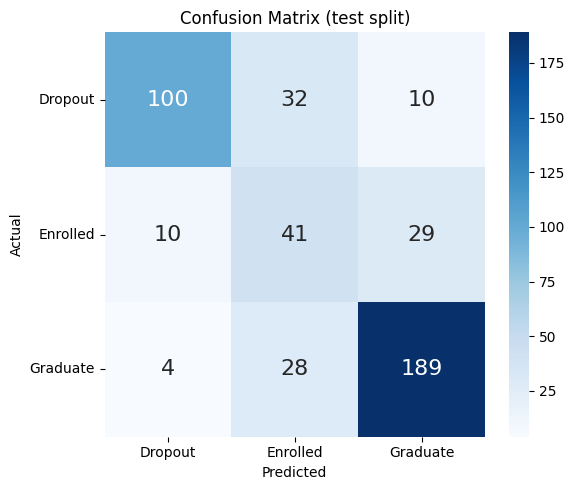

In [ ]:
def plot_confusion_matrix(
    y_true: np.ndarray, y_pred: np.ndarray, title: str = "Confusion Matrix (test split)"
) -> None:
    """Plot a labelled confusion matrix (rows = actual, columns = predicted)."""
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        confusion_matrix(y_true, y_pred),
        annot=True,
        annot_kws={"size": 16},
        cmap="Blues",
        fmt="d",
        xticklabels=target_encoder.classes_,  # from the encoder, not hard-coded
        yticklabels=target_encoder.classes_,
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


plot_confusion_matrix(y_test_encoded, y_pred_test)

Of 142 actual dropouts, 100 are correctly flagged, 32 are predicted as Enrolled and 10 as Graduate. Most missed dropouts are therefore confused with Enrolled, the costliest error for an early-warning system. Enrolled students are spread across all three predictions (10 / 41 / 29), and 28 Graduates are predicted as Enrolled. Only 14 non-dropouts are wrongly flagged as dropouts (10 Enrolled, 4 Graduates), which explains the high Dropout precision. This leaves room to lower the decision threshold for Dropout and trade some precision for recall (Section 7.7).

### 7.4 Diagnostics: Feature Importance

*Impurity-based importance* measures how much each model input improves the purity of the tree splits, on the training data.

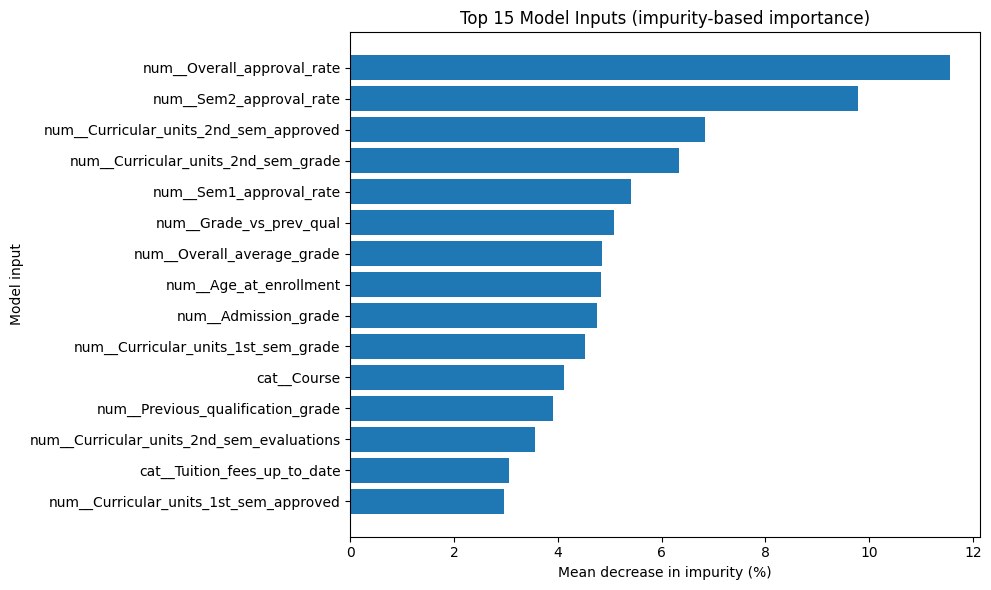

In [ ]:
# Impurity-based importance of the inputs the forest actually sees
# (encoded categories and scaled numeric features).
fitted_preprocessor = best_model.named_steps["preprocess"]
feature_importances_df = (
    pd.DataFrame(
        {
            "Feature": fitted_preprocessor.get_feature_names_out(),
            "Importance": best_model.named_steps["model"].feature_importances_ * 100,
        }
    )
    .sort_values("Importance", ascending=False)
    .head(TOP_N_FEATURES)
)

plt.figure(figsize=(10, 6))
plt.barh(feature_importances_df["Feature"], feature_importances_df["Importance"])
plt.xlabel("Mean decrease in impurity (%)")
plt.ylabel("Model input")
plt.title(f"Top {TOP_N_FEATURES} Model Inputs (impurity-based importance)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Impurity-based importance spreads credit across many correlated academic inputs: `Overall_approval_rate` (about 11.6%), `Sem2_approval_rate` (9.8%), second-semester approved units (6.8%) and grade (6.3%) lead the ranking, followed by `Sem1_approval_rate`, `Grade_vs_prev_qual`, `Overall_average_grade`, `Age_at_enrollment` and `Admission_grade` (about 5% each). `Course` (4.1%) and `Tuition_fees_up_to_date` (3.0%) rank lower. Impurity importance is measured on training data and favours numeric features with many distinct values, so it understates binary features such as tuition status.

*Permutation importance* addresses both issues. It shuffles one raw feature at a time in the **test** split and records how much macro F1 drops. Correlated features share importance, so a low value does not always mean a feature is irrelevant.

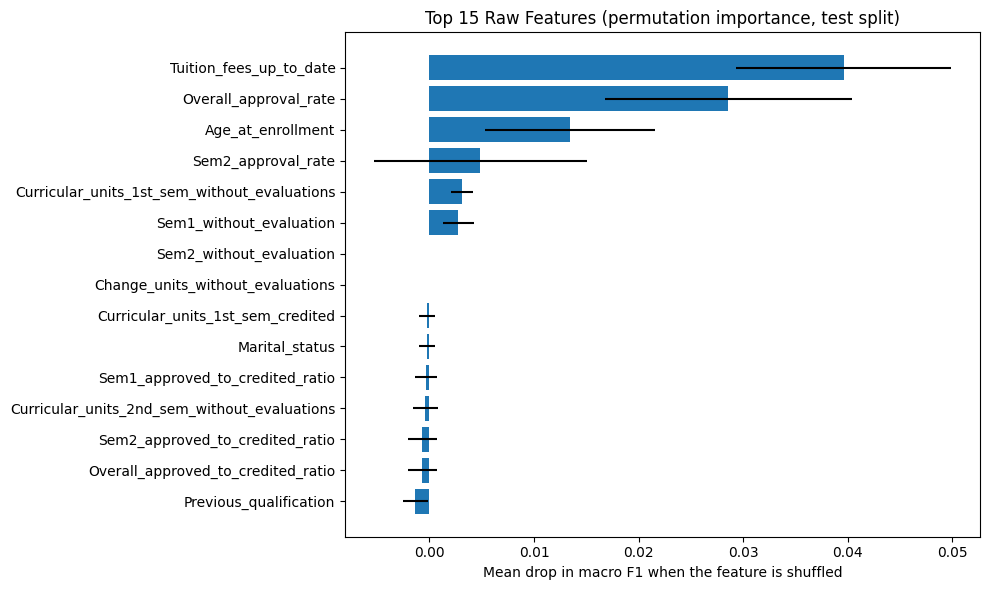

In [ ]:
def plot_permutation_importance(
    model: Pipeline, features: pd.DataFrame, target: np.ndarray, scoring="f1_macro"
) -> pd.DataFrame:
    """Plot and return the top permutation importances of raw input features.

    Each feature is shuffled ``PERMUTATION_REPEATS`` times on the given data
    (here the TEST split) and the drop in ``scoring`` is recorded. ``scoring``
    may be a scorer name or a callable ``scorer(model, X, y)``.
    """
    permutation = permutation_importance(
        model,
        features,
        target,
        scoring=scoring,
        n_repeats=PERMUTATION_REPEATS,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    importance_df = (
        pd.DataFrame(
            {
                "Feature": features.columns,
                "Mean_drop_in_F1": permutation.importances_mean,
                "Std": permutation.importances_std,
            }
        )
        .sort_values("Mean_drop_in_F1", ascending=False)
        .head(TOP_N_FEATURES)
    )

    plt.figure(figsize=(10, 6))
    plt.barh(
        importance_df["Feature"],
        importance_df["Mean_drop_in_F1"],
        xerr=importance_df["Std"],
    )
    plt.xlabel("Mean drop in macro F1 when the feature is shuffled")
    plt.title(f"Top {TOP_N_FEATURES} Raw Features (permutation importance, test split)")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
    return importance_df


# Shuffle one raw column at a time on the TEST split and record the drop in
# macro F1, measured on the features the institute recognizes.
permutation_df = plot_permutation_importance(best_model, X_test, y_test_encoded)

**Insight 17: Three factors drive the model on unseen students: tuition status, first-year approval rate and age.**

* **Finding.** Shuffling `Tuition_fees_up_to_date` lowers test macro F1 by about 0.040, `Overall_approval_rate` by about 0.029 and `Age_at_enrollment` by about 0.013. `Sem2_approval_rate` (about 0.005, with an error bar that crosses zero) and the units-without-evaluation features (about 0.003) add little. All other features, including `Course`, `Debtor`, `Scholarship_holder` and `Gender`, have importance close to zero or slightly negative.
* **Interpretation.** The ranking matches the EDA (Insights 2, 4, 5 and 9) and the likelihood-ratio test (Section 5.5.1), so criterion D4 is met. Near-zero importance for `Debtor` or `Scholarship_holder` does not mean they are unrelated to dropout (their rates differ strongly, Insight 5): their information overlaps with tuition status and approval rate, so the model does not need them once those are known.
* **Caveats.** Tuition status leads the ranking, so the timing check in Insight 5 is critical: if arrears are recorded after a student disengages, part of the model's skill is leakage. The test set is small (443 students), hence the wide error bars.
* **Business implication.** Each driver maps to an owner: tuition status to Student Financial Services, approval rate to academic advisors, and age (with entry route) to Admissions (Section 9.5).

### 7.5 Assessment Against Success Criteria (Iteration 1)

| ID | Criterion | Evidence | Status |
|---|---|---|---|
| B1 | Pipeline usable by the Streamlit app | Pipeline, target encoder and metadata saved to `artifacts/trained_models/` (Section 8.1) | Met (the app is built on these artifacts, Section 8.2) |
| B2 | Drivers explained in recognizable terms | Permutation importance on raw features: tuition status, approval rate, age (Insight 17) | Met |
| B3 | Dashboard CSV in original units | `data/processed/student.csv` saved with 4,424 rows (Section 5.2) | Met |
| D1 | Dropout recall ≥ 0.75 and > business rule | Recall 0.704 vs. rule 0.662 | **Not met** (beats the rule, misses the target by 4.6 points) |
| D2 | Macro F1 ≥ 0.70 and > majority class | Macro F1 0.692 vs. 0.222 | **Not met** (marginal: 0.8 points short) |
| D3 | CV–test gap ≤ 5 points | CV macro F1 0.717 vs. test 0.692 (2.5 points) | Met |
| D4 | Top raw factors consistent with EDA | Top 3 permutation features match Insights 2, 4, 5 and 9 | Met |

### 7.6 Process Review (Iteration 1)

**What worked**

* The leakage-safe order (split first, preprocessing inside the pipeline) produced a test score that agrees with cross-validation within 2.5 points.
* Optuna with median pruning stopped 14 of 50 weak trials early and logged every trial to a reusable JSON file.
* Keeping the original features (no compression into components) made the model's drivers readable for staff.
* The EDA rate tables anticipated the model's top drivers.

**What to revisit**

* *Overfitting:* the 21-point train–test gap and Optuna's preference for `min_samples_leaf = 1` suggest that the search space should allow stronger regularization (larger leaves, shallower trees).
* *Tuning gain:* +0.005 macro F1 over default settings; further gains must come from data and problem framing, not hyperparameters.
* *Imbalance strategy:* undersampling discards 1,839 training students; compare `class_weight="balanced"` on the full training split.
* *Enrolled class:* F1 0.45; consider a binary "Dropout vs. not" model for the early-warning use case.
* *Redundant features:* `Change_units_without_evaluations` and the credited ratios add nothing (Insights 12 and 15).
* *Financial-variable timing* and *fairness* (per-group recall for gender and age) remain open.

### 7.7 Decision (Iteration 1)

| Outcome | Decision |
|---|---|
| All D criteria met | Deploy the pipeline to the Streamlit prediction page for a one-semester pilot with advisors |
| D1 or D2 not met, but the model beats both benchmarks | Iterate: tune the Dropout decision threshold, try class weights and a binary formulation, then re-evaluate |
| Model does not beat the business rule | Use the business rule for outreach while improving the data (dropout reason, financial timing) |

**Decision: iterate.** D1 and D2 are missed, but the model beats both benchmarks and generalizes reliably (D3), so the second row applies. The quickest route to D1 is to **lower the probability threshold for Dropout**. With 87.7% precision and only 14 false alarms, a lower threshold can trade some precision for higher recall. The threshold should be chosen on cross-validated (out-of-fold) predictions, not on the test split. The current pipeline can be used in the Streamlit prototype for demonstration, but not for real advisor decisions until the iteration is complete. **Iteration 2 is implemented in Section 7.8.**

### 7.8 Iteration 2: Addressing the Unmet Criteria

Iteration 1 missed D1 (Dropout recall 0.704 vs. 0.75) and D2 (macro F1 0.692 vs. 0.70). Following the decision in Section 7.7, iteration 2 tests three changes, chosen **only with cross-validation on the training split**:

| Change | Why | Evidence |
|---|---|---|
| Tune the Dropout decision threshold | Only 14 false alarms in iteration 1, so precision can be traded for recall | Section 7.3 |
| Class weights instead of undersampling | Use all 3,981 training students instead of 2,142 | Section 5.9 |
| Regularized search space and fewer features | 21-point train–test gap; four features add nothing | Sections 7.2, 5.5.1, Insights 12 and 15 |

Two candidates are compared on the same out-of-fold predictions (*out-of-fold*: each training student is predicted by a model that did not see them during fitting):

* **Candidate A:** the iteration-1 configuration, with undersampling repeated inside each training fold.
* **Candidate B:** a new Optuna study on the full training split with class weights, larger minimum leaf sizes, shallower trees and four low-value features removed.

For each candidate, a probability threshold for Dropout is chosen on the out-of-fold predictions. The better candidate is then refitted and evaluated **once** on the test split. *(Methodological note: the test split was already used once for iteration 1, so the final test result is a second look. Selecting everything on cross-validation keeps that second look as fair as possible.)*

#### 7.8.1 Setup and Helper Functions

The full training split is encoded, the reduced feature set for Candidate B is defined, and three helpers are added. They produce out-of-fold probabilities, apply a Dropout threshold, and scan a grid of thresholds.

In [ ]:
y_train_full_encoded = target_encoder.transform(y_train_full)
v2_features = [col for col in X_train_full.columns if col not in FEATURES_TO_DROP_V2]
X_train_v2 = X_train_full[v2_features]
n_v2 = len(v2_features)
print(f"Full training split: {X_train_full.shape} | Candidate B: {n_v2} features")
display(
    pd.Series(y_train_full)
    .value_counts()
    .reindex(STATUS_ORDER)
    .rename("Training students")
)


def out_of_fold_proba(
    pipeline: Pipeline,
    features: pd.DataFrame,
    target: np.ndarray,
    cv: StratifiedKFold,
    undersample_train: bool = False,
) -> np.ndarray:
    """Return out-of-fold class probabilities for every training student.

    Each fold's validation students are predicted by a model fitted on the
    other folds only, so the probabilities behave like predictions for new
    students. With ``undersample_train=True`` the fitting part of every fold
    is balanced first, reproducing the iteration-1 training regime.

    Args:
        pipeline: Unfitted pipeline (cloned for every fold).
        features: Full training features.
        target: Encoded labels aligned with ``features``.
        cv: Cross-validation splitter.
        undersample_train: Balance the fitting part of each fold.

    Returns:
        Array of shape ``(n_students, n_classes)`` with columns in encoded order.
    """
    proba = np.zeros((len(target), len(target_encoder.classes_)))
    for train_idx, valid_idx in cv.split(features, target):
        fit_features, fit_target = features.iloc[train_idx], target[train_idx]
        if undersample_train:
            balanced = undersample(
                fit_features.assign(**{TARGET: fit_target}),
                TARGET,
                SAMPLING_RANDOM_STATE,
            )
            fit_features = balanced.drop(columns=TARGET)
            fit_target = balanced[TARGET].to_numpy()
        fitted = clone(pipeline).fit(fit_features, fit_target)
        proba[valid_idx] = fitted.predict_proba(features.iloc[valid_idx])
    return proba


def predict_with_dropout_threshold(proba: np.ndarray, threshold: float) -> np.ndarray:
    """Flag Dropout if P(Dropout) >= threshold; else pick the likelier other class.

    Lowering the threshold flags more students as at risk: recall rises and
    precision falls. The same rule is used by the Streamlit app.
    """
    others = proba.copy()
    others[:, dropout_code] = -np.inf
    return np.where(
        proba[:, dropout_code] >= threshold, dropout_code, others.argmax(axis=1)
    )


def scan_thresholds(
    y_true: np.ndarray, proba: np.ndarray, thresholds: np.ndarray = THRESHOLD_GRID
) -> pd.DataFrame:
    """Compute the evaluation metrics for every candidate Dropout threshold."""
    return pd.DataFrame(
        {
            t: classification_metrics(y_true, predict_with_dropout_threshold(proba, t))
            for t in thresholds
        }
    ).T.rename_axis("Threshold")


def choose_threshold(
    scan: pd.DataFrame, recall_target: float = DROPOUT_RECALL_TARGET
) -> float:
    """Pick the threshold with the best macro F1 among those meeting the recall target.

    If no threshold reaches the target, the one with the highest Dropout recall
    is returned, so the shortfall stays visible instead of being hidden.
    """
    eligible = scan[scan["Dropout recall"] >= recall_target]
    if eligible.empty:
        return float(scan["Dropout recall"].idxmax())
    return float(eligible["F1 (macro)"].idxmax())

Full training split: (3981, 36) | Candidate B: 32 features


,Training students
Status,
Dropout,1279
Enrolled,714
Graduate,1988


#### 7.8.2 Candidate A: Iteration-1 Configuration

The iteration-1 hyperparameters, with undersampling repeated inside each training fold, give out-of-fold probabilities on the full training split. These are directly comparable with Candidate B.

In [ ]:
oof_proba_a = out_of_fold_proba(
    build_model_pipeline(**best_params),
    X_train_full,
    y_train_full_encoded,
    cv_splitter,
    undersample_train=True,
)
display(
    (classification_metrics(y_train_full_encoded, oof_proba_a.argmax(axis=1)) * 100)
    .round(2)
    .rename("Candidate A, out-of-fold (default rule)")
)

,"Candidate A, out-of-fold (default rule)"
Accuracy,74.10
F1 (macro),70.52
F1 (weighted),75.29
Dropout recall,68.41
Dropout precision,85.62


With undersampling repeated inside each fold, the iteration-1 configuration reaches an out-of-fold macro F1 of 0.705 and a Dropout recall of 0.684 under the default "highest probability" rule. Both are close to its iteration-1 test results (0.692 and 0.704), which confirms that the out-of-fold predictions are a fair yardstick.

#### 7.8.3 Candidate B: Optuna Study with Class Weights and Regularization

A new Optuna study searches the regularized space `RF_SEARCH_SPACE_V2` on the full training split, using the same objective as Section 6.4 (macro F1, fold-by-fold pruning). `class_weight` is part of the search: `"balanced"` weights each class inversely to its size, so the smaller Enrolled and Dropout classes count more without discarding students. The trials are logged to a separate JSON file, `artifacts/tuning/optuna_tuning_results_v2.json`.

In [ ]:
if RUN_TUNING_V2:
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study_v2 = optuna.create_study(
        study_name=OPTUNA_STUDY_NAME_V2,
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
        pruner=optuna.pruners.MedianPruner(
            n_startup_trials=PRUNER_STARTUP_TRIALS, n_warmup_steps=PRUNER_WARMUP_FOLDS
        ),
    )
    study_v2.optimize(
        make_cv_objective(
            X_train_v2,
            y_train_full_encoded,
            cv_splitter,
            SEARCH_SCORING,
            search_space=RF_SEARCH_SPACE_V2,
        ),
        n_trials=N_TRIALS_V2,
    )
    save_tuning_results(
        study_v2,
        TUNING_RESULTS_V2_PATH,
        extra={
            "iteration": 2,
            "training_regime": "full training split, class weights searched",
            "features_dropped": FEATURES_TO_DROP_V2,
        },
    )
    print(f"Saved {len(study_v2.trials)} trials to {TUNING_RESULTS_V2_PATH}")

tuning_results_v2 = load_tuning_results(TUNING_RESULTS_V2_PATH)
best_params_v2 = tuning_results_v2["best_params"]
trials_v2_df = pd.DataFrame(tuning_results_v2["trials"])
print(trials_v2_df["state"].value_counts().to_string())
print(f"Best hyperparameters (v2): {best_params_v2}")
print(f"Best mean CV {SEARCH_SCORING} (v2): {tuning_results_v2['best_value']:.3f}")
display(
    trials_v2_df.query("state == 'COMPLETE'")
    .sort_values("value", ascending=False)
    .head(5)
    .round(4)
)

oof_proba_b = out_of_fold_proba(
    build_model_pipeline(v2_features, **best_params_v2),
    X_train_v2,
    y_train_full_encoded,
    cv_splitter,
)
display(
    (classification_metrics(y_train_full_encoded, oof_proba_b.argmax(axis=1)) * 100)
    .round(2)
    .rename("Candidate B, out-of-fold (default rule)")
)

Saved 50 trials to model/optuna_tuning_results_v2.json
state
COMPLETE    32
PRUNED      18
Best hyperparameters (v2): {'n_estimators': 394, 'max_depth': 14, 'max_features': 0.5, 'min_samples_split': 15, 'min_samples_leaf': 5, 'criterion': 'gini', 'class_weight': 'balanced'}
Best mean CV f1_macro (v2): 0.718


,number,state,value,folds_evaluated,param_n_estimators,param_max_depth,param_max_features,param_min_samples_split,param_min_samples_leaf,param_criterion,param_class_weight,attr_cv_score_std,datetime_start,duration_seconds
28,28,COMPLETE,0.7184,5,394,14,0.5,15,5,gini,balanced,0.0120,2026-11-18T07:48:44.507226,22.0714
45,45,COMPLETE,0.7158,5,379,30,0.5,2,8,gini,balanced,0.0082,2026-11-18T07:52:04.392516,20.8441
19,19,COMPLETE,0.7157,5,412,28,0.5,6,8,gini,balanced,0.0097,2026-11-18T07:45:56.414998,21.1664
11,11,COMPLETE,0.7154,5,355,20,0.5,13,8,gini,balanced,0.0088,2026-11-18T07:43:56.675865,19.8374
7,7,COMPLETE,0.7151,5,212,22,0.5,21,6,gini,balanced,0.0087,2026-11-18T07:42:53.782965,10.8096


,"Candidate B, out-of-fold (default rule)"
Accuracy,76.81
F1 (macro),71.85
F1 (weighted),77.05
Dropout recall,72.09
Dropout precision,85.13


Of 50 trials, 32 completed and 18 were pruned. The best configuration (trial 28) uses 394 trees, `max_depth = 14`, `max_features = 0.5`, `min_samples_split = 15`, `min_samples_leaf = 5`, `criterion = "gini"` and `class_weight = "balanced"`, with a CV macro F1 of 0.718. All five best trials use balanced class weights, the Gini criterion and half of the features per split, so the search favours class weighting over undersampling and shallower, larger-leaved trees over fully grown ones. Under the default rule, Candidate B already beats Candidate A out-of-fold on every metric (macro F1 0.719 vs. 0.705, Dropout recall 0.721 vs. 0.684, accuracy 76.8% vs. 74.1%), because it learns from all 3,981 training students.

#### 7.8.4 Decision-Threshold Tuning and Candidate Selection

By default, a student is assigned the class with the highest probability. Here a student is flagged as a dropout whenever P(Dropout) reaches a threshold; otherwise the more likely of Enrolled and Graduate is chosen. For each candidate, thresholds from 0.20 to 0.60 are scanned on the out-of-fold predictions. Among the thresholds that reach the D1 recall target (0.75), the one with the highest macro F1 is kept. The final candidate is the one that meets the recall target with the higher macro F1 (or, if neither does, the one with the higher macro F1).

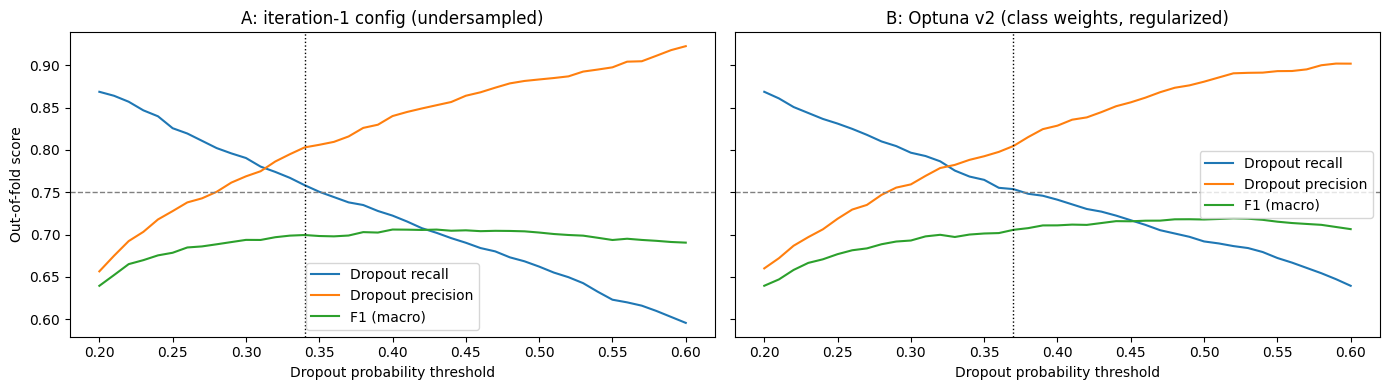

,Accuracy,F1 (macro),F1 (weighted),Dropout recall,Dropout precision
A: iteration-1 config (undersampled) | default rule,74.10,70.52,75.29,68.41,85.62
A: iteration-1 config (undersampled) | threshold 0.34,74.48,69.95,75.25,75.84,80.30
"B: Optuna v2 (class weights, regularized) | default rule",76.81,71.85,77.05,72.09,85.13
"B: Optuna v2 (class weights, regularized) | threshold 0.37",76.36,70.57,76.25,75.37,80.47


Selected: B: Optuna v2 (class weights, regularized) with Dropout threshold 0.37


In [ ]:
candidates = {
    "A: iteration-1 config (undersampled)": {
        "oof": oof_proba_a,
        "fit_X": X_train,
        "fit_y": y_train_encoded,
        "features": X_train.columns.tolist(),
        "params": best_params,
        "tuning_path": TUNING_RESULTS_PATH,
    },
    "B: Optuna v2 (class weights, regularized)": {
        "oof": oof_proba_b,
        "fit_X": X_train_v2,
        "fit_y": y_train_full_encoded,
        "features": v2_features,
        "params": best_params_v2,
        "tuning_path": TUNING_RESULTS_V2_PATH,
    },
}

threshold_scans, summary_rows = {}, {}
fig, axes = plt.subplots(1, len(candidates), figsize=(14, 4), sharey=True)
for ax, (name, spec) in zip(axes, candidates.items(), strict=True):
    scan = scan_thresholds(y_train_full_encoded, spec["oof"])
    spec["threshold"] = choose_threshold(scan)
    threshold_scans[name] = scan
    summary_rows[f"{name} | default rule"] = classification_metrics(
        y_train_full_encoded, spec["oof"].argmax(axis=1)
    )
    summary_rows[f"{name} | threshold {spec['threshold']:.2f}"] = scan.loc[
        spec["threshold"]
    ]
    scan[["Dropout recall", "Dropout precision", "F1 (macro)"]].plot(ax=ax)
    ax.axhline(DROPOUT_RECALL_TARGET, color="gray", linestyle="--", linewidth=1)
    ax.axvline(spec["threshold"], color="black", linestyle=":", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("Dropout probability threshold")
axes[0].set_ylabel("Out-of-fold score")
fig.tight_layout()
plt.show()

oof_summary = pd.DataFrame(summary_rows).T
display((oof_summary * 100).round(2))

# Prefer candidates that reach the recall target; break ties on macro F1.
final_name = max(
    candidates,
    key=lambda name: (
        threshold_scans[name].loc[candidates[name]["threshold"], "Dropout recall"]
        >= DROPOUT_RECALL_TARGET,
        threshold_scans[name].loc[candidates[name]["threshold"], "F1 (macro)"],
    ),
)
final_spec = candidates[final_name]
final_threshold = final_spec["threshold"]
print(f"Selected: {final_name} with Dropout threshold {final_threshold:.2f}")

The curves show the trade-off. Lowering the threshold raises Dropout recall (blue) and lowers precision (orange), while macro F1 (green) changes little between 0.35 and 0.55. Neither candidate reaches 0.75 recall with the default rule. Candidate A needs a threshold of 0.34 (out-of-fold recall 0.758, precision 0.803, macro F1 0.700). Candidate B reaches the target at **0.37** with a higher macro F1 (0.706; recall 0.754, precision 0.805). **Candidate B with threshold 0.37 is selected.**

#### 7.8.5 Final Model on the Test Split

The selected candidate is refitted on its training data and evaluated once on the test split with its chosen threshold. It is compared with the iteration-1 model and the two benchmarks.

,Majority class (Graduate),Business rule,Iteration 1 (default rule),Final model (threshold 0.37)
Accuracy,49.89,69.30,74.49,75.62
F1 (macro),22.19,50.35,69.21,67.99
F1 (weighted),33.21,62.20,75.22,74.80
Dropout recall,0.00,66.20,70.42,76.06
Dropout precision,0.00,83.19,87.72,83.72


              precision    recall  f1-score   support

     Dropout       0.84      0.76      0.80       142
    Enrolled       0.45      0.36      0.40        80
    Graduate       0.80      0.90      0.84       221

    accuracy                           0.76       443
   macro avg       0.69      0.67      0.68       443
weighted avg       0.75      0.76      0.75       443



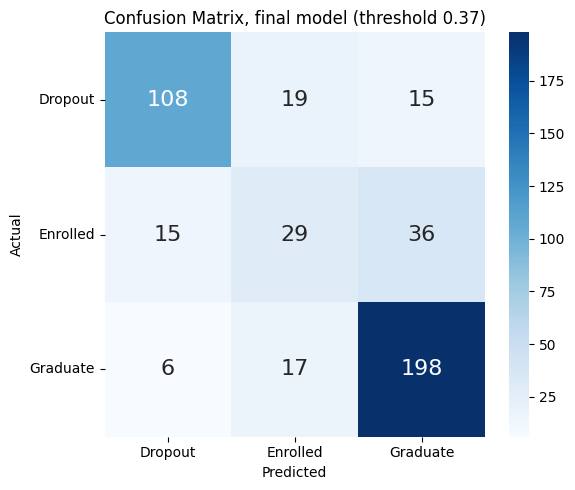

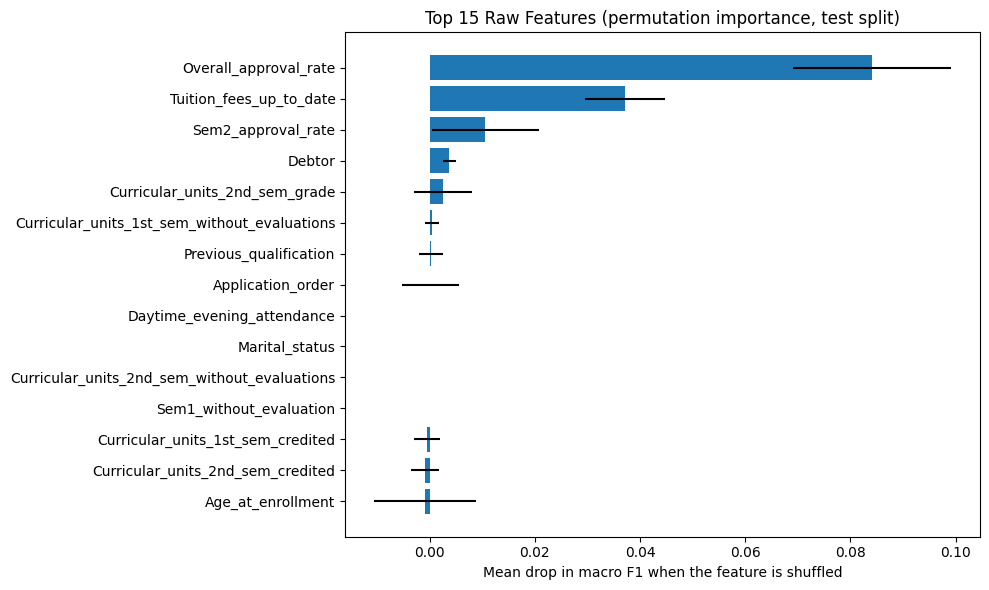

In [ ]:
final_model = build_model_pipeline(final_spec["features"], **final_spec["params"]).fit(
    final_spec["fit_X"], final_spec["fit_y"]
)
test_proba_final = final_model.predict_proba(X_test[final_spec["features"]])
y_pred_final = predict_with_dropout_threshold(test_proba_final, final_threshold)

final_comparison = benchmarks.assign(
    **{
        "Iteration 1 (default rule)": classification_metrics(
            y_test_encoded, y_pred_test
        ),
        f"Final model (threshold {final_threshold:.2f})": classification_metrics(
            y_test_encoded, y_pred_final
        ),
    }
).drop(columns="Random Forest")
display((final_comparison * 100).round(2))
print(
    classification_report(
        y_test_encoded, y_pred_final, target_names=target_encoder.classes_, digits=2
    )
)
plot_confusion_matrix(
    y_test_encoded,
    y_pred_final,
    f"Confusion Matrix, final model (threshold {final_threshold:.2f})",
)


def thresholded_macro_f1(
    model: Pipeline, features: pd.DataFrame, target: np.ndarray
) -> float:
    """Macro F1 of ``model`` under the final Dropout threshold (permutation scorer)."""
    proba = model.predict_proba(features)
    return f1_score(
        target, predict_with_dropout_threshold(proba, final_threshold), average="macro"
    )


# Permutation importance scored with the same threshold rule the app will use.
final_permutation_df = plot_permutation_importance(
    final_model,
    X_test[final_spec["features"]],
    y_test_encoded,
    scoring=thresholded_macro_f1,
)

**Insight 18: The final model trades a little precision for clearly higher dropout recall, and relies on approval rate and tuition status.**

* **Finding.** On the test split, the final model catches 76.1% of dropouts (iteration 1: 70.4%; business rule: 66.2%) with 83.7% precision (87.7%; 83.2%). Accuracy rises slightly to 75.6%, while macro F1 falls from 0.692 to 0.680, because Enrolled recall drops from 0.51 to 0.36. In the confusion matrix, 108 of 142 dropouts are flagged; 19 are predicted as Enrolled and 15 as Graduate.
* **Drivers.** Scored with the same threshold rule, permutation importance is led by `Overall_approval_rate` (about 0.084 drop in macro F1) and `Tuition_fees_up_to_date` (about 0.037), followed by `Sem2_approval_rate` (about 0.010) and `Debtor` (about 0.004). `Age_at_enrollment`, third in iteration 1, is now close to zero: the regularized model most likely takes that information from correlated features such as attendance mode, marital status and approval rates. The top drivers still match the EDA (D4).
* **Caveats.** The test split is small (142 dropouts), so a single student changes recall by 0.7 points. The timing check on tuition status (Insight 5) matters even more now that tuition status is a top-two driver.
* **Business implication.** For every 443 students, the threshold adds about 15 flags and catches 8 more actual dropouts. Whether that fits advisor capacity is the key question for Academic Affairs (Section 9.5).

#### 7.8.6 Updated Assessment and Decision

The data-mining criteria are re-assessed automatically from the outputs above. D3 compares the out-of-fold macro F1 at the chosen threshold with the test macro F1.

In [ ]:
final_metrics = classification_metrics(y_test_encoded, y_pred_final)
oof_macro_f1 = threshold_scans[final_name].loc[final_threshold, "F1 (macro)"]
rule_metrics = benchmarks["Business rule"]
majority_metrics = benchmarks["Majority class (Graduate)"]

criteria_v2 = pd.DataFrame(
    [
        {
            "ID": "D1",
            "Criterion": f"Dropout recall >= {DROPOUT_RECALL_TARGET} and > rule",
            "Evidence": f"{final_metrics['Dropout recall']:.3f} vs. rule "
            f"{rule_metrics['Dropout recall']:.3f}",
            "Met": bool(
                final_metrics["Dropout recall"] >= DROPOUT_RECALL_TARGET
                and final_metrics["Dropout recall"] > rule_metrics["Dropout recall"]
            ),
        },
        {
            "ID": "D2",
            "Criterion": f"Macro F1 >= {MACRO_F1_TARGET} and > majority class",
            "Evidence": f"{final_metrics['F1 (macro)']:.3f} vs. "
            f"{majority_metrics['F1 (macro)']:.3f}",
            "Met": bool(
                final_metrics["F1 (macro)"] >= MACRO_F1_TARGET
                and final_metrics["F1 (macro)"] > majority_metrics["F1 (macro)"]
            ),
        },
        {
            "ID": "D3",
            "Criterion": f"|CV - test| macro F1 <= {MAX_CV_TEST_GAP}",
            "Evidence": f"OOF {oof_macro_f1:.3f} vs. test "
            f"{final_metrics['F1 (macro)']:.3f}",
            "Met": bool(
                abs(oof_macro_f1 - final_metrics["F1 (macro)"]) <= MAX_CV_TEST_GAP
            ),
        },
    ]
)
display(criteria_v2)
print(f"Dropout precision on test: {final_metrics['Dropout precision']:.3f}")

,ID,Criterion,Evidence,Met
0,D1,Dropout recall >= 0.75 and > rule,0.761 vs. rule 0.662,True
1,D2,Macro F1 >= 0.7 and > majority class,0.680 vs. 0.222,False
2,D3,|CV - test| macro F1 <= 0.05,OOF 0.706 vs. test 0.680,True


Dropout precision on test: 0.837


**Interpretation and decision.**

* **D1 is now met.** The final model catches 108 of 142 dropouts on the test split (recall 0.761 vs. 0.704 in iteration 1, and 0.662 for the business rule). It misses 34 dropouts instead of 42.
* **The price is a modest loss of precision.** It flags 129 students instead of 114. Of these, 83.7% actually drop out (iteration 1: 87.7%), so there are 21 false alarms instead of 14. For every 443 students, advisors would contact 15 more students to reach 8 more actual dropouts.
* **D2 is still missed (0.680 vs. 0.70)** because of the Enrolled class. Its recall fell from 0.51 to 0.36, since the lower threshold moves borderline Enrolled students into the Dropout prediction (15 of 80) and the class-weighted model assigns many to Graduate (36 of 80). Dropout F1 rose from 0.78 to 0.80, and Graduate F1 stayed at 0.84.
* **D3 is met.** Out-of-fold macro F1 (0.706) and test macro F1 (0.680) differ by 2.6 points, so the cross-validation estimate held on new students. Overfitting is also reduced: the regularized forest (`max_depth = 14`, `min_samples_leaf = 5`) replaces fully grown trees.

**Decision.** By the rule fixed in Section 7.7, D2 is still unmet, so the formal outcome is "iterate". However, the business use case is an early-warning flag for dropout, and the criterion that measures it (D1) is now met with a precision above the business rule. **Recommended:** present the trade-off to Academic Affairs (Section 9.5) and, if the D2 shortfall on the Enrolled class is accepted, run a supervised one-semester pilot that uses **only the Dropout flag**. Advisors review every flag, and the Enrolled/Graduate predictions are not used for decisions. The final model is exported in Section 8.1 with its 0.37 threshold.

## 8. Deployment

### 8.1 Export Model Artifacts

The **final model selected in Section 7.8** (preprocessing + Random Forest), the target encoder and a metadata file are saved to `artifacts/trained_models/`. The Optuna trial logs are kept separately in `artifacts/tuning/` (`optuna_tuning_results.json` from Section 6.4 and `optuna_tuning_results_v2.json` from Section 7.8.3). The pipeline accepts raw features, so the app does not have to reproduce encoding or scaling. The metadata records the selected candidate, the feature list, the log-transformed columns, the dropped columns, the class labels, the hyperparameters, the path of the tuning log and the **decision rule**: the Dropout probability threshold that the app must apply.

In [ ]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# The pipeline bundles preprocessing + model, so the app only has to rebuild
# the engineered features (Section 5.1), apply log1p to `log_cols`, and apply
# the Dropout decision threshold below.
model_metadata = {
    "selected_candidate": final_name,
    "feature_columns": final_spec["features"],
    "log_transformed_cols": log_cols,
    "dropped_cols": sorted(
        set(DROP_COLS + weak_features)
        | (set(X_train_full.columns) - set(final_spec["features"]))
    ),
    "class_labels": target_encoder.classes_.tolist(),
    "best_params": final_spec["params"],
    "decision_rule": {
        "dropout_class": POSITIVE_CLASS,
        "dropout_threshold": float(final_threshold),
        "description": (
            "Predict Dropout if P(Dropout) >= dropout_threshold; otherwise "
            "predict the more probable of Enrolled and Graduate."
        ),
    },
    "tuning_results_path": final_spec["tuning_path"]
    .relative_to(PROJECT_ROOT)
    .as_posix(),
}
joblib.dump(final_model, MODEL_PATH)
joblib.dump(target_encoder, TARGET_ENCODER_PATH)
joblib.dump(model_metadata, MODEL_METADATA_PATH)
print(f"Saved: {MODEL_PATH}, {TARGET_ENCODER_PATH}, {MODEL_METADATA_PATH}")
print(f"Exported '{final_name}' with Dropout threshold {final_threshold:.2f}")

Saved: model/random_forest_pipeline.joblib, model/encoder_target.joblib, model/model_metadata.joblib
Exported 'B: Optuna v2 (class weights, regularized)' with Dropout threshold 0.37


### 8.2 Serving and Monitoring

**Streamlit application.** The dashboard and the prediction prototype are delivered as one multipage Streamlit app in `app/` (entry point `app/main.py`, navigation with `st.navigation` and `st.Page`), so staff use a single tool. It is started from the repository root with `streamlit run app/main.py`.

| Page | Data source | Content | Main users |
|---|---|---|---|
| Dashboard | `data/processed/student.csv` (Section 5.2) | KPI cards (students, dropout, graduation and still-enrolled rates); automatic highlights of the groups with the highest lift; dropout rate and lift by category, mirroring Section 4.4.10, with groups under 50 students marked; academic-progress distributions by status (Insights 2, 9, 13); filters by course, entry route, attendance and scholarship | Academic Affairs, programme directors, Admissions, Student Financial Services |
| Student Check | `artifacts/trained_models/random_forest_pipeline.joblib`, `encoder_target.joblib`, `model_metadata.joblib` | One-student form with a typical-student preset and two real examples; verdict with the probability of each status and the 0.37 flag line; signals to discuss (tuition arrears, debt, low approval rate, mature entry, evening attendance), each with the responsible office and a dropout rate computed from `student.csv` (Insights 2, 4, 5); plain-language reliability summary | Academic advisors / tutors |
| Batch Screening | Same artifacts as Student Check | CSV upload of a cohort (template and sample file provided, up to 5,000 rows); row-by-row validation; students ranked by Dropout probability; distribution of probabilities with the flag line; CSV download of the ranked list | Academic advisors / tutors |
| About the Model | `data/reference/model_performance.json` | How a check works, the test results of Section 7.8 in plain language, limitations (Section 9.6) and a glossary | All staff |

The app follows a Model-View-Controller layout: `app/models/` holds data access and the prediction logic (without any Streamlit dependency, so it can be tested on its own), `app/views/` renders the pages, and `app/controllers/` handles navigation, an error boundary and caching. The CSV and JSON files are cached with `st.cache_data` and the model artifacts with `st.cache_resource`, so they are read once instead of on every interaction. Readable labels replace raw codes (for example "Nursing" instead of 9500) through `data/reference/label_mappings.json`, built from the code tables in the dataset documentation (Realinho et al., 2021). The test figures shown to staff are read from `data/reference/model_performance.json`, which must be updated after every retraining.

**Serving (prediction pages).** `DropoutPredictor.predict` in `app/models/dropout_predictor.py` applies the steps of this notebook in order: (1) rebuild the engineered features with the formulas in Section 5.1 (`app/models/feature_engineering.py`), (2) apply `log1p` to the columns listed in `model_metadata["log_transformed_cols"]`, (3) select `model_metadata["feature_columns"]`, (4) call `pipeline.predict_proba()`, and (5) apply `model_metadata["decision_rule"]`: predict Dropout when P(Dropout) reaches `dropout_threshold`, otherwise the more probable of Enrolled and Graduate. Calling `pipeline.predict()` directly would ignore the tuned threshold, so the app never does. The probability of Dropout also ranks students for advisor follow-up in Batch Screening. An automated test suite (`tests/`, run with `pytest`) checks that the rebuilt features match `data/processed/student.csv`, that predictions use the 0.37 threshold, and that every page renders. Moving steps (1) and (2) into the pipeline (for example with a `FunctionTransformer`) would remove the remaining duplication between the notebook and the app.

**Refit.** After the evaluation is accepted, the pipeline can be refitted on all labelled students (training and test) with the selected hyperparameters before production use.

**Monitoring** (owner: Data & IT team):

* Track Dropout recall and precision each semester once actual outcomes are known.
* Monitor input drift, for example changes in the share of students with tuition arrears or in course mix.
* Retrain at least once per academic year, or when recall falls below the D1 target. A routine refit can reuse the stored best parameters (`RUN_TUNING = False`); re-tune with Optuna when the data change materially, and keep each JSON log under version control to compare studies.
* Review per-group error rates (gender, age band, course) every semester.

## 9. Conclusion and Recommendations

### 9.1 Conclusion

**In one sentence:** first-year approval rate and tuition-payment status are the clearest early signals of dropout, and the final Random Forest, flagging students whose dropout probability reaches 0.37, catches 76% of dropouts with 84% precision on unseen students, which meets the recall target and beats a simple business rule.

* **Goal 1 (prediction).** On 443 unseen students, the final model reaches 75.6% accuracy, 0.761 Dropout recall, 0.837 Dropout precision and 0.680 macro F1. Iteration 2 raised recall by 5.6 points over iteration 1 at the cost of 4 points of precision. Enrolled students remain hard to identify (F1 0.40).
* **Goal 2 (risk factors).** Overall approval rate (drop of about 0.084 in macro F1 when shuffled) and tuition-payment status (about 0.037) drive the final model. Tuition arrears (86.6% dropout rate) and low first-year approval rates (median 0.25 for dropouts vs. 1.00 for graduates) are confirmed by EDA, statistical tests and both models. Age, debt, scholarship, evening attendance, entry route and course are strong markers in the rate tables, but their information overlaps with the two main drivers.
* **Goal 3 (artifacts).** The dashboard CSV, the final model pipeline with its decision threshold in the metadata, and both Optuna trial logs are exported, and the Streamlit application in `app/` is built on them (Section 8.2).

### 9.2 Were the Problem Statements Answered?

1. **Early identification:** yes, for the dropout flag. The final model flags at-risk students at the end of the first year, meets the recall target (D1) and generalizes reliably (D3). The overall three-class score (D2) is just short, because of the Enrolled class.
2. **Quantified factors:** yes. Dropout rates and lifts (Section 4.4.10) and permutation importance (Insights 17 and 18) quantify the main factors (B2, D4).
3. **Operational tool:** yes. The dashboard dataset and the model pipeline are exported (B1, B3), and the Streamlit app is built on them (Section 8.2): an analytics dashboard, a single-student check, batch screening of a cohort and a plain-language explanation of the model.

### 9.3 Goals vs. Criteria

| Goal | Criteria | Result (final model) | Status |
|---|---|---|---|
| 1. Predict status | D1, D2, D3 | Recall 0.761 ✓, macro F1 0.680 ✗, CV–test gap 2.6 points ✓ | Partially met (D1, D3 met) |
| 2. Explain dropout factors | B2, D4 | Approval rate and tuition status lead; consistent with EDA | Met |
| 3. Deliver artifacts | B1, B3 | CSV, pipeline with threshold, metadata and tuning logs exported | Met (app built, Section 8.2) |

### 9.4 Impact of the Approach

Reading dropout **rates** instead of raw counts revealed that small groups (students in tuition arrears, debtors, mature entrants) carry most of the risk. Splitting before balancing replaced an inflated 79.5% accuracy with an honest estimate. A second, cross-validated iteration then turned a model that narrowly missed the recall target into one that meets it, by choosing an explicit decision threshold instead of the default "highest probability" rule. Packaging preprocessing and model together and logging both Optuna studies to JSON files make the predictions reproducible in the Streamlit app and the tuning auditable.

### 9.5 Recommendations

1. **End-of-semester-1 academic review.** Contact students with a semester-1 approval rate below 0.5 or no approved units, and offer tutoring and study-plan adjustments before semester 2. *Owner: Academic advisors / tutors.*
2. **Proactive financial support.** Reach out to students as soon as fees fall into arrears or debt is recorded, with payment plans and emergency grants, and widen scholarship access for at-risk groups. *Owner: Student Financial Services.*
3. **Targeted onboarding for high-risk routes and courses.** Provide mature-student and evening-student onboarding (flexible scheduling, mentoring) and review course-level support in Equinculture, Informatics Engineering and Management (evening). *Owner: Admissions office & programme directors.*
4. **Pilot the Streamlit app and monitor the model.** Use the app (Section 8.2), which already applies the 0.37 decision rule from the metadata, with a small group of advisors for one semester. Confirm the timing of financial variables, and track recall, precision and per-group error rates each semester (Section 8.2). A binary "Dropout vs. not" model is a candidate if the Enrolled class keeps limiting macro F1. *Owner: Data & IT team.*
5. **Decide on the pilot, targets and fairness policy.** Accept or revise the D2 target given the Enrolled-class shortfall, confirm that the extra flags (about 15 per 443 students) fit advisor capacity, approve a supervised pilot of the Dropout flag, and decide whether gender and marital status may be used for individual decisions. *Owner: Academic Affairs leadership (Vice-Rector).*

### 9.6 Limitations

* **Proxy data:** the records come from one Portuguese polytechnic (2008/2009–2018/2019); results must be re-validated on the polytechnic's data.
* **Label definition:** status is measured at the end of the normal course duration; "Enrolled" is an unfinished outcome, which explains its weak F1.
* **No dropout reason:** voluntary withdrawal and expulsion cannot be distinguished, so the brief's second question cannot be answered with this data.
* **Timing of financial variables:** tuition status is the second most important feature; if it is recorded after a student disengages, the model's skill is overstated.
* **Test split used twice:** once for iteration 1 and once for the final model. All iteration-2 choices were made on cross-validation, but the final test figures are slightly less independent than a single look.
* **Small test set:** 443 students (80 Enrolled), so class-level metrics carry noticeable uncertainty.
* **Associations, not causes:** EDA rates and model importances describe patterns, not causal effects.

Process-related lessons are reviewed in Section 7.6 and in the iteration-2 assessment (Section 7.8.6).